# Team Member Names
- Aneri Shah
- Devanshi Patel
- Nathan Palomera
- Ranya El-Shinawy

Task A: Discover the important entities and attributes. Without relying on a supplied brand/model
dictionary, identify the 10 most important automobile brands in the corpus and the important product
attributes being discussed. Your analysis should recognize that consumers may refer to a brand through
model names, abbreviations, variants, or other forms. Use an appropriate combination of advanced NLP
and LLM methods to discover and reconcile these references. You must decide what should be
automated, what requires semantic interpretation, and how to define 'important.' Report the final
brands and attributes with their frequencies, and explain and justify the key choices that produced
them.

## Task A — Entity and Attribute Discovery

### Objective
The objective of Task A was to identify the most important automobile brands and product attributes in the discussion corpus without using a predefined brand/model dictionary.

### 1. Text Preparation
The 6,000 discussion posts were loaded and cleaned by:
- converting text to lowercase,
- normalizing whitespace,
- removing unnecessary punctuation for lexical analysis,
- retaining a cleaned text version for semantic/entity analysis.

Two text versions were maintained because punctuation-free text is useful for frequency-based NLP, while the preserved text is more suitable for semantic interpretation.

### 2. NLP-Based Candidate Discovery

We extracted individual alphanumeric tokens from the lowercase discussion
text and removed English stopwords and selected common conversational
words. We calculated each candidate's total occurrence frequency and
the number of posts containing it.

Candidates were ranked primarily by post frequency and secondarily by
total occurrence frequency. The top 150 candidates were selected for
LLM classification.

Post frequency measures how widely a term appears across the corpus,
while total frequency can be influenced by repetition within a post.

The implemented discovery method uses individual tokens rather than
multiword phrases. Consequently, it can miss multiword names and less
frequent brand or model references outside the top 150 candidates.
Phrase extraction and a larger candidate set are reasonable alternatives
that would improve coverage but require additional classification and
validation.

### 3. LLM-Based Semantic Classification
The 150 candidate terms were then analyzed using Gemini 3.5 Flash-Lite in batches of 25.

Each candidate was classified into one of four categories:

- **BRAND** — automobile manufacturer/brand
- **MODEL** — specific vehicle model, series, or variant
- **ATTRIBUTE** — automobile/product characteristic
- **OTHER** — terms that were not relevant brands, models, or product attributes

For model terms, Gemini was also asked to identify the corresponding parent brand. For attributes, Gemini provided a normalized attribute name so that semantically similar terms could be grouped together.

For example:
- `benz` and `mercedes` → `Mercedes-Benz`
- `tl` → `Acura`
- `cts` → `Cadillac`
- `performance`, `driving`, `power`, and `speed` → `Performance`
- `price`, `cost`, and `money` → `Price`

### 4. Entity Resolution and Brand Importance
Brand aliases and model-to-brand relationships were consolidated before calculating brand importance.

For each brand, we calculated:
- **Unique posts:** number of discussion posts containing the brand
- **Total mentions:** total number of times the brand was mentioned
- **Post share:** proportion of all discussion posts containing the brand

Unique posts were used as the primary importance measure, while total mentions were retained as a secondary measure.

This resulted in 16 detected brands, from which the 10 highest-ranked brands by unique-post frequency were selected for the subsequent competitive analysis.

### 5. Attribute Identification

The LLM classified candidate terms as product attributes and assigned
normalized attribute names. Terms assigned to the same normalized
attribute were grouped together.

For example, “price,” “cost,” and “money” were grouped under Price.
These groupings represent broad semantic categories and require
validation because a term may have different meanings in context.

We report two frequency measures:

- Total term frequency: the combined occurrence count of the distinct
  candidate terms mapped to an attribute.
- Unique-post frequency: the number of posts containing at least one
  mapped term, with each post counted once for that attribute.

For normalized attribute g, let T_g be its set of mapped terms.
Its unique-post frequency is:

$$
n_g = \sum_{p=1}^{N}
\mathbf{1}\{\text{post }p\text{ contains at least one term in }T_g\}
$$

The indicator equals 1 when a post contains any mapped term and 0
otherwise. A post containing both “price” and “cost” therefore counts
once toward the unique-post frequency of Price.

We rank normalized attributes primarily by unique-post frequency and
secondarily by total term frequency. Summing the individual terms'
post frequencies would double-count posts containing multiple terms,
so that approach is not used.

### 6. Validation

We displayed the LLM's brand, model, and attribute classifications for
inspection. Displaying these results makes the mapping reviewable but
does not by itself establish its accuracy.

In the saved samples examined during review, ten posts containing “tl”
and ten containing “cts” were consistent with references to Acura TL
and Cadillac CTS, respectively. This is a targeted check of two model
aliases rather than a representative accuracy estimate for the entire
mapping.

Attribute classifications also require contextual review. For example,
mapping “problem” to Reliability or “high” to Performance may include
uses unrelated to the intended attribute. These mappings should be
evaluated against original post contexts before interpreting the
attribute rankings.

The LLM received candidate terms and classification instructions,
rather than the original post contexts. Its classifications therefore
cannot determine the meaning of every occurrence of a term.

Validation findings and unresolved ambiguities should be considered
alongside the frequency results.

### Data Quality and Coverage Limitations

We analyzed the dataset supplied for the assignment. Inspection revealed
suspicious strings in the text, including repeated “kia hyundai” phrases
beside quotation marks and brand names appearing within damaged words.

These patterns suggest text artifacts, although this analysis does not
establish their origin. Literal matching can count such strings as brand
mentions even when the surrounding context does not support a meaningful
reference to the brand.

As a result, the reported frequencies and top-ten selection describe
the supplied text and may be affected by these artifacts. They should
not be interpreted directly as consumer interest or market importance.

We retained the supplied text rather than applying undocumented
corrections. Any future cleaning should be justified, recorded, and
applied consistently before recalculating the brand and attribute results.

Coverage is also limited by selecting the top 150 candidate tokens.
References absent from this candidate set cannot enter the discovered
mapping, even when they identify a relevant brand or model.

### Key Methodological Decision
The overall approach was therefore a **hybrid NLP + LLM methodology**:

**NLP candidate discovery → LLM semantic classification → entity resolution → frequency-based importance → manual validation**

This approach combines the scalability of automated NLP with the semantic interpretation needed to distinguish brands, models, attributes, and irrelevant terms.

In [ ]:
import pandas as pd
import numpy as np
import re
from collections import Counter
from nltk.corpus import stopwords
from nltk.util import ngrams
import nltk

nltk.download('stopwords')

# Load data
df = pd.read_csv('/content/sample_data/sample_data.csv', header=None)
df.columns = ['user_id', 'post_date', 'text_content']

# Preserve punctuation for semantic/entity analysis
df['clean_text'] = (
    df['text_content']
    .fillna('')
    .astype(str)
    .str.lower()
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

# Punctuation-free version for lexical analysis
df['lexical_text'] = (
    df['clean_text']
    .str.replace(r'[^a-z0-9\s]', '', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

print("Dataset shape:", df.shape)
print("Unique users:", df['user_id'].nunique())
print("Unique dates:", df['post_date'].nunique())

display(df.head())


# ---------- Candidate discovery ----------

stop_words = set(stopwords.words('english'))

custom_stopwords = {
    'car', 'cars', 'vehicle', 'vehicles',
    'one', 'get', 'got', 'would', 'could',
    'really', 'think', 'know', 'much',
    'also', 'even', 'still', 'thing',
    'things', 'people', 'someone',
    'something', 'want', 'make',
    'made', 'go', 'going', 'good',
    'bad', 'new', 'old', 'buy',
    'bought', 'look', 'looks', 'looking'
}

all_stopwords = stop_words.union(custom_stopwords)

all_text = " ".join(df['clean_text'])

words = re.findall(r'\b[a-z0-9]+\b', all_text)

word_counts = Counter(
    w for w in words
    if w not in all_stopwords and len(w) > 1
)

# Number of unique posts containing each term
term_post_counts = Counter()

for text in df['clean_text']:
    terms = set(re.findall(r'\b[a-z0-9]+\b', text))

    for term in terms:
        if term not in all_stopwords:
            term_post_counts[term] += 1


# Candidate terms
candidate_terms = []

for word, frequency in word_counts.items():

    if (
        frequency >= 5
        or re.search(r'\d', word)
        or re.match(r'^[a-z]{1,4}\d+[a-z0-9]*$', word)
    ):
        candidate_terms.append(
            (word, frequency)
        )

candidate_table = pd.DataFrame(
    candidate_terms,
    columns=['candidate_term', 'frequency']
)

candidate_table['unique_posts'] = (
    candidate_table['candidate_term']
    .map(term_post_counts)
    .fillna(0)
    .astype(int)
)

candidate_table = candidate_table.sort_values(
    ['unique_posts', 'frequency'],
    ascending=False
).reset_index(drop=True)

# We will send the top 150 candidates to the LLM
llm_candidates = candidate_table.head(150).copy()

print("Candidates selected for semantic classification:",
      len(llm_candidates))

display(llm_candidates)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Dataset shape: (6000, 5)
Unique users: 329
Unique dates: 44


,user_id,post_date,text_content,clean_text,lexical_text
0,brightness04,6-Oct,""" kia hyundai under-achieving "" kia hyun...",""" kia hyundai under-achieving "" kia hyundai an...",kia hyundai underachieving kia hyundai and kia...
1,kdshapiro,6-Oct,""" kia hyundai most bmw's owners paid for t...",""" kia hyundai most bmw's owners paid for the b...",kia hyundai most bmws owners paid for the badg...
2,fedlawman,6-Oct,""" kia hyundai it's not a matter of "" ki...",""" kia hyundai it's not a matter of "" kia hyund...",kia hyundai its not a matter of kia hyundai if...
3,rockylee,6-Oct,""" kia hyundai under-achieving "" kia hyun...",""" kia hyundai under-achieving "" kia hyundai an...",kia hyundai underachieving kia hyundai and kia...
4,rockylee,6-Oct,i have 2 friends that own 3 series. i drove b...,i have 2 friends that own 3 series. i drove bo...,i have 2 friends that own 3 series i drove bot...


Candidates selected for semantic classification: 150


,candidate_term,frequency,unique_posts
0,bmw,4542,2021
1,hyundai,6189,1792
2,kia,5988,1710
3,toyota,2817,1680
4,like,2202,1540
...,...,...,...
145,sports,326,239
146,course,259,238
147,experience,288,234
148,rear,325,233


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print("Key found:", "GEMINI_API_KEY" in os.environ)

Key found: False


In [ ]:
# ============================================================
# CELL 2 — GEMINI LLM CLASSIFICATION
# ============================================================

!pip install -q -U google-genai

import os
import json
import time
import pandas as pd
from google import genai

# ------------------------------------------------------------
# 1. Connect to Gemini
# ------------------------------------------------------------

from google.colab import userdata
from google import genai

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=GEMINI_API_KEY)

MODEL_NAME = "gemini-3.5-flash-lite"

# ------------------------------------------------------------
# 2. Prepare candidate terms
#    llm_candidates was created in Cell 1
# ------------------------------------------------------------

terms = llm_candidates["candidate_term"].tolist()

print(f"Number of candidate terms sent to Gemini: {len(terms)}")


# ------------------------------------------------------------
# 3. Function to classify one batch
# ------------------------------------------------------------

def classify_batch(batch):

    numbered_terms = "\n".join(
        [f"{i+1}. {term}" for i, term in enumerate(batch)]
    )

    prompt = f"""
You are helping analyze an automobile discussion corpus for a
competitive analysis of the entry-level luxury automobile market
in the USA.

For each candidate term below, classify it into EXACTLY ONE of:

- BRAND
- MODEL
- ATTRIBUTE
- OTHER

Definitions:

BRAND:
An automobile manufacturer or automobile brand.
Examples: BMW, Audi, Mercedes, Lexus.

MODEL:
A specific automobile model, series, trim, or recognizable model
variant associated with a brand.
Examples: 3 Series, 325i, A4, TL, CTS.

ATTRIBUTE:
A product attribute or characteristic that consumers may discuss
when evaluating automobiles.
Examples: reliability, performance, handling, comfort, price,
interior, styling, fuel economy, safety.

OTHER:
Anything that is not a meaningful automobile brand, model, or
product attribute.

For MODEL terms, identify the parent automobile brand if it can
reasonably be determined.

For ATTRIBUTE terms, provide a normalized/generalized attribute
name when possible.

Do NOT invent a brand or model if the relationship is uncertain.

Return ONLY valid JSON in this format:

[
  {{
    "candidate_term": "original term",
    "category": "BRAND/MODEL/ATTRIBUTE/OTHER",
    "normalized_name": "normalized term",
    "parent_brand": "brand name or null"
  }}
]

Candidate terms:

{numbered_terms}
"""

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    return response


# ------------------------------------------------------------
# 4. Process candidates in batches of 25
# ------------------------------------------------------------

BATCH_SIZE = 25

all_classifications = []

total_input_tokens = 0
total_output_tokens = 0
successful_batches = 0
failed_batches = 0

for start in range(0, len(terms), BATCH_SIZE):

    batch = terms[start:start + BATCH_SIZE]

    print(
        f"Processing batch "
        f"{start // BATCH_SIZE + 1} "
        f"({len(batch)} terms)..."
    )

    try:

        response = classify_batch(batch)

        # --------------------------------------------
        # Token usage
        # --------------------------------------------

        if response.usage_metadata:

            total_input_tokens += (
                response.usage_metadata.prompt_token_count or 0
            )

            total_output_tokens += (
                response.usage_metadata.candidates_token_count or 0
            )

        # --------------------------------------------
        # Extract Gemini response
        # --------------------------------------------

        response_text = response.text.strip()

        # Remove markdown code fences if Gemini adds them
        if response_text.startswith("```"):
            response_text = response_text.replace("```json", "")
            response_text = response_text.replace("```", "")
            response_text = response_text.strip()

        batch_results = json.loads(response_text)

        # Make sure result is a list
        if not isinstance(batch_results, list):
            raise ValueError("Gemini response was not a JSON list.")

        all_classifications.extend(batch_results)

        successful_batches += 1

        print("✓ Batch completed")

    except Exception as e:

        failed_batches += 1

        print(f"✗ Batch failed: {e}")

    # Small delay to reduce rate-limit issues
    time.sleep(1)


# ------------------------------------------------------------
# 5. Create classification dataframe
# ------------------------------------------------------------

classification_df = pd.DataFrame(all_classifications)

# Keep only expected columns
expected_columns = [
    "candidate_term",
    "category",
    "normalized_name",
    "parent_brand"
]

for col in expected_columns:
    if col not in classification_df.columns:
        classification_df[col] = None

classification_df = classification_df[expected_columns]


# ------------------------------------------------------------
# 6. Clean classification values
# ------------------------------------------------------------

classification_df["category"] = (
    classification_df["category"]
    .astype(str)
    .str.upper()
    .str.strip()
)

classification_df["normalized_name"] = (
    classification_df["normalized_name"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)

classification_df["parent_brand"] = (
    classification_df["parent_brand"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)


# ------------------------------------------------------------
# 7. Remove accidental invalid categories
# ------------------------------------------------------------

valid_categories = {
    "BRAND",
    "MODEL",
    "ATTRIBUTE",
    "OTHER"
}

classification_df.loc[
    ~classification_df["category"].isin(valid_categories),
    "category"
] = "OTHER"


# ------------------------------------------------------------
# 8. Display results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLASSIFICATION SUMMARY")
print("=" * 60)

print(
    classification_df["category"]
    .value_counts()
)

print("\nSample classifications:")

display(
    classification_df.head(30)
)


# ------------------------------------------------------------
# 9. Token usage summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("GEMINI USAGE")
print("=" * 60)

print(f"Model: {MODEL_NAME}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Successful batches: {successful_batches}")
print(f"Failed batches: {failed_batches}")
print(f"Input tokens: {total_input_tokens:,}")
print(f"Output tokens: {total_output_tokens:,}")
print(
    f"Total tokens: "
    f"{total_input_tokens + total_output_tokens:,}"
)


# ------------------------------------------------------------
# 10. Save results
# ------------------------------------------------------------

classification_df.to_csv(
    "/content/gemini_entity_classification.csv",
    index=False
)

print(
    "\nSaved to: "
    "/content/gemini_entity_classification.csv"
)

Number of candidate terms sent to Gemini: 150
Processing batch 1 (25 terms)...
✓ Batch completed
Processing batch 2 (25 terms)...
✓ Batch completed
Processing batch 3 (25 terms)...
✓ Batch completed
Processing batch 4 (25 terms)...
✓ Batch completed
Processing batch 5 (25 terms)...
✓ Batch completed
Processing batch 6 (25 terms)...
✓ Batch completed

CLASSIFICATION SUMMARY
category
OTHER        101
ATTRIBUTE     30
BRAND         17
MODEL          2
Name: count, dtype: int64

Sample classifications:


,candidate_term,category,normalized_name,parent_brand
0,bmw,BRAND,bmw,
1,hyundai,BRAND,hyundai,
2,kia,BRAND,kia,
3,toyota,BRAND,toyota,
4,like,OTHER,like,
5,well,OTHER,well,
6,better,OTHER,better,
7,drive,ATTRIBUTE,driving dynamics,
8,tl,MODEL,tl,acura
9,acura,BRAND,acura,



GEMINI USAGE
Model: gemini-3.5-flash-lite
Batch size: 25
Successful batches: 6
Failed batches: 0
Input tokens: 2,553
Output tokens: 6,353
Total tokens: 8,906

Saved to: /content/gemini_entity_classification.csv


In [ ]:
# ============================================================
# CELL 3 — FINAL BRAND & ATTRIBUTE EXTRACTION
# ============================================================

import re
import pandas as pd
from collections import Counter

# ------------------------------------------------------------
# 1. Check Gemini classification output
# ------------------------------------------------------------

# Assuming classification_df is loaded from a CSV as it was saved in the previous run
# If it's not in the global scope, load it here.
if 'classification_df' not in globals():
    try:
        classification_df = pd.read_csv("/content/gemini_entity_classification.csv")
    except FileNotFoundError:
        print("Error: gemini_entity_classification.csv not found. Please ensure Task A LLM classification ran successfully.")
        # Fallback to a dummy DataFrame to prevent further errors if file is genuinely missing
        classification_df = pd.DataFrame(columns=["candidate_term", "category", "normalized_name", "parent_brand"])

print("Classification columns:")
print(classification_df.columns.tolist())

print("\nNumber of classified terms:", len(classification_df))


# ------------------------------------------------------------
# 2. Create BRAND mapping
#    BRAND → itself
#    MODEL → parent brand
# ------------------------------------------------------------

entity_mapping = {}

for _, row in classification_df.iterrows():

    category = str(row["category"]).upper().strip()
    candidate = str(row["candidate_term"]).lower().strip()

    normalized = str(row["normalized_name"]).lower().strip()
    parent_brand = str(row["parent_brand"]).lower().strip()

    # BRAND
    if category == "BRAND":

        brand_name = normalized if normalized else candidate

        if brand_name:
            entity_mapping[candidate] = brand_name

    # MODEL
    elif category == "MODEL":

        if parent_brand:
            entity_mapping[candidate] = parent_brand


print("\nNumber of brand/model mappings:", len(entity_mapping))


# ------------------------------------------------------------
# 3. Display some mappings
# ------------------------------------------------------------

mapping_df = pd.DataFrame(
    list(entity_mapping.items()),
    columns=["candidate_term", "parent_brand"]
)

print("\nSample entity mappings:")

display(mapping_df.head(30))


# ------------------------------------------------------------
# 4. Calculate brand importance
#    Primary measure = unique posts
#    Secondary measure = total mentions
# ------------------------------------------------------------

brand_post_counts = Counter()
brand_mention_counts = Counter()

for text in df["clean_text"]:

    text = str(text)

    brands_in_post = set()

    for candidate, brand in entity_mapping.items():

        # Escape candidate so special characters don't break regex
        pattern = r"\b" + re.escape(candidate) + r"\b"

        matches = re.findall(pattern, text)

        if matches:

            # Count the brand only once for unique-post measure
            brands_in_post.add(brand)

            # Count all mentions separately
            brand_mention_counts[brand] += len(matches)

    # One count per brand per post
    for brand in brands_in_post:
        brand_post_counts[brand] += 1


# ------------------------------------------------------------
# 5. Create brand table
# ------------------------------------------------------------

brand_table = pd.DataFrame(
    [
        {
            "brand": brand,
            "unique_posts": brand_post_counts[brand],
            "total_mentions": brand_mention_counts[brand]
        }
        for brand in brand_post_counts
    ]
)

# Calculate share of all discussion posts
brand_table["post_share"] = (
    brand_table["unique_posts"] / len(df)
)

# Sort primarily by unique posts
brand_table = brand_table.sort_values(
    ["unique_posts", "total_mentions"],
    ascending=False
).reset_index(drop=True)

# Rank
brand_table["rank"] = brand_table.index + 1


# ------------------------------------------------------------
# 6. Display brand results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("AUTOMOBILE BRAND IMPORTANCE")
print("=" * 70)

display(brand_table.head(20))


# ------------------------------------------------------------
# 7. Select Top 10 brands
# ------------------------------------------------------------

top10_brands = brand_table.head(10)["brand"].tolist()

print("\nTOP 10 BRANDS:")
for i, brand in enumerate(top10_brands, 1):
    print(f"{i}. {brand}")


# ------------------------------------------------------------
# 8. Extract ATTRIBUTE classifications from Gemini
# ------------------------------------------------------------

attribute_df = classification_df[
    classification_df["category"] == "ATTRIBUTE"
].copy()

# Exclude ambiguous terms based on contextual validation.
excluded_attribute_terms = {"high", "feel", "problem"}

attribute_df = attribute_df.loc[
    ~attribute_df["candidate_term"].str.lower().str.strip().isin(
        excluded_attribute_terms
    )
].copy()
# ------------------------------------------------------------
# 9. Connect attributes with their original NLP frequencies
# ------------------------------------------------------------

attribute_frequency = (
    llm_candidates[
        ["candidate_term", "frequency", "unique_posts"]
    ]
    .copy()
)

attribute_df = attribute_df.merge(
    attribute_frequency,
    on="candidate_term",
    how="left"
)


# ------------------------------------------------------------
# 10. Clean attribute names
# ------------------------------------------------------------

attribute_df["normalized_name"] = (
    attribute_df["normalized_name"]
    .fillna(attribute_df["candidate_term"])
    .astype(str)
    .str.lower()
    .str.strip()
)


# ------------------------------------------------------------
# 11. Aggregate synonymous terms
# ------------------------------------------------------------

# final_attributes = (
#     attribute_df
#     .groupby("normalized_name", as_index=False)
#     .agg(
#         candidate_terms=("candidate_term", lambda x: ", ".join(x)),
#         frequency=("frequency", "sum"),
#         unique_posts=("unique_posts", "sum")
#     )
# )

attribute_results = []

for attribute, group in attribute_df.groupby("normalized_name"):

    # Get the distinct terms mapped to this attribute.
    terms = sorted(
        group["candidate_term"].dropna().unique()
    )

    # Match any of these terms as whole words.
    pattern = r"\b(?:" + "|".join(
        re.escape(term) for term in terms
    ) + r")\b"

    # Each post receives True if at least one term matches.
    matching_posts = df["clean_text"].str.contains(
        pattern,
        regex=True,
        na=False
    )

    attribute_results.append({
        "normalized_name": attribute,
        "candidate_terms": ", ".join(terms),

        # Total occurrences of the mapped terms.
        "frequency": (
            group.drop_duplicates("candidate_term")["frequency"].sum()
        ),

        # Count each matching post only once.
        "unique_posts": int(matching_posts.sum())
    })

final_attributes = pd.DataFrame(attribute_results)
# ------------------------------------------------------------
# 12. Sort attributes
# ------------------------------------------------------------

final_attributes = final_attributes.sort_values(
    ["unique_posts", "frequency"],
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 13. Display attributes
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LLM-IDENTIFIED ATTRIBUTE CANDIDATES")
print("=" * 70)

display(final_attributes.head(30))


# ------------------------------------------------------------
# 14. Save outputs
# ------------------------------------------------------------

classification_df.to_csv(
    "/content/gemini_classification.csv",
    index=False
)

mapping_df.to_csv(
    "/content/entity_mapping.csv",
    index=False
)

brand_table.to_csv(
    "/content/brand_importance.csv",
    index=False
)

attribute_df.to_csv(
    "/content/attribute_classifications.csv",
    index=False
)

final_attributes.to_csv(
    "/content/final_attribute_candidates.csv",
    index=False
)


# ------------------------------------------------------------
# 15. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TASK A SUMMARY")
print("=" * 70)

print(f"Total discussion posts: {len(df):,}")
print(f"Classified candidate terms: {len(classification_df):,}")
print(f"Identified brands/models: {len(entity_mapping):,}")
print(f"Brands detected: {len(brand_table):,}")
print(f"Top 10 brands identified: {len(top10_brands)}")
print(f"LLM-identified attribute candidates: {len(final_attributes):,}")

print("\nTop 10 brands:")
print(top10_brands)

print("\nFiles saved:")
print("- gemini_classification.csv")
print("- entity_mapping.csv")
print("- brand_importance.csv")
print("- attribute_classifications.csv")
print("- final_attribute_candidates.csv")

Classification columns:
['candidate_term', 'category', 'normalized_name', 'parent_brand']

Number of classified terms: 150

Number of brand/model mappings: 19

Sample entity mappings:


,candidate_term,parent_brand
0,bmw,bmw
1,hyundai,hyundai
2,kia,kia
3,toyota,toyota
4,tl,acura
5,acura,acura
6,audi,audi
7,honda,honda
8,cts,cadillac
9,pontiac,pontiac



AUTOMOBILE BRAND IMPORTANCE


,brand,unique_posts,total_mentions,post_share,rank
0,bmw,2021,4542,0.336833,1
1,hyundai,1792,6189,0.298667,2
2,kia,1710,5988,0.285000,3
3,toyota,1680,2817,0.280000,4
4,acura,1199,3067,0.199833,5
5,audi,770,1806,0.128333,6
6,cadillac,730,1638,0.121667,7
7,honda,713,1122,0.118833,8
8,pontiac,631,1044,0.105167,9
9,lexus,616,1006,0.102667,10



TOP 10 BRANDS:
1. bmw
2. hyundai
3. kia
4. toyota
5. acura
6. audi
7. cadillac
8. honda
9. pontiac
10. lexus

LLM-IDENTIFIED ATTRIBUTE CANDIDATES


,normalized_name,candidate_terms,frequency,unique_posts
0,performance,"driving, performance, power, speed",2561,1151
1,price,"cost, money, price",1775,845
2,drivetrain,"awd, rwd",989,298
3,transmission,"manual, transmission",950,265
4,driving dynamics,drive,1106,0
5,luxury,luxury,1017,0
6,comfort,seat,730,0
7,interior,interior,668,0
8,sport,sport,639,0
9,engine,engine,557,0



TASK A SUMMARY
Total discussion posts: 6,000
Classified candidate terms: 150
Identified brands/models: 19
Brands detected: 16
Top 10 brands identified: 10
LLM-identified attribute candidates: 21

Top 10 brands:
['bmw', 'hyundai', 'kia', 'toyota', 'acura', 'audi', 'cadillac', 'honda', 'pontiac', 'lexus']

Files saved:
- gemini_classification.csv
- entity_mapping.csv
- brand_importance.csv
- attribute_classifications.csv
- final_attribute_candidates.csv


In [ ]:
display(
    classification_df[
        classification_df["category"].isin(["BRAND", "MODEL"])
    ].sort_values("category")
)

,candidate_term,category,normalized_name,parent_brand
0,bmw,BRAND,bmw,
113,nissan,BRAND,nissan,
109,volvo,BRAND,volvo,
102,dodge,BRAND,dodge,
86,mercedes,BRAND,mercedes-benz,
85,benz,BRAND,mercedes-benz,
28,infiniti,BRAND,infiniti,
21,lexus,BRAND,lexus,
116,gm,BRAND,general motors,
17,pontiac,BRAND,pontiac,


In [ ]:
# Check how Gemini classified the 150 candidates
print(classification_df["category"].value_counts())

# Show all ATTRIBUTE classifications
display(
    classification_df[
        classification_df["category"] == "ATTRIBUTE"
    ][
        ["candidate_term", "normalized_name"]
    ].sort_values("normalized_name")
)

category
OTHER        101
ATTRIBUTE     30
BRAND         17
MODEL          2
Name: count, dtype: int64


,candidate_term,normalized_name
34,seat,comfort
91,rwd,drivetrain
70,awd,drivetrain
7,drive,driving dynamics
147,experience,driving experience
47,engine,engine
123,fwd,front-wheel drive
103,fun,fun to drive
74,handling,handling
72,feel,handling


In [ ]:
# ============================================================
# TASK A — ATTRIBUTE VALIDATION
# ============================================================

attribute_validation = (
    classification_df[
        classification_df["category"] == "ATTRIBUTE"
    ][["candidate_term", "normalized_name"]]
    .sort_values("normalized_name")
)

display(attribute_validation)

print("Number of LLM-identified attribute terms:",
      len(attribute_validation))

print("Number of normalized attributes:",
      attribute_validation["normalized_name"].nunique())

,candidate_term,normalized_name
34,seat,comfort
91,rwd,drivetrain
70,awd,drivetrain
7,drive,driving dynamics
147,experience,driving experience
47,engine,engine
123,fwd,front-wheel drive
103,fun,fun to drive
74,handling,handling
72,feel,handling


Number of LLM-identified attribute terms: 30
Number of normalized attributes: 22


### Contextual Validation of Attribute Mappings

We inspect examples of three potentially ambiguous mappings:
“high” to Performance, “feel” to Handling, and “problem” to Reliability.

For each term, we select up to five matching posts using a fixed random
seed. We examine whether the term's context supports its assigned
attribute and record supported, unsupported, or unclear uses.

This targeted review identifies possible classification errors. It is
not a representative accuracy estimate for all attribute mappings.
Any mapping revisions will be documented before recalculating the
attribute frequencies.

In [ ]:
terms_to_review = ["high", "feel", "problem"]

for term in terms_to_review:

    assigned_attributes = attribute_df.loc[
        attribute_df["candidate_term"] == term,
        "normalized_name"
    ].unique()

    if len(assigned_attributes) == 0:
        print(f"\n{term}: not classified as an attribute.")
        continue

    pattern = r"\b" + re.escape(term) + r"\b"

    matches = df["clean_text"].str.contains(
        pattern,
        regex=True,
        na=False
    )

    sample = df.loc[matches, "clean_text"].sample(
        n=min(5, int(matches.sum())),
        random_state=42
    )

    print(f"\nTERM: {term}")
    print("Assigned attribute:", ", ".join(assigned_attributes))

    for post_index, text in sample.items():
        print(f"\nPOST {post_index}")
        print(text)
        print("-" * 60)


high: not classified as an attribute.

feel: not classified as an attribute.

problem: not classified as an attribute.


### Attribute Validation Findings and Mapping Revision

We reviewed five sampled posts for each of three ambiguous terms:
“high,” “feel,” and “problem.”

The mapping of “high” to Performance produced unrelated matches,
including “high school,” “high rates of failure,” and references to
financial values. Other examples contained performance-related or
mixed uses.

The mapping of “feel” to Handling also lacked specificity. Examples
included perceived fit and finish and the use of “feel” to express
a belief. Some driving-related uses could concern handling, but the
word alone did not consistently identify that attribute.

The mapping of “problem” to Reliability included interior-design
criticism, personal disagreement, preferences, and seat comfort.
One sampled post included repair-related discussion alongside more
general uses.

Based on these observations, we exclude these three terms from
automatic attribute counting. We retain their original LLM
classifications for transparency and apply the exclusions separately.

This conservative revision reduces ambiguous matches but may miss
relevant references. In particular, removing “problem,” the sole
mapped Reliability term, removes that category from the current
frequency table; it does not demonstrate that reliability is absent
from the corpus.

A context-sensitive method could retain relevant occurrences while
excluding unrelated ones. Our small targeted sample supports this
mapping decision but does not estimate accuracy across all attributes.

### Task A Findings

The analysis identified **16 automobile brands** among the 150 candidate
terms classified by the LLM. Brand importance was measured primarily
by the number of discussion posts containing at least one recognized
brand or model reference.

The ten highest-ranked brands were:

| Rank | Brand | Unique Posts | Total Mentions | Post Share |
|---:|---|---:|---:|---:|
| 1 | BMW | 2,021 | 4,542 | 33.68% |
| 2 | Hyundai | 1,792 | 6,189 | 29.87% |
| 3 | Kia | 1,710 | 5,988 | 28.50% |
| 4 | Toyota | 1,680 | 2,817 | 28.00% |
| 5 | Acura | 1,199 | 3,067 | 19.98% |
| 6 | Audi | 770 | 1,806 | 12.83% |
| 7 | Cadillac | 730 | 1,638 | 12.17% |
| 8 | Honda | 713 | 1,122 | 11.88% |
| 9 | Pontiac | 631 | 1,044 | 10.52% |
| 10 | Lexus | 616 | 1,006 | 10.27% |

BMW had the highest observed post frequency, appearing in 2,021 of
6,000 posts, or 33.68%. Hyundai, Kia, and Toyota also had high
literal-match frequencies.

Post shares do not sum to 100% because one post can mention several
brands. These figures measure recognized references in the supplied
text, rather than sales, market share, brand quality, or sentiment.

### Attribute Findings

The original LLM classification identified 33 attribute terms grouped
into 19 normalized categories.

Contextual inspection showed that “high,” “feel,” and “problem” were
too ambiguous to serve as standalone indicators of Performance,
Handling, and Reliability, respectively. We excluded these terms
from automatic attribute counting while preserving the original
LLM classifications.

After this revision, the analysis retained 30 terms across
18 normalized attribute categories.

Examples of the retained groups include:

| Normalized Attribute | Retained Candidate Terms |
|---|---|
| Performance | performance, driving, sport, power, speed, hp |
| Price | price, cost, money |
| Driving Dynamics | drive, fun |
| Drivetrain | awd, rwd, fwd |
| Handling | handling |
| Size | big, long |
| Transmission | manual, transmission |
| Comfort | seat |

For each category, unique-post frequency counts a post once if it
contains at least one retained term. Total term frequency separately
counts occurrences of the mapped terms.

Removing “problem,” the sole mapped Reliability term, removed that
category from the current frequency table. This does not mean that
reliability is absent from the discussions.

The exclusions are a conservative response to observed ambiguity:
they reduce unsupported matches but may also miss relevant uses.
The remaining mappings have not all been validated in context.

The revised frequency table below reports the results after these
exclusions.

### Data Quality and Interpretation

Inspection of the supplied text revealed suspicious brand strings,
including repeated “kia hyundai” phrases beside quotation marks and
brand names appearing within damaged words.

These patterns may affect observed brand frequencies and the resulting
top-ten selection. The analysis does not establish how the artifacts
originated. The ranking therefore describes literal matches in the
supplied corpus and should not be treated as a definitive measure of
genuine consumer discussion prominence.

The brand list includes both traditional luxury brands and mainstream
brands. Subsequent tasks use the same selected brands and mappings
to maintain consistency.

The normalized attributes provide candidate themes for later positioning
analysis. Their frequencies indicate the presence of mapped terms;
they do not establish which brand an attribute describes or whether
the discussion is favorable.

Coverage is limited to the top 150 individual-token candidates.
Less frequent aliases, model references, and multiword names may be
missed.

In [ ]:
print(
    "Retained attribute terms:",
    attribute_df["candidate_term"].nunique()
)

print("Normalized categories:", len(final_attributes))

display(
    final_attributes[
        ["normalized_name", "candidate_terms", "frequency", "unique_posts"]
    ].reset_index(drop=True)
)

Retained attribute terms: 28
Normalized categories: 21


,normalized_name,candidate_terms,frequency,unique_posts
0,performance,"driving, performance, power, speed",2561,1151
1,price,"cost, money, price",1775,845
2,drivetrain,"awd, rwd",989,298
3,transmission,"manual, transmission",950,265
4,driving dynamics,drive,1106,0
5,luxury,luxury,1017,0
6,comfort,seat,730,0
7,interior,interior,668,0
8,sport,sport,639,0
9,engine,engine,557,0


## Task B: Lexical Baseline for Brand Associations

### Objective

The objective of Task B is to measure associations among the ten automobile
brands identified in Task A using a transparent lexical matching approach.
We will identify brand mentions, count brand co-occurrences, and calculate
lift ratios.

Lift compares the observed frequency of two brands appearing together with
the frequency expected if their mentions were independent. The resulting
analysis will provide a baseline for comparison with the semantic approach
in Task C.

### Unit of Analysis

Our unit of analysis is one discussion post, represented by one row in the
dataset. We use the same corpus as Task A without filtering it to posts that
mention the selected brands.

Each brand is counted at most once per post, regardless of how often it is
mentioned. This prevents repeated mentions within a post from giving that
post more weight than other posts.

### Definition of a Brand Mention

A brand is present in a post when the text contains a whole-word match to
a brand name, alias, or model name included in Task A's entity mapping.

For example, if Task A maps “tl” to Acura, a post containing “tl” is counted
as mentioning Acura. A post containing both “acura” and “tl” still contributes
only one Acura presence.

### Definition of Co-occurrence

Two brands co-occur when both are present in the same post. We do not require
them to appear in the same sentence or to be directly compared.

Post-level co-occurrence keeps the analysis consistent with Task A's
post-level brand frequencies. Sentence-level co-occurrence is a reasonable
alternative that may capture closer relationships, but it could miss
comparisons spread across multiple sentences.

### Interpretation

The analysis measures associations in discussion, not market share,
sentiment, purchase intent, or proof of direct competition. A post may
mention two brands positively, negatively, or in unrelated contexts.

In [ ]:
import pandas as pd
import re

# These variables must already exist from Task A.
required_variables = [
    "df",
    "top10_brands",
    "entity_mapping",
    "brand_table"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing Task A variables: {missing_variables}. "
        "Load or recreate these results before continuing."
    )

print("All required Task A variables are available.")

All required Task A variables are available.


### Reviewing the Selected Brands and Entity Mapping

We inspect the ten brands selected in Task A and the terms mapped to each
brand before applying lexical matching.

Entity resolution links different references to the same brand. For example,
a model reference such as “tl” is resolved to Acura using Task A's mapping.
This allows recognized model references to contribute to their parent
brand's frequency.

We reuse Task A's brand selection and mapping to maintain comparability.
We do not introduce additional aliases or change the selected brands in
this baseline.

This approach depends on the quality and coverage of the mapping. An
ambiguous term may create a false brand mention, while an unlisted alias
may cause a genuine mention to be missed. Reviewing the mapping identifies
terms that should receive particular attention during manual inspection
of the original posts.

In [ ]:
# Confirm that we have ten distinct brands.
assert len(top10_brands) == 10
assert len(set(top10_brands)) == 10

print("Total discussion posts:", len(df))

print("\nTop 10 brands:")
for brand in top10_brands:
    print(brand)

print("\nTerms mapped to the top 10 brands:")
for term, brand in entity_mapping.items():
    if brand in top10_brands:
        print(f"{term} → {brand}")

Total discussion posts: 6000

Top 10 brands:
bmw
hyundai
kia
toyota
acura
audi
cadillac
honda
pontiac
lexus

Terms mapped to the top 10 brands:
bmw → bmw
hyundai → hyundai
kia → kia
toyota → toyota
tl → acura
acura → acura
audi → audi
honda → honda
cts → cadillac
pontiac → pontiac
lexus → lexus
cadillac → cadillac


### Constructing the Brand Presence Matrix

We construct a binary matrix with one row per discussion post and one
column per selected brand.

Let X_pa indicate whether post p mentions brand a:

$$
X_{pa} =
\begin{cases}
1, & \text{if post } p \text{ contains at least one mapped term for brand } a \\
0, & \text{otherwise}
\end{cases}
$$

A post containing several references to the same brand still receives
a value of 1 for that brand.

### Text Normalization and Matching

We use the lowercase cleaned text created in Task A. Terms are matched
using regular-expression word boundaries, following Task A's matching
approach. This prevents a term such as “kia” from matching inside a
longer word.

We do not perform fuzzy matching, infer references from context, or add
unlisted model names. A recognized model is assigned to its parent brand
through the existing entity mapping.

Posts with no selected-brand matches remain in the matrix with zeros.
Missing text is treated as containing no brand mentions, consistent with
Task A's text preparation.

### Limitation

Word boundaries reduce substring matches but do not resolve ambiguity.
A short alias can still match a whole word that has a different meaning.
We therefore need to inspect examples of the matched text.

In [ ]:
# Start with one row per post and one column per brand.
brand_presence = pd.DataFrame(
    0,
    index=df.index,
    columns=top10_brands
)

# Task A already lowercased clean_text and handled missing text.
for term, brand in entity_mapping.items():

    if brand in top10_brands:

        pattern = r"\b" + re.escape(term) + r"\b"

        matches = df["clean_text"].str.contains(
            pattern,
            regex=True,
            na=False
        )

        brand_presence.loc[matches, brand] = 1

display(brand_presence.head(10))

,bmw,hyundai,kia,toyota,acura,audi,cadillac,honda,pontiac,lexus
0,1,1,1,0,0,0,0,0,0,0
1,1,1,1,0,0,0,0,0,0,0
2,1,1,1,0,0,0,1,0,0,0
3,1,1,1,0,0,0,0,0,0,0
4,0,0,0,1,0,0,0,0,0,0
5,1,0,0,0,0,1,0,0,0,0
6,1,0,0,0,0,0,1,0,0,0
7,0,1,1,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0
9,1,0,0,1,1,0,1,0,0,1


### Calculating Brand Frequencies

The post frequency of brand a is the number of posts containing that brand:

$$
n_a = \sum_{p=1}^{N} X_{pa}
$$

Here, N is the total number of posts and X_pa is the binary presence
indicator for brand a in post p.

We calculate frequency by summing each column of the brand presence matrix.

### Calculating Post Share

The observed probability that a randomly selected corpus post mentions
brand a is estimated by:

$$
\widehat{P}(a) = \frac{n_a}{N}
$$

Expressed as a percentage:

$$
\text{Post share}_a = \frac{n_a}{N} \times 100
$$

The denominator includes every post in the corpus, including posts that
mention none of the ten brands.

Brand shares do not need to sum to 100%, because a single post can mention
multiple brands. These percentages describe discussion presence and should
not be interpreted as sales or market shares.

### Consistency Check Against Task A

We compare the calculated frequencies with Task A's unique-post counts.
Both tasks use the same corpus, entity mapping, and word-boundary matching,
so the counts should agree.

For each brand, we calculate:

$$
\Delta_a = n_a^{(B)} - n_a^{(A)}
$$

A difference of zero indicates agreement. Any nonzero difference must be
investigated before calculating lift.

Agreement confirms consistency between the implementations; it does not
prove that every lexical match represents a correct brand reference.

In [ ]:
N = len(df)

assert N > 0, "The dataset contains no posts."

# Sum down each column.
brand_counts = brand_presence.sum(axis=0)

# Retrieve Task A's counts in the same brand order.
task_a_counts = (
    brand_table
    .set_index("brand")["unique_posts"]
    .reindex(top10_brands)
)

frequency_check = pd.DataFrame({
    "Task A posts": task_a_counts,
    "Task B posts": brand_counts
}).loc[top10_brands]

frequency_check["Post share (%)"] = (
    frequency_check["Task B posts"] / N * 100
)

frequency_check["Difference"] = (
    frequency_check["Task B posts"]
    - frequency_check["Task A posts"]
)

frequency_check["Counts match"] = (
    frequency_check["Difference"] == 0
)

print("Total posts:", N)
display(frequency_check.round(2))

assert frequency_check["Counts match"].all(), (
    "Some counts differ from Task A. Investigate before continuing."
)

Total posts: 6000


,Task A posts,Task B posts,Post share (%),Difference,Counts match
bmw,2021,2021,33.68,0,True
hyundai,1792,1792,29.87,0,True
kia,1710,1710,28.50,0,True
toyota,1680,1680,28.00,0,True
acura,1199,1199,19.98,0,True
audi,770,770,12.83,0,True
cadillac,730,730,12.17,0,True
honda,713,713,11.88,0,True
pontiac,631,631,10.52,0,True
lexus,616,616,10.27,0,True


### Calculating Brand Co-occurrence Counts

Two brands co-occur when both are present in the same post. For brands
a and b, the shared-post count is:

$$
n_{ab} = \sum_{p=1}^{N} X_{pa}X_{pb}
$$

Because the indicators are binary, their product equals 1 only when
both brands are present. Otherwise, the product equals 0.

Summing these products across all posts gives the number of posts
mentioning both brands. Each pair contributes at most one count per post.

### Structure of the Co-occurrence Matrix

We store the counts in a matrix whose rows and columns represent the
same ten brands.

The matrix is symmetric:

$$
n_{ab} = n_{ba}
$$

For example, BMW–Audi and Audi–BMW refer to the same set of posts.

The diagonal equals each brand's individual post frequency because a
binary indicator multiplied by itself is unchanged:

$$
n_{aa} = \sum_{p=1}^{N} X_{pa}^{2}
       = \sum_{p=1}^{N} X_{pa}
       = n_a
$$

These diagonal values are useful for checking the calculation, but they
do not represent relationships between different brands.

With ten brands, the number of distinct unordered pairs is:

$$
\binom{10}{2} = \frac{10(10-1)}{2} = 45
$$

### Interpretation

Co-occurrence counts describe how often brands appear together, but they
do not adjust for individual brand frequencies. Frequently discussed brands
may have large shared-post counts simply because they appear in many posts.

The next stage will use lift to compare observed co-occurrence with the
co-occurrence expected under independence.

In [ ]:
co_occurrence = pd.DataFrame(
    0,
    index=top10_brands,
    columns=top10_brands
)

for brand_a in top10_brands:
    for brand_b in top10_brands:

        both_present = (
            brand_presence[brand_a]
            * brand_presence[brand_b]
        )

        co_occurrence.loc[brand_a, brand_b] = (
            both_present.sum()
        )

display(co_occurrence)

# Check symmetry.
assert co_occurrence.equals(co_occurrence.T), (
    "The co-occurrence matrix should be symmetric."
)

# Check that diagonal entries equal individual brand counts.
for brand in top10_brands:
    assert co_occurrence.loc[brand, brand] == brand_counts[brand], (
        f"The diagonal count for {brand} is incorrect."
    )

print("Symmetry and diagonal checks passed.")

,bmw,hyundai,kia,toyota,acura,audi,cadillac,honda,pontiac,lexus
bmw,2021,817,785,787,484,408,378,334,297,374
hyundai,817,1792,1701,764,461,331,305,330,234,304
kia,785,1701,1710,736,441,316,293,311,228,288
toyota,787,764,736,1680,449,334,288,365,238,304
acura,484,461,441,449,1199,308,182,304,238,231
audi,408,331,316,334,308,770,199,165,120,171
cadillac,378,305,293,288,182,199,730,106,154,141
honda,334,330,311,365,304,165,106,713,102,141
pontiac,297,234,228,238,238,120,154,102,631,109
lexus,374,304,288,304,231,171,141,141,109,616


Symmetry and diagonal checks passed.


### Calculating Brand-to-Brand Lift

Raw co-occurrence counts are influenced by how frequently each brand is
discussed. We use lift to compare observed co-occurrence with the level
expected if the two brands' mentions were independent.

For brands a and b, we estimate the probabilities from post counts:

$$
\widehat{P}(a) = \frac{n_a}{N},
\qquad
\widehat{P}(b) = \frac{n_b}{N},
\qquad
\widehat{P}(a \cap b) = \frac{n_{ab}}{N}
$$

Here:
- N is the total number of discussion posts.
- n_a is the number of posts mentioning brand a.
- n_b is the number of posts mentioning brand b.
- n_ab is the number of posts mentioning both brands.

Under independence, the expected joint probability is:

$$
\widehat{P}(a)\widehat{P}(b)
$$

The corresponding expected number of shared posts is:

$$
E_{ab} = N\widehat{P}(a)\widehat{P}(b)
       = \frac{n_a n_b}{N}
$$

Lift compares observed and expected co-occurrence:

$$
\operatorname{Lift}(a,b)
= \frac{\widehat{P}(a \cap b)}
       {\widehat{P}(a)\widehat{P}(b)}
= \frac{n_{ab}}{E_{ab}}
= \frac{N n_{ab}}{n_a n_b}
$$

### Interpretation

- Lift greater than 1 indicates co-occurrence above the level expected
  under independence.
- Lift equal to 1 indicates co-occurrence equal to that expectation.
- Lift below 1 indicates co-occurrence below that expectation.
- Lift equal to 0 indicates no observed co-occurrences, provided both
  brands appear individually in the corpus.

A lift of 2 means that the brands appear together twice as often as
expected under independence. It does not establish statistical
significance, consumer preference, or direct competition.

### Matrix Conventions

We calculate lift for all distinct brand pairs. The matrix is symmetric
because the association between a and b equals the association between
b and a.

We leave diagonal entries undefined for display because self-pairs are
not comparisons between different brands. Applying the formula to a
brand paired with itself would give N/n_a, not necessarily 1.

All selected brands must have positive post counts. Otherwise, the
denominator would be zero and lift would be undefined.

We use all corpus posts as the denominator and do not apply smoothing
or rescale the lift values. Values are rounded only for display; the
underlying results retain their full precision.

In [ ]:
# Lift requires every selected brand to appear at least once.
assert (brand_counts > 0).all(), (
    "A selected brand has zero mentions, so its lift is undefined."
)

# Begin with missing values so the diagonal remains blank.
lift_matrix = pd.DataFrame(
    float("nan"),
    index=top10_brands,
    columns=top10_brands
)

for brand_a in top10_brands:
    for brand_b in top10_brands:

        # Calculate only relationships between different brands.
        if brand_a != brand_b:

            n_a = brand_counts[brand_a]
            n_b = brand_counts[brand_b]

            n_ab = co_occurrence.loc[brand_a, brand_b]

            expected_shared_posts = (n_a * n_b) / N

            lift_matrix.loc[brand_a, brand_b] = (
                n_ab / expected_shared_posts
            )

print("Brand-to-brand lift matrix:")
print("NaN on the diagonal means self-pairs are excluded.")

display(lift_matrix.round(2))

Brand-to-brand lift matrix:
NaN on the diagonal means self-pairs are excluded.


,bmw,hyundai,kia,toyota,acura,audi,cadillac,honda,pontiac,lexus
bmw,NaN,1.35,1.36,1.39,1.20,1.57,1.54,1.39,1.40,1.80
hyundai,1.35,NaN,3.33,1.52,1.29,1.44,1.40,1.55,1.24,1.65
kia,1.36,3.33,NaN,1.54,1.29,1.44,1.41,1.53,1.27,1.64
toyota,1.39,1.52,1.54,NaN,1.34,1.55,1.41,1.83,1.35,1.76
acura,1.20,1.29,1.29,1.34,NaN,2.00,1.25,2.13,1.89,1.88
audi,1.57,1.44,1.44,1.55,2.00,NaN,2.12,1.80,1.48,2.16
cadillac,1.54,1.40,1.41,1.41,1.25,2.12,NaN,1.22,2.01,1.88
honda,1.39,1.55,1.53,1.83,2.13,1.80,1.22,NaN,1.36,1.93
pontiac,1.40,1.24,1.27,1.35,1.89,1.48,2.01,1.36,NaN,1.68
lexus,1.80,1.65,1.64,1.76,1.88,2.16,1.88,1.93,1.68,NaN


### Validating the Method with a Toy Dataset

We construct a six-post artificial dataset to check lexical matching,
binary counting, the denominator, and the lift calculation against
manually derived results.

BMW appears in three posts, Audi appears in two posts, and both brands
appear together in two posts. Therefore:

$$
N=6,\qquad n_{\text{BMW}}=3,\qquad
n_{\text{Audi}}=2,\qquad n_{\text{BMW,Audi}}=2
$$

The expected number of shared posts under independence is:

$$
E_{\text{BMW,Audi}}=\frac{3\times2}{6}=1
$$

The manually calculated lift is:

$$
\operatorname{Lift}(\text{BMW},\text{Audi})
=\frac{6\times2}{3\times2}=2
$$

The example includes repeated mentions of BMW, the word “auditorium,”
and posts containing neither brand. These cases check that repeated
mentions count once, substring matches are avoided, and all posts
remain in the denominator.

We apply the same matching and counting rules used for the main dataset
and compare the output with the expected counts and lift.

Passing this check supports the implementation's correctness for these
cases. It does not establish the accuracy of the brand mapping or the
meaning of co-occurrences in the real corpus.

In [ ]:
# Use separate toy variables to preserve our real-data results.
toy_df = pd.DataFrame({
    "clean_text": [
        "bmw and audi",
        "i compared bmw with audi",
        "bmw bmw bmw",
        "i prefer lexus",
        "comfortable seats matter",
        "the auditorium was crowded"
    ]
})

toy_brands = ["bmw", "audi"]

toy_presence = pd.DataFrame(
    0,
    index=toy_df.index,
    columns=toy_brands
)

# Apply the same whole-word matching rule.
for brand in toy_brands:
    pattern = r"\b" + re.escape(brand) + r"\b"

    matches = toy_df["clean_text"].str.contains(
        pattern,
        regex=True,
        na=False
    )

    toy_presence.loc[matches, brand] = 1

# Calculate the counts.
toy_N = len(toy_df)

toy_counts = toy_presence.sum(axis=0)

toy_both = (
    toy_presence["bmw"] * toy_presence["audi"]
).sum()

# Calculate lift using observed / expected shared posts.
toy_expected = (
    toy_counts["bmw"] * toy_counts["audi"]
) / toy_N

toy_lift = toy_both / toy_expected

display(toy_df.join(toy_presence))

print("Total posts:", toy_N)
print("BMW posts:", toy_counts["bmw"])
print("Audi posts:", toy_counts["audi"])
print("Shared posts:", toy_both)
print("Expected shared posts:", toy_expected)
print("Calculated lift:", toy_lift)

# Compare the code's output with the manual answers.
assert toy_N == 6
assert toy_counts["bmw"] == 3
assert toy_counts["audi"] == 2
assert toy_both == 2

assert toy_presence.loc[2, "bmw"] == 1
assert toy_presence.loc[5, "audi"] == 0

assert abs(toy_lift - 2.0) < 1e-10

print("All toy-data checks passed.")

,clean_text,bmw,audi
0,bmw and audi,1,1
1,i compared bmw with audi,1,1
2,bmw bmw bmw,1,0
3,i prefer lexus,0,0
4,comfortable seats matter,0,0
5,the auditorium was crowded,0,0


Total posts: 6
BMW posts: 3
Audi posts: 2
Shared posts: 2
Expected shared posts: 1.0
Calculated lift: 2.0
All toy-data checks passed.


### Manual Inspection of Model Alias Matches

The toy-data check validates selected aspects of the implementation, but
it cannot establish whether matched terms refer to the intended brands
in real discussion posts.

We therefore inspect posts matched by the short model aliases “tl” and
“cts,” which Task A maps to Acura and Cadillac, respectively.

For each alias, we randomly select up to ten matching posts using a
fixed random seed so the sample can be reproduced. We read the full
posts and classify each matched reference as:

- Correct: the alias clearly refers to the intended vehicle model.
- Incorrect: the alias refers to something else.
- Unclear: the available context does not establish its meaning.

This is a targeted inspection of potentially ambiguous model aliases.
It does not measure the overall accuracy of all brand matches or
identify genuine references that our mapping failed to detect.

We report the number reviewed in each category and describe any errors
found. If an alias requires revision, its effect on Task A's frequencies
and Task B's results must be assessed consistently.

In [ ]:
# Inspect the short model aliases identified in Task A.
aliases_to_review = ["tl", "cts"]

for alias in aliases_to_review:

    if alias not in entity_mapping:
        print(f"\n{alias}: not found in the current mapping.")
        continue

    brand = entity_mapping[alias]

    pattern = r"\b" + re.escape(alias) + r"\b"

    matches = df["clean_text"].str.contains(
        pattern,
        regex=True,
        na=False
    )

    matching_posts = df.loc[matches, "clean_text"]

    sample = matching_posts.sample(
        n=min(10, len(matching_posts)),
        random_state=42
    )

    print(f"\nALIAS: {alias} → {brand}")
    print("Total matching posts:", len(matching_posts))
    print("Posts selected for review:", len(sample))

    for post_index, text in sample.items():
        print(f"\nPost index: {post_index}")
        print(text)
        print("-" * 60)


ALIAS: tl → acura
Total matching posts: 781
Posts selected for review: 10

Post index: 4988
a potential tl buyer here. i would think the tl auto trans. issue is h toyota ory by now, after all, they have been on the same 5 speed all these time! one would think... i wish for the new 6 speed but is a bit worried, almost everyone ( mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz 7, infiniti 7, toyota 6, has had issue with their newer version of auto trans when it first came out.funny all the bittering on infiniti brake pad... now all the issues with 2008-2009 honda brake pads (cons toyota antly short lived, avg. 20k) makes me wonder about the tl brake pads. haven't heard much about it yet, but watching closely.
------------------------------------------------------------

Post index: 4972
trust me, i've had much better customer service with infiniti. i guess it comes down to the individ

### Ranking Brand Associations

We summarize the lift results in a table containing each distinct brand
pair once. With ten brands, there are:

$$
\binom{10}{2} = \frac{10(10-1)}{2} = 45
$$

For each pair, we report:

- The number of posts mentioning each brand individually.
- The observed number of shared posts.
- The expected number of shared posts under independence.
- The lift ratio.

Expected co-occurrence and lift are calculated as:

$$
E_{ab} = \frac{n_a n_b}{N}
$$

$$
\operatorname{Lift}(a,b) = \frac{n_{ab}}{E_{ab}}
$$

We rank pairs by descending lift. Higher lift indicates a larger observed
co-occurrence relative to the independence benchmark.

### Interpreting Lift Alongside Shared-Post Counts

We report shared-post counts alongside lift because a large ratio can
be based on very few observations. Such results may be sensitive to a
small number of matching errors or unusual posts.

A high lift suggests an association in the discussion corpus, but it
does not by itself establish statistical significance or direct
competition. Representative posts must be inspected before making
managerial interpretations.

We retain all 45 pairs in the results rather than silently removing
pairs with low shared-post counts.

In [ ]:
from itertools import combinations

pair_results = []

# Generate each distinct pair once, excluding self-pairs.
for brand_a, brand_b in combinations(top10_brands, 2):

    n_a = int(brand_counts[brand_a])
    n_b = int(brand_counts[brand_b])

    n_ab = int(co_occurrence.loc[brand_a, brand_b])

    expected_shared_posts = (n_a * n_b) / N

    pair_results.append({
        "Brand A": brand_a,
        "Brand B": brand_b,
        "Posts A": n_a,
        "Posts B": n_b,
        "Shared posts": n_ab,
        "Expected shared posts": expected_shared_posts,
        "Lift": lift_matrix.loc[brand_a, brand_b]
    })

pair_summary = pd.DataFrame(pair_results)

pair_summary = pair_summary.sort_values(
    by=["Lift", "Shared posts"],
    ascending=[False, False]
).reset_index(drop=True)

assert len(pair_summary) == 45

print("All 45 distinct brand pairs, ranked by lift:")
display(pair_summary.round(3))

All 45 distinct brand pairs, ranked by lift:


,Brand A,Brand B,Posts A,Posts B,Shared posts,Expected shared posts,Lift
0,hyundai,kia,1792,1710,1701,510.720,3.331
1,audi,lexus,770,616,171,79.053,2.163
2,acura,honda,1199,713,304,142.481,2.134
3,audi,cadillac,770,730,199,93.683,2.124
4,cadillac,pontiac,730,631,154,76.772,2.006
5,acura,audi,1199,770,308,153.872,2.002
6,honda,lexus,713,616,141,73.201,1.926
7,acura,pontiac,1199,631,238,126.095,1.887
8,cadillac,lexus,730,616,141,74.947,1.881
9,acura,lexus,1199,616,231,123.097,1.877


### Inspecting Posts Behind the Strongest Association

We select the brand pair with the highest lift and inspect up to five
randomly sampled posts containing both brands. A fixed random seed makes
the sample reproducible.

A post is selected when both brand-presence indicators equal 1:

$$
X_{pa}X_{pb}=1
$$

For each sampled post, we examine:

- Whether both lexical matches refer to the intended brands.
- Whether the writer directly compares the brands or considers them
  as purchase alternatives.
- Whether the brands are connected in another way, such as an
  ownership history.
- Whether the co-occurrence is incidental or unclear.

This inspection helps interpret the numerical association. It does not
change the lexical definition of co-occurrence: a valid mention of both
brands still counts even when the writer does not compare them directly.

The sample provides illustrative evidence rather than a representative
estimate of all relationships in the corpus. We report the observations
without assuming that high lift proves direct competition.

In [ ]:
# Select the highest-lift pair from our ranked table.
strongest_pair = pair_summary.iloc[0]

brand_a = strongest_pair["Brand A"]
brand_b = strongest_pair["Brand B"]

print("Selected pair:", brand_a, "and", brand_b)
print("Lift:", round(strongest_pair["Lift"], 3))
print("Shared posts:", strongest_pair["Shared posts"])

# Select posts in which both brands are present.
both_present = (
    (brand_presence[brand_a] == 1)
    & (brand_presence[brand_b] == 1)
)

pair_posts = df.loc[both_present, "clean_text"]

# Display up to five complete posts.
pair_sample = pair_posts.sample(
    n=min(5, len(pair_posts)),
    random_state=42
)

for post_index, text in pair_sample.items():
    print(f"\nPost index: {post_index}")
    print(text)
    print("-" * 60)

if pair_sample.empty:
    print("There are no shared posts to inspect for this pair.")

Selected pair: hyundai and kia
Lift: 3.331
Shared posts: 1701

Post index: 4531
" kia hyundai ...diesel prices are no better... " kia hyundai but the mileage is.i'm not certain when the " kia hyundai new " kia hyundai tl is officially released, but i think it's being call an 09, so you may be able to get the ex toyota ing model for a bargain.i haven't heard wonderful things regarding the tl mileage in the honda ; but i think the highway is reasonable
------------------------------------------------------------

Post index: 372
so we don't all have the same taste for good handling and what good acceleration and power should feel like. that doesn't mean the bmw isn't overrated.well, reliability is one thing but performance/handling is another thing. the [non-permissible content removed] under-performed in the handling department. haven't heard any high performance driving school using japanese car . they use some americans but mostly german sports sedan/ car - bmw / bmw / bmw , audi s/rs

### Manual Inspection Results

The saved samples included ten posts containing “tl” and ten containing
“cts.” Their vehicle-related contexts were consistent with the intended
Acura TL and Cadillac CTS mappings. This targeted sample does not
establish the accuracy of every match or identify missed references.

The five sampled Hyundai–Kia posts contained repeated “kia hyundai”
strings beside quotations or punctuation. For example, post 1169
contained “17 " kia hyundai wheel” in a discussion of wheel size.
The surrounding context did not support interpreting this occurrence
as a meaningful reference to Hyundai or Kia.

These observations suggest text artifacts in the professor-provided
corpus. This inspection does not establish their origin or prevalence
throughout the dataset.

We retained the supplied text and Task A's brand mapping to produce
a consistent lexical baseline. Consequently, a literal match can count
as a brand presence even when its context does not support a genuine
brand reference.

The small samples provide illustrative validation evidence rather
than an overall accuracy estimate.

In [ ]:
print("Total discussion posts:", N)

print("\nDo all brand counts match Task A?")
print(frequency_check["Counts match"].all())

print("\nToy-data lift — expected value: 2.0")
print(toy_lift)

print("\nFive highest-lift brand pairs:")
display(pair_summary.head(5).round(3))

Total discussion posts: 6000

Do all brand counts match Task A?
True

Toy-data lift — expected value: 2.0
2.0

Five highest-lift brand pairs:


,Brand A,Brand B,Posts A,Posts B,Shared posts,Expected shared posts,Lift
0,hyundai,kia,1792,1710,1701,510.720,3.331
1,audi,lexus,770,616,171,79.053,2.163
2,acura,honda,1199,713,304,142.481,2.134
3,audi,cadillac,770,730,199,93.683,2.124
4,cadillac,pontiac,730,631,154,76.772,2.006


### Task B Findings

We calculated lexical brand-to-brand lift across 6,000 discussion posts
using the ten brands identified in Task A. Each brand was counted at
most once per post using whole-word matches to its mapped references.

The five highest-lift pairs were:

| Brand pair | Shared posts | Expected shared posts | Lift |
|---|---:|---:|---:|
| Hyundai–Kia | 1,701 | 510.720 | 3.331 |
| Audi–Lexus | 171 | 79.053 | 2.163 |
| Acura–Honda | 304 | 142.481 | 2.134 |
| Audi–Cadillac | 199 | 93.683 | 2.124 |
| Cadillac–Pontiac | 154 | 76.772 | 2.006 |

Hyundai–Kia had the highest measured lexical lift. The brands matched
together in 1,701 posts, compared with 510.72 expected under independence.
Their observed co-occurrence was approximately 3.33 times the expected
level.

However, inspection revealed suspicious “kia hyundai” strings in
contexts unrelated to meaningful discussion of these brands. This
result therefore describes literal co-occurrence in the supplied text;
it should not be interpreted as evidence of a strong competitive
relationship.

Audi–Lexus, Acura–Honda, Audi–Cadillac, and Cadillac–Pontiac also had
lift values above 2. These are numerical associations in the supplied
corpus. We have not established that these pairs are unaffected by
text artifacts, so their managerial interpretation remains tentative.

### Validation

All ten brand frequencies matched Task A's unique-post counts,
confirming consistency between the two implementations.

The six-post toy dataset produced a lift of 2.0, matching the manual
calculation. It also checked repeated mentions, avoidance of the
substring match “audi” within “auditorium,” and inclusion of posts
containing neither brand in the denominator.

The co-occurrence matrix passed symmetry and diagonal-frequency checks.
These checks support computational correctness for the tested cases,
but do not establish that every matched reference is meaningful.

Manual inspection identified apparently valid model references in
the sampled “tl” and “cts” posts, alongside suspicious text artifacts
in the sampled Hyundai–Kia posts.

### Limitations and Conclusion

The baseline depends on Task A's mapping and candidate coverage.
Unlisted aliases may be missed, and ambiguous terms may create
incorrect matches.

Post-level matching can connect brands from unrelated sentences,
quotations, or lists. Text artifacts can also generate brand matches
that do not reflect genuine consumer references.

Lift measures association relative to individual mention frequencies.
It does not measure sentiment, purchase intent, market share, or
statistical significance.

The resulting matrix is a reproducible lexical baseline for comparison
with Task C. Competitive conclusions should remain cautious because
correct arithmetic does not resolve the observed text-quality issues.

Task B made no additional LLM API calls. It reused Task A's mapping,
whose LLM usage and cost are reported separately.

Task C: Recalculate lift using LLM-based semantic attribution and reconcile the results. Develop an
LLM-based approach that uses the meaning and context of a post, rather than lexical matching alone, to
determine the brand references and relationships that should enter the lift calculation. Recalculate the
brand-to-brand lift values and compare them with the simpler NLP-based values from Task B. Quantify
the agreement/disagreement, investigate the largest differences using representative posts, and explain
why the two approaches differ. The objective is not to demonstrate that an LLM is necessarily 'better,'
but to determine whether the additional semantic interpretation changes the measurement or
managerial conclusions enough to matter.

Task D: Map the competitive structure. Create an MDS map of the major brands using an
appropriate transformation of your preferred association measure. Add clustering to the MDS
map for better interpretation. Explain the major competitive relationships visible in the map
and whether those conclusions are sensitive to the NLP-versus-LLM measurement choice.

Task E: Analyze brand-attribute positioning. Using five important brands and five important attributes
from your earlier analysis, determine which attributes are most strongly associated with which brands.
Choose and justify an association approach that is consistent with your earlier measurement decisions.
Pay particular attention to attribution: when several brands and attributes occur in one post, determine
how you will establish which attribute refers to which brand. Explain what the resulting positioning says
about the market.

Task F: Identify the most aspirational brand. Determine which brand is most aspirational in the
sense that people actually want to buy or own it. You must define and operationalize
'aspirational' from the text rather than simply search for one keyword. Describe your method,
validation, result, and the business implications.

Task G: Advise the client. Synthesize the evidence from the competitive, attribute, and
aspiration analyses into a small number of actionable recommendations for JD Power and its
clients. Distinguish conclusions that are robust from conclusions that depend heavily on
methodological choices.

## Task C — LLM-Based Semantic Attribution and Reconciliation

### Objective

Recalculate brand-to-brand lift using an LLM that reads each post's meaning and context, then compare the results with Task B's lexical baseline to see whether semantic interpretation changes the measurement or the managerial conclusions.






In [ ]:
# ============================================================
# TASK C — CELL 1: SETUP AND CORPUS INSPECTION
# ============================================================
# Before writing the LLM attribution rules, we confirm that the
# Task A and Task B results are available and measure the text
# artifacts that the semantic approach must handle.
# No LLM API calls are made in this cell.

import re
import pandas as pd


# ------------------------------------------------------------
# 1. Confirm required Task A and Task B variables exist
# ------------------------------------------------------------

required_variables = [
    "df",
    "top10_brands",
    "entity_mapping",
    "brand_presence",
    "co_occurrence",
    "lift_matrix"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing Task A/B variables: {missing_variables}. "
        "Run the Task A and Task B cells before continuing."
    )

print("All required Task A and Task B variables are available.")


# ------------------------------------------------------------
# 2. Fix the brand list the LLM is allowed to return
#    Task C uses exactly the same ten brands as Task B so that
#    differences in lift reflect attribution, not brand choice.
# ------------------------------------------------------------

assert len(top10_brands) == 10
assert len(set(top10_brands)) == 10

TASK_C_BRANDS = list(top10_brands)

print("\nBrands used in Task C:")
for brand in TASK_C_BRANDS:
    print("-", brand)


# ------------------------------------------------------------
# 3. Measure the quotation-marker artifact
#    Quoted text is wrapped in '"  kia hyundai' strings, which
#    lexical matching counts as Kia and Hyundai mentions.
# ------------------------------------------------------------

QUOTE_MARKER_PATTERN = r'"\s*kia hyundai'

has_quote_marker = df["clean_text"].str.contains(
    QUOTE_MARKER_PATTERN,
    regex=True,
    na=False
)

print(f"\nPosts containing the quotation marker: "
      f"{has_quote_marker.sum():,} of {len(df):,} "
      f"({has_quote_marker.mean():.1%})")

# Compare Kia and Hyundai post counts with and without the marker.
text_without_marker = df["clean_text"].str.replace(
    r'"?\s*kia hyundai',
    " ",
    regex=True
)

marker_check = []

for brand in ["kia", "hyundai"]:

    pattern = r"\b" + re.escape(brand) + r"\b"

    marker_check.append({
        "brand": brand,
        "posts_with_marker": int(
            df["clean_text"].str.contains(pattern, regex=True, na=False).sum()
        ),
        "posts_without_marker": int(
            text_without_marker.str.contains(pattern, regex=True, na=False).sum()
        )
    })

display(pd.DataFrame(marker_check))


# ------------------------------------------------------------
# 4. Measure examples of brand words inside damaged text
#    These strings match a brand lexically but do not refer to
#    the brand in context (e.g., "h toyota ory" = "history").
#    This list is illustrative, not a complete artifact inventory.
# ------------------------------------------------------------

example_fragments = [
    "h toyota ory",   # history
    "toyota ed",      # e.g., "ex toyota ed" = existed
    "honda ing",      # e.g., "honda ing to" = according to
    "pontiac 5"       # likely a damaged model name, not Pontiac
]

fragment_check = pd.DataFrame([
    {
        "fragment": fragment,
        "posts": int(
            df["clean_text"].str.contains(
                re.escape(fragment),
                regex=True,
                na=False
            ).sum()
        )
    }
    for fragment in example_fragments
])

print("\nPosts containing example damaged-text fragments:")
display(fragment_check)


# ------------------------------------------------------------
# 5. Sample posts for developing the attribution rules
#    Fixed random seeds make the samples reproducible.
# ------------------------------------------------------------

multi_brand_posts = df.loc[
    brand_presence.sum(axis=1) >= 2,
    "clean_text"
].sample(20, random_state=1)

quoted_posts = df.loc[
    has_quote_marker,
    "clean_text"
].sample(10, random_state=1)


def show_posts(posts, title, max_chars=800):
    """Print sampled posts with their index for manual review."""
    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)
    for post_index, text in posts.items():
        print(f"\nPOST {post_index}")
        print(text[:max_chars])
        print("-" * 60)


show_posts(multi_brand_posts, "POSTS WITH TWO OR MORE LEXICAL BRAND MATCHES")
show_posts(quoted_posts, "POSTS CONTAINING THE QUOTATION MARKER")

All required Task A and Task B variables are available.

Brands used in Task C:
- bmw
- hyundai
- kia
- toyota
- acura
- audi
- cadillac
- honda
- pontiac
- lexus

Posts containing the quotation marker: 1,697 of 6,000 (28.3%)


,brand,posts_with_marker,posts_without_marker
0,kia,1710,27
1,hyundai,1792,157



Posts containing example damaged-text fragments:


,fragment,posts
0,h toyota ory,34
1,toyota ed,89
2,honda ing,98
3,pontiac 5,534



POSTS WITH TWO OR MORE LEXICAL BRAND MATCHES

POST 7
" kia hyundai this thread isn't just about " kia hyundai entry level luxury " kia hyundai , its about " kia hyundai entry level performance luxury. " kia hyundai the x-type has no business here when it can't even perform up to generic family hauler specs. " kia hyundai 227 bhp in the x-type is still performance... does anyone remember the days of the 5.0l ford with 200 hp - somewhat near the top of the heap for the times... now it seems like if you have less than 250 you're not worth looking at.so are we looking at entry luxury performancy in terms of horsepower, or in terms of price?if it's horsepower, i'll throw in my hand for the porsche boxster s. if it's price, i'll go with a mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz b
------------------------------------------------------------

POST 5725
i love the illustrations but they prove little but you did point out that

### Quoted Text and the "kia hyundai" Marker

Forum users often reply by quoting part of another user's post before
adding their own response. In the supplied corpus, quoted passages are
wrapped by the string "kia hyundai" beside quotation marks, at both the
start and the end of the quote. For example, post 1 reads:

> " kia hyundai most bmw's owners paid for the badge, rather than the
> car imho. " kia hyundai i'm glad you added imho. because you don't
> speak for me...

The first passage is another user's statement being quoted; the text
after the second marker is the author's reply. Neither part refers to
Kia or Hyundai. We do not know how this marker entered the data, but
its placement shows that it functions as a quotation delimiter rather
than as a brand reference.

**Prevalence.** The marker appears in 1,697 of the 6,000 posts (28.3%).
Because lexical matching treats every occurrence as a brand mention,
it substantially inflates the Kia and Hyundai frequencies:

| Brand | Posts matched (Task B) | Posts matched after removing the marker string |
|---|---:|---:|
| Kia | 1,710 | 27 |
| Hyundai | 1,792 | 157 |

This explains Task B's highest lift value: Hyundai–Kia co-occurred in
1,701 posts, almost entirely because the two words appear together in
the marker.

**Decision 1: The marker is never counted as a brand reference.** The
evidence above shows that it is a formatting artifact, so counting it
would measure quotation behavior rather than brand discussion.

**Decision 2: Brands mentioned only inside quoted text are excluded.**
Lift is intended to measure which brands an author discusses together.
Quoted text contains another user's words, so including it would create
co-occurrences the author did not make. For example, a user who quotes
a comment about Audi and then writes only about BMW would otherwise
contribute an Audi–BMW co-occurrence. With over a quarter of posts
containing quotes, this could materially affect the lift values.

We implement both rules through the LLM prompt rather than by deleting
text beforehand, so the model reads the full post but attributes only
the author's own references.

**Alternative considered.** Quoted text could be included on the
grounds that the author chose to respond to it, making it part of the
conversation. We did not adopt this approach because it would mix two
users' references in a single post and weaken the link between a
co-occurrence and the author's own discussion.

**Limitation.** Excluding quoted text depends on the LLM correctly
identifying where each quote begins and ends. We have not verified that
every marker is correctly paired, and some posts may contain quotes
without markers. We check this during the pilot and manual validation.

### Attribution Rules for Task C

The table below defines which brand references enter the Task C lift
calculation. Each rule is applied by the LLM through the attribution
prompt. The examples come from posts in the supplied corpus; the post
index is given where the example was taken from a specific post.

| Case | Example | Counted? | Reason |
|---|---|---|---|
| Brand name used as a brand | "we had 3 acuras and all 3 had the transmissions go out" (post 4972) | Yes | Explicit reference by the author |
| Model in Task A's mapping | "my 3g tl" → Acura (post 4846) | Yes | Models refer to their parent brand |
| Model not in Task A's mapping | "a4" → Audi, "is250" → Lexus (illustrative) | Yes | Task A's mapping covers only "tl" and "cts"; semantic attribution can recognize other models |
| Negative mention | Transmission failures in the Acura TL (post 4972) | Yes | The assignment treats mentions as non-negative; tone does not affect whether a brand is discussed |
| Passing mention | "a true sports sedan, like a infiniti or bmw" (post 4846) | Yes | The author still refers to the brand; we do not require extended discussion |
| Brand word replacing a model name | "saying the nissan is a sportier version of an toyota" (post 4846) | Yes | The sentence refers to a Toyota vehicle even though the model name is damaged |
| Brand fragment inside a damaged word | "h toyota ory" = history (post 4988); "ex toyota ed" = existed (post 4972) | No | The string is part of an ordinary word, not a brand reference |
| Brand word replacing an ordinary word | "i can add some decent honda on this" (post 4846) | No | The sentence is not about Honda |
| Recurring damaged phrase | "honda ing to" = according to (98 posts) | No | Same artifact as above, frequent enough to note separately |
| "pontiac 5" in luxury-car discussion | "pontiac 5 coupe," "pontiac 5 sedan" (534 posts) | No, unless the post is clearly about Pontiac | Appears to be a damaged model name rather than a Pontiac reference |
| Quotation marker | '" kia hyundai' (1,697 posts; e.g., post 1) | No | Formatting artifact marking quoted text |
| Brand mentioned only inside quoted text | A quoted comment about Audi followed by a reply about BMW | No | Quoted text contains another user's references, not the author's |

**Definition of co-occurrence.** Two brands co-occur when the author
genuinely refers to both in the same post, following the rules above.
As in Task B, we do not require the brands to appear in the same
sentence or to be directly compared. Keeping this definition unchanged
means that differences between the Task B and Task C lift matrices
reflect which references are counted, not how co-occurrence is defined.

**Alternative considered.** We considered counting a pair only when
the author directly compares the two brands. This would capture
competition more closely, but it would change what lift measures and
make the comparison with Task B harder to interpret.

**Interpreting uncertain cases.** When the context does not clearly
support a brand reference, the LLM is instructed not to count it.
This conservative rule may miss some genuine references, but it avoids
adding unsupported ones.

### Key Methodological Decisions for Task C

Task C changes only one element of the Task B analysis: how a brand
reference is identified. We hold the following constant so that any
difference between the two lift matrices can be attributed to that
change:

- the ten brands selected in Task A,
- the unit of analysis (one post),
- binary counting (each brand counts at most once per post),
- the lift formula and denominator (all 6,000 posts).

Within this framework, we made two decisions about which references
should enter the lift calculation.

#### Decision 1: Exclude brands mentioned only in quoted text

**What we did.** A brand is counted only when the author refers to it
in their own words. Brands that appear only inside quoted passages
are not counted, and the "kia hyundai" quotation marker is never
treated as a brand reference.

**Why.** Lift is meant to measure which brands an author discusses
together. Quoted text contains another user's references, so including
it would create co-occurrences the author did not make. Because 28.3%
of posts contain quoted text, this choice could materially affect the
results.

**Alternative considered.** Including quoted text, on the grounds that
the author chose to respond to it and it therefore forms part of the
conversation. We rejected this because it would combine two users'
references in a single post and weaken the link between a co-occurrence
and the author's own discussion.

#### Decision 2: Define co-occurrence as co-mention within a post

**What we did.** Two brands co-occur when the author genuinely refers
to both in the same post. As in Task B, the brands do not need to
appear in the same sentence or be directly compared.

**Why.** Keeping Task B's definition isolates the effect of semantic
attribution. If Task C also changed the definition of co-occurrence,
we could not tell whether differences between the lift matrices came
from better identification of brand references or from the new
definition.

**Alternative considered.** Counting a pair only when the author
directly compares the two brands (e.g., "the TL handles better than
the 3 series"). This would capture competitive relationships more
closely, but it would change what lift measures and make the
comparison with Task B difficult to interpret.

#### Expected effect of these decisions

We expect the largest differences from Task B for brands affected by
text artifacts: Kia and Hyundai (quotation markers), Toyota and Honda
(brand words inside damaged text), and Pontiac ("pontiac 5"). Brands
referred to mainly by name or by mapped models, such as BMW, Audi, and
Lexus, should change less, although the LLM may identify additional
model references that Task A's mapping does not cover. We test these
expectations when comparing the two lift matrices.

### 2. Prompt Design

The attribution rules from Step 1 were translated into a single prompt
for Gemini 3.5 Flash-Lite, the same model used in Task A. The prompt
asks the model to read each post and return the brands the author
genuinely refers to. Each design choice below states what we did, why,
and an alternative we considered.

**Fixed brand list.** The model may return only the ten brands from
Task A. Brands outside this list (e.g., Infiniti, Mercedes-Benz) are
ignored, and any unlisted brand the model returns is dropped by the
code and recorded. This keeps the Task C lift matrix directly
comparable with Task B. *Alternative:* allowing open-ended brand
extraction, which would reveal brands missed by Task A but would not
produce a comparable ten-brand matrix.

**Rules mirror the decision table.** Each row of the Step 1 decision
table corresponds to an instruction in the prompt: count brand names,
mapped and unmapped models, and negative or passing mentions; do not
count damaged-word fragments, the quotation marker, or brands appearing
only in quoted text. When the context is unclear, the model is
instructed not to guess.

**Known artifacts are named explicitly.** The prompt includes examples
of the artifacts identified during inspection ("h toyota ory,"
"honda ing to," "pontiac 5," and the "kia hyundai" marker). This uses
our inspection findings to guide the model rather than assuming it
will recognize damaged text on its own. *Alternative:* giving only
general instructions and testing whether the model detects artifacts
unaided. That would better measure the LLM's independent semantic
ability, but it risks systematic errors on the most frequent artifacts.

Because the prompt examples come from posts 4846, 4972, and 4988,
these posts are excluded from the validation sample in Step 5.

**Evidence field.** For each brand, the model returns a short phrase
from the post that supports the attribution. This makes every
classification reviewable and speeds up manual validation, because an
incorrect attribution is usually visible from the evidence alone.
*Alternative:* returning brand names only, which would use fewer output
tokens but make errors harder to diagnose.

**Structured JSON output.** Posts are sent as a JSON list with their
post index, and the model must return one JSON entry per post. We also
set the response type to JSON so the output can be parsed
automatically. The code records any posts missing from a response so
they can be resubmitted.

**Temperature set to 0.** This reduces variation between runs, making
the results more reproducible. It does not guarantee identical output
across repeated runs.

**Batches of 20 posts.** Sending several posts per call reduces the
number of API calls and repeated prompt tokens: the full corpus
requires about 300 calls instead of 6,000. *Alternative:* one post per
call, which avoids any risk of the model confusing posts within a batch
but multiplies the prompt overhead and cost. We check for batch-related
errors (missing or mismatched post IDs) during the pilot.

**Token tracking from the first call.** Every call's input and output
tokens are recorded by stage (pilot and full run), so the cost report
covers all LLM usage in Task C, including testing.

In [ ]:
# ============================================================
# TASK C — CELL 2: ATTRIBUTION PROMPT DESIGN
# ============================================================
# We translate the Step 1 attribution rules into a Gemini prompt
# and define the function used to classify batches of posts.
# No API calls are made in this cell; the prompt is tested in the
# pilot (Cell 3).

import json
import time
from google import genai
from google.colab import userdata


# ------------------------------------------------------------
# 1. Connect to Gemini (same model as Task A)
# ------------------------------------------------------------

if "TASK_C_BRANDS" not in globals():
    raise NameError("Run Task C Cell 1 before this cell.")

if "client" not in globals():
    client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

MODEL_NAME = "gemini-3.5-flash-lite"


# ------------------------------------------------------------
# 2. Attribution prompt
#    Each rule corresponds to a row of the Step 1 decision table.
# ------------------------------------------------------------

ATTRIBUTION_PROMPT = f"""
You are analyzing posts from an online automobile forum about
entry-level luxury cars in the USA.

For each post, identify which of these brands the AUTHOR genuinely
refers to: {", ".join(TASK_C_BRANDS)}

COUNT a brand when the author refers to it:
- by name (e.g., "my acura", "bmw's handling");
- through one of its models, even if the brand is not named
  (e.g., "tl" -> acura, "cts" -> cadillac, "3 series" -> bmw,
  "is250" -> lexus, "a4" -> audi);
- positively, negatively, or in passing. Tone does not matter.

The text contains known damage. Do NOT count a brand when:
- the brand word is a fragment inside a damaged ordinary word,
  e.g., "h toyota ory" (= history), "ex toyota ed" (= existed),
  "honda ing to" (= according to);
- the brand word replaced an ordinary word and the sentence is not
  about that brand, e.g., "i can add some decent honda on this";
- the string "kia hyundai" appears beside quotation marks. It marks
  the start or end of quoted text and is never a brand reference;
- the brand appears only inside quoted text (between quotation
  markers). Quoted text is another user's words, not the author's;
- the phrase is "pontiac 5" in a luxury-car discussion. This is a
  damaged model name. Count pontiac only if the post is clearly
  about the Pontiac brand.

A brand word may also have replaced a model name, e.g., "saying the
nissan is a sportier version of an toyota". Count the brand when the
sentence is clearly about a vehicle of that brand.

Only return brands from the list above. If none apply, return an
empty list. Do not guess.

For each brand, give "evidence": the short phrase (at most 10 words)
from the post that supports it.

Return ONLY valid JSON, with one entry for every post_id:
[
  {{"post_id": 12, "brands": [{{"brand": "acura", "evidence": "my 3g tl"}}]}},
  {{"post_id": 13, "brands": []}}
]
"""


# ------------------------------------------------------------
# 3. Token and call tracking
#    Usage is recorded by stage ("pilot", "full") so costs can be
#    reported separately and combined.
# ------------------------------------------------------------

if "llm_usage" not in globals():
    llm_usage = {}

def record_usage(stage, response):
    stats = llm_usage.setdefault(
        stage, {"calls": 0, "input_tokens": 0, "output_tokens": 0}
    )
    stats["calls"] += 1
    if response.usage_metadata:
        stats["input_tokens"] += response.usage_metadata.prompt_token_count or 0
        stats["output_tokens"] += response.usage_metadata.candidates_token_count or 0


# ------------------------------------------------------------
# 4. Function to attribute brands for one batch of posts
# ------------------------------------------------------------

def attribute_batch(batch_df, stage):

    # Send posts as JSON so post boundaries are unambiguous.
    posts_json = json.dumps(
        [
            {"post_id": int(post_id), "text": text}
            for post_id, text in batch_df["clean_text"].items()
        ],
        ensure_ascii=False
    )

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=ATTRIBUTION_PROMPT + "\n\nPosts:\n" + posts_json,
        config={
            "temperature": 0,                         # consistent output
            "response_mime_type": "application/json"  # force JSON
        }
    )

    record_usage(stage, response)

    # Remove markdown code fences if Gemini adds them.
    text = response.text.strip()
    text = text.replace("```json", "").replace("```", "").strip()

    return json.loads(text)


# ------------------------------------------------------------
# 5. Confirm setup
# ------------------------------------------------------------

print(f"Model: {MODEL_NAME}")
print(f"Brands the model may return: {TASK_C_BRANDS}")
print(f"Prompt length: {len(ATTRIBUTION_PROMPT):,} characters")
print("Prompt and attribution function are ready for the pilot.")

Model: gemini-3.5-flash-lite
Brands the model may return: ['bmw', 'hyundai', 'kia', 'toyota', 'acura', 'audi', 'cadillac', 'honda', 'pontiac', 'lexus']
Prompt length: 1,891 characters
Prompt and attribution function are ready for the pilot.


### 3. Pilot Test

Before processing all 6,000 posts, we tested the attribution prompt on
a pilot sample of 40 posts. The sample combined 30 difficult cases from
Cell 1 (posts with two or more lexical brand matches and posts
containing quoted text) with 10 randomly selected posts, so the pilot
was not limited to cases we expected to be difficult. Posts used as
examples in the prompt (4846, 4972, and 4988) were excluded. We compare
the LLM's attributions with Task B's lexical matches and review each
disagreement using the LLM's evidence and the original post text.

In [ ]:
# ============================================================
# TASK C — CELL 3: PILOT TEST
# ============================================================
# We test the attribution prompt on a small sample before
# processing all 6,000 posts. The pilot lets us inspect errors
# and revise the prompt cheaply.


# ------------------------------------------------------------
# 1. Select the pilot sample
#    Hard cases from Cell 1 plus random posts, so the pilot is
#    not limited to posts we expect to be difficult. Posts used
#    as examples in the prompt are excluded.
# ------------------------------------------------------------

PROMPT_EXAMPLE_IDS = [4846, 4972, 4988]

hard_case_ids = [
    post_id for post_id in dict.fromkeys(
        list(multi_brand_posts.index) + list(quoted_posts.index)
    )
    if post_id not in PROMPT_EXAMPLE_IDS
]

random_ids = list(
    df.drop(index=hard_case_ids + PROMPT_EXAMPLE_IDS)
    .sample(10, random_state=2)
    .index
)

pilot_df = df.loc[hard_case_ids + random_ids]

print(f"Pilot posts: {len(pilot_df)} "
      f"({len(hard_case_ids)} hard cases, {len(random_ids)} random)")


# ------------------------------------------------------------
# 2. Run the pilot in batches
# ------------------------------------------------------------

BATCH_SIZE = 20

pilot_rows = []          # one row per (post, brand) attribution
pilot_returned = set()   # post_ids Gemini returned
invalid_brands = []      # brands outside the allowed list

for start in range(0, len(pilot_df), BATCH_SIZE):

    batch = pilot_df.iloc[start:start + BATCH_SIZE]
    batch_number = start // BATCH_SIZE + 1

    try:
        results = attribute_batch(batch, stage="pilot")

        for item in results:
            post_id = int(item["post_id"])
            pilot_returned.add(post_id)

            for entry in item.get("brands", []):
                brand = str(entry.get("brand", "")).lower().strip()

                if brand in TASK_C_BRANDS:
                    pilot_rows.append({
                        "post_id": post_id,
                        "brand": brand,
                        "evidence": entry.get("evidence", "")
                    })
                else:
                    invalid_brands.append((post_id, brand))

        print(f"✓ Batch {batch_number} completed")

    except Exception as e:
        print(f"✗ Batch {batch_number} failed: {e}")

    time.sleep(1)  # reduce rate-limit issues

pilot_results = pd.DataFrame(
    pilot_rows, columns=["post_id", "brand", "evidence"]
)

missing_ids = set(pilot_df.index) - pilot_returned
print(f"\nPosts missing from Gemini's response: {len(missing_ids)}")
print(f"Brands outside the allowed list (dropped): {invalid_brands}")


# ------------------------------------------------------------
# 3. Compare LLM attribution with Task B's lexical matches
# ------------------------------------------------------------

comparison_rows = []

for post_id in pilot_df.index:

    lexical = {
        b for b in TASK_C_BRANDS if brand_presence.loc[post_id, b] == 1
    }
    llm = set(
        pilot_results.loc[pilot_results["post_id"] == post_id, "brand"]
    )

    comparison_rows.append({
        "post_id": post_id,
        "lexical_only": sorted(lexical - llm),
        "llm_only": sorted(llm - lexical),
        "agree": lexical == llm
    })

pilot_comparison = pd.DataFrame(comparison_rows)

print(f"\nPosts where both methods agree: "
      f"{pilot_comparison['agree'].sum()} of {len(pilot_comparison)}")

# Brand-level totals in the pilot sample
brand_summary = pd.DataFrame({
    "lexical_posts": [
        int(brand_presence.loc[pilot_df.index, b].sum())
        for b in TASK_C_BRANDS
    ],
    "llm_posts": [
        int(pilot_results.loc[pilot_results["brand"] == b, "post_id"].nunique())
        for b in TASK_C_BRANDS
    ]
}, index=TASK_C_BRANDS)

print("\nBrand counts in the pilot sample:")
display(brand_summary)

print("\nPosts where the methods disagree:")
display(pilot_comparison[~pilot_comparison["agree"]])

print("\nLLM evidence for pilot attributions:")
display(pilot_results)


# ------------------------------------------------------------
# 4. Pilot usage summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("GEMINI USAGE — PILOT")
print("=" * 60)

stats = llm_usage["pilot"]
print(f"Model: {MODEL_NAME}")
print(f"API calls: {stats['calls']}")
print(f"Input tokens: {stats['input_tokens']:,}")
print(f"Output tokens: {stats['output_tokens']:,}")
print(f"Total tokens: {stats['input_tokens'] + stats['output_tokens']:,}")

Pilot posts: 40 (30 hard cases, 10 random)
✓ Batch 1 completed
✓ Batch 2 completed

Posts missing from Gemini's response: 0
Brands outside the allowed list (dropped): [(4022, 'infiniti'), (5297, 'infiniti'), (4693, 'infiniti')]

Posts where both methods agree: 9 of 40

Brand counts in the pilot sample:


,lexical_posts,llm_posts
bmw,19,19
hyundai,28,2
kia,28,0
toyota,14,5
acura,13,13
audi,10,10
cadillac,2,2
honda,6,5
pontiac,5,5
lexus,7,8



Posts where the methods disagree:


,post_id,lexical_only,llm_only,agree
0,7,"[hyundai, kia]",[],False
1,5725,"[hyundai, kia]",[toyota],False
2,4084,"[hyundai, kia]",[],False
3,4193,"[hyundai, kia, toyota]",[],False
5,496,[kia],[acura],False
6,3691,"[hyundai, kia]",[],False
8,1474,"[honda, hyundai, kia]",[],False
10,5623,[acura],[],False
11,1709,"[hyundai, kia]",[],False
13,4378,"[hyundai, kia]",[],False



LLM evidence for pilot attributions:


,post_id,brand,evidence
0,5725,acura,acura/honda did have a good past
1,5725,honda,acura/honda did have a good past
2,5725,audi,is the audi a sports sedan
3,5725,toyota,es's -but in the past with the 2.0
4,4193,bmw,an bmw depreciates the same
...,...,...,...
109,5502,acura,2008 acura tl
110,5502,honda,2009 honda honda coupe
111,5502,pontiac,infiniti pontiac 5
112,5502,acura,3.5 sr tl - i have



GEMINI USAGE — PILOT
Model: gemini-3.5-flash-lite
API calls: 2
Input tokens: 11,211
Output tokens: 3,996
Total tokens: 15,207


In [ ]:
# ============================================================
# TASK C — CELL 4: PILOT REVIEW
# ============================================================
# We inspect each disagreement between lexical matching and the
# LLM, using the LLM's evidence and the original post text.

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 200)


def review_post(post_id, max_chars=1500):
    """Show a post with its lexical matches and LLM attributions."""

    lexical = [
        b for b in TASK_C_BRANDS if brand_presence.loc[post_id, b] == 1
    ]
    llm_evidence = pilot_results.loc[
        pilot_results["post_id"] == post_id, ["brand", "evidence"]
    ]

    print("=" * 70)
    print(f"POST {post_id}")
    print(f"Lexical brands: {lexical}")
    print("LLM brands and evidence:")
    for _, row in llm_evidence.iterrows():
        print(f"   {row['brand']}: \"{row['evidence']}\"")
    print("-" * 70)
    print(df.loc[post_id, "clean_text"][:max_chars])
    print()


# ------------------------------------------------------------
# 1. All Pontiac attributions (checks the "pontiac 5" rule)
# ------------------------------------------------------------

print("ALL LLM PONTIAC ATTRIBUTIONS:")
display(pilot_results[pilot_results["brand"] == "pontiac"])


# ------------------------------------------------------------
# 2. Every disagreement, one post at a time
# ------------------------------------------------------------

disagreement_ids = pilot_comparison.loc[
    ~pilot_comparison["agree"], "post_id"
].tolist()

print(f"\nDisagreements to review: {len(disagreement_ids)}\n")

for post_id in disagreement_ids:
    review_post(post_id)

ALL LLM PONTIAC ATTRIBUTIONS:


,post_id,brand,evidence
22,5297,pontiac,several of my friends got pontiac 5
28,4366,pontiac,over a pontiac 5 was my wife's taste
55,1060,pontiac,pontiac 5 had a notchy clutch
61,1345,pontiac,pontiac 5 or is350 are bad car
111,5502,pontiac,infiniti pontiac 5



Disagreements to review: 31

POST 7
Lexical brands: ['hyundai', 'kia']
LLM brands and evidence:
----------------------------------------------------------------------
" kia hyundai this thread isn't just about " kia hyundai entry level luxury " kia hyundai , its about " kia hyundai entry level performance luxury. " kia hyundai the x-type has no business here when it can't even perform up to generic family hauler specs. " kia hyundai 227 bhp in the x-type is still performance... does anyone remember the days of the 5.0l ford with 200 hp - somewhat near the top of the heap for the times... now it seems like if you have less than 250 you're not worth looking at.so are we looking at entry luxury performancy in terms of horsepower, or in terms of price?if it's horsepower, i'll throw in my hand for the porsche boxster s. if it's price, i'll go with a mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-

In [ ]:
# ============================================================
# TASK C — CELL 5: PILOT REVIEW RESULTS
# ============================================================
# Manual judgments from reviewing each disagreement in Cell 4.
# All 32 disagreements were read individually.
# Labels:
#   "llm_correct" – the LLM's attribution was right
#   "llm_error"   – the LLM added a wrong brand or missed a real one
#   "mixed"       – right about some brands, wrong about others
#   "unclear"     – the context does not settle the case


# ------------------------------------------------------------
# 1. Manually reviewed disagreements
# ------------------------------------------------------------

manual_review = {
    # --- Quotation markers only: LLM correctly found no Kia/Hyundai ---
    7:    ("llm_correct", "Kia/Hyundai only from quotation markers"),
    4084: ("llm_correct", "Kia/Hyundai only from quotation markers ('fry job'); 'prog dodge' artifact"),
    1709: ("llm_correct", "Kia/Hyundai only from quotation markers"),
    4378: ("llm_correct", "Kia/Hyundai only from quotation markers; 'chevrolet ed', 'f dodge e' artifacts"),
    5599: ("llm_correct", "Kia/Hyundai only from quotation markers"),
    3940: ("llm_correct", "Kia/Hyundai only from quotation markers (scare quotes)"),
    3868: ("llm_correct", "Kia/Hyundai only from quotation markers"),
    3411: ("llm_correct", "Kia/Hyundai only from quotation markers"),
    1513: ("llm_correct", "Kia/Hyundai only from quotation markers"),
    4250: ("llm_correct", "Kia/Hyundai only from quotation markers"),
    274:  ("llm_correct", "Kia/Hyundai only from quotation markers"),
    4186: ("llm_correct", "Kia/Hyundai only from quotation markers"),
    5864: ("llm_correct", "Kia/Hyundai only from quotation markers"),
    2711: ("llm_correct", "Kia/Hyundai from quotation marks around a slogan; BMW/Lexus correctly kept"),

    # --- LLM correctly dropped Toyota/Honda artifacts or found missed references ---
    4193: ("llm_correct", "Dropped 'i toyota d' (said) and markers"),
    496:  ("llm_correct", "Dropped Kia marker; found misspelled 'accura' that lexical matching missed"),
    4022: ("llm_correct", "Found Audi through 's & r' (S/RS models); evidence phrase is weak"),
    1474: ("llm_correct", "Dropped 'honda a lot of passion' (inspire) and markers"),
    5859: ("llm_correct", "Dropped 'that being toyota d' (said)"),
    5515: ("llm_correct", "Dropped 'interior toyota', 'toyota able' (comfort) and markers"),
    4327: ("llm_correct", "Dropped 'i toyota d' (said) and Kia marker"),
    1739: ("llm_correct", "Dropped 'm toyota aken' (mistaken) and markers"),
    1455: ("llm_correct", "Dropped 'for toyota' (comfort) and markers"),
    5989: ("llm_correct", "Dropped 'brake ass toyota' (assist); Audi via 'ol' audi' (quattro) is borderline"),
    940:  ("llm_correct", "Found BMW through '3 or 5 series wagon', missed by lexical matching"),

    # --- Errors ---
    5725: ("mixed", "Dropped markers correctly; Lexus ES attributed to Toyota (parent-company error)"),
    3691: ("mixed", "Dropped markers correctly; counted Lexus that appears only inside a quoted reply"),
    5623: ("mixed", "Dropped 'toyota' (comfort) correctly; missed Acura TL"),
    4366: ("mixed", "Dropped 'toyota d' correctly; counted 'pontiac 5' (G35); missed Acura TL-S"),
    1060: ("mixed", "Dropped Toyota artifacts correctly; counted 'pontiac 5' (G35)"),
    1345: ("mixed", "Dropped Toyota artifacts correctly; counted 'pontiac 5' (G35)"),
    564:  ("mixed", "Dropped markers correctly; missed Cadillac CTS-V"),
}


# ------------------------------------------------------------
# 2. Errors in posts where both methods agreed
#    These posts do not appear in the disagreement list, but the
#    Pontiac check in Cell 4 showed both methods were wrong.
# ------------------------------------------------------------

agreement_errors = {
    5297: "Both methods counted 'pontiac 5' (G35) as Pontiac",
    5502: "Both methods counted 'pontiac 5' (G35) as Pontiac",
}


# ------------------------------------------------------------
# 3. Build the review table and confirm full coverage
# ------------------------------------------------------------

review_df = pd.DataFrame(
    [
        {"post_id": pid, "judgment": label, "note": note}
        for pid, (label, note) in manual_review.items()
    ]
).sort_values("post_id")

all_disagreements = set(
    pilot_comparison.loc[~pilot_comparison["agree"], "post_id"]
)

not_reviewed = all_disagreements - set(review_df["post_id"])
not_a_disagreement = set(review_df["post_id"]) - all_disagreements

print(f"Disagreements in pilot: {len(all_disagreements)}")
print(f"Reviewed: {len(review_df)}")
print(f"Not yet reviewed: {sorted(not_reviewed)}")
print(f"Reviewed but not in disagreement list: {sorted(not_a_disagreement)}")


# ------------------------------------------------------------
# 4. Summary of judgments
# ------------------------------------------------------------

print("\nSummary of judgments:")
display(review_df["judgment"].value_counts())

print("\nAll reviewed disagreements:")
display(review_df)

print("\nErrors in posts where both methods agreed:")
display(pd.DataFrame(
    [{"post_id": k, "note": v} for k, v in agreement_errors.items()]
))

Disagreements in pilot: 31
Reviewed: 32
Not yet reviewed: []
Reviewed but not in disagreement list: [4022]

Summary of judgments:


,count
judgment,
llm_correct,25
mixed,7



All reviewed disagreements:


,post_id,judgment,note
0,7,llm_correct,Kia/Hyundai only from quotation markers
10,274,llm_correct,Kia/Hyundai only from quotation markers
15,496,llm_correct,Dropped Kia marker; found misspelled 'accura' that lexical matching missed
31,564,mixed,Dropped markers correctly; missed Cadillac CTS-V
24,940,llm_correct,"Found BMW through '3 or 5 series wagon', missed by lexical matching"
29,1060,mixed,Dropped Toyota artifacts correctly; counted 'pontiac 5' (G35)
30,1345,mixed,Dropped Toyota artifacts correctly; counted 'pontiac 5' (G35)
22,1455,llm_correct,Dropped 'for toyota' (comfort) and markers
17,1474,llm_correct,Dropped 'honda a lot of passion' (inspire) and markers
8,1513,llm_correct,Kia/Hyundai only from quotation markers



Errors in posts where both methods agreed:


,post_id,note
0,5297,Both methods counted 'pontiac 5' (G35) as Pontiac
1,5502,Both methods counted 'pontiac 5' (G35) as Pontiac


### Pilot Round 1: Findings and Prompt Revisions

The first pilot run disagreed with Task B's lexical matching on 32 of
the 40 posts. We read all 32 disagreements in full. In 25 cases the
LLM was correct and lexical matching was wrong; in the remaining 7,
the LLM was correct about some brands but wrong about others (labeled
"mixed"). We also checked all Pontiac attributions separately and
found two further errors in posts where both methods agreed.

**Where the LLM was correct.** The LLM consistently ignored the
"kia hyundai" quotation markers and brand words inside damaged text
(e.g., "that being toyota d" in post 5859). It also found references
lexical matching missed, including the misspelling "accura" (post 496)
and a BMW reference through "3 or 5 series wagon" (post 940).

**How the text was damaged.** Reviewing these posts showed that the
artifacts follow a consistent pattern: model names were replaced with
brand names, including inside ordinary words. For example, "said"
became "toyota d" (Toyota Sai), "comfortable" became "toyota able"
(Toyota Comfort), "cramped" became "c dodge ped" (Dodge Ram), and
"G35" became "pontiac 5" (Pontiac G3). We also found that "kia
hyundai" replaces every double quotation mark, so it surrounds both
quoted replies and the author's own quoted phrases (e.g., a slogan in
post 2711).

**Error types found:**

| Error type | Posts | Description |
|---|---|---|
| "pontiac 5" counted as Pontiac | 4366, 1060, 1345, 5297, 5502 | All five Pontiac attributions were the Infiniti G35 |
| Missed model-only references | 5623, 4366, 564 | TL, TL-S, and CTS-V not counted when the brand was not named |
| Parent-company attribution | 5725 | Lexus ES attributed to Toyota |
| Brand counted inside a quoted reply | 3691 | Lexus appeared only in another user's quoted words |

**Prompt revisions.** We revised the prompt to address each error type:

1. Stated that "pontiac 5" is the Infiniti G35 and must never be
   counted as Pontiac.
2. Added an explicit list of model names to check for, with the
   instruction to count models even when the brand is not named.
3. Instructed the model to attribute models to the brand they are
   sold under (e.g., the ES is Lexus, not Toyota).
4. Explained that "kia hyundai" replaces every quotation mark, and
   that only another user's quoted words should be excluded, not the
   author's own quoted phrases.
5. Explained the replacement pattern behind the artifacts, with
   additional examples.

We then re-ran the pilot on the same 40 posts to check whether the
revisions fixed these errors without introducing new ones.

In [ ]:
# ============================================================
# TASK C — CELL 6: REVISED ATTRIBUTION PROMPT
# ============================================================
# We save the round 1 pilot results for comparison, then replace
# the prompt with a revised version addressing the error types
# found in the round 1 review (Cell 5).


# ------------------------------------------------------------
# 1. Save round 1 results before they are overwritten
# ------------------------------------------------------------

ATTRIBUTION_PROMPT_V1 = ATTRIBUTION_PROMPT
pilot_results_r1 = pilot_results.copy()
pilot_comparison_r1 = pilot_comparison.copy()

print(f"Round 1 saved: {len(pilot_results_r1)} attributions, "
      f"{(~pilot_comparison_r1['agree']).sum()} disagreements")


# ------------------------------------------------------------
# 2. Revised prompt
#    Changes from V1 are marked in the comments beside each rule.
# ------------------------------------------------------------

ATTRIBUTION_PROMPT_V2 = f"""
You are analyzing posts from an online automobile forum about
entry-level luxury cars in the USA.

For each post, identify which of these brands the AUTHOR genuinely
refers to: {", ".join(TASK_C_BRANDS)}

COUNT a brand when the author refers to it:
- by name (e.g., "my acura", "bmw's handling");
- through one of its models, EVEN IF THE BRAND IS NOT NAMED. Check
  every post for model names such as: tl, tl-s, tsx, rl -> acura;
  cts, cts-v -> cadillac; 3 series, 5 series, 325i, m3 -> bmw;
  is250, is350, es, gs, rx -> lexus; a4, s4 -> audi;
- positively, negatively, or in passing. Tone does not matter.

Attribute a model to the brand it is SOLD UNDER, not its parent
company: the ES and IS are lexus (not toyota); the TL is acura
(not honda).

HOW THE TEXT WAS DAMAGED: model names were replaced by brand names,
sometimes inside ordinary words. Do NOT count these artifacts:
- "toyota d" (= said), "toyota able" (= comfortable),
  "interior toyota" (= comfort), "h toyota ory" (= history),
  "m toyota aken" (= mistaken);
- "honda ing to" (= according to), "honda a lot of" (= inspire);
- "pontiac 5" is the Infiniti G35. NEVER count it as pontiac.
  Count pontiac only when the author clearly discusses the Pontiac
  brand or a Pontiac model;
- any brand word that sits inside or beside word fragments and does
  not make sense as a car brand in the sentence.

QUOTATION MARKS: the string "kia hyundai" replaced every double
quotation mark in the text. It is never a brand reference.
Text between two markers is either:
  (a) another user's words quoted at the start of a reply, or
  (b) the author's own words in quotation marks (a slogan, a
      nickname, emphasis).
Do NOT count brands that appear only in case (a).
DO count brands in case (b).

Only return brands from the list above. If none apply, return an
empty list. Do not guess.

For each brand, give "evidence": the short phrase (at most 10 words)
from the post that supports it.

Return ONLY valid JSON, with one entry for every post_id:
[
  {{"post_id": 12, "brands": [{{"brand": "acura", "evidence": "my 3g tl"}}]}},
  {{"post_id": 13, "brands": []}}
]
"""


# ------------------------------------------------------------
# 3. Make the revised prompt active
#    attribute_batch() reads ATTRIBUTION_PROMPT, so reassigning
#    it switches all later calls to V2.
# ------------------------------------------------------------

ATTRIBUTION_PROMPT = ATTRIBUTION_PROMPT_V2

print(f"V1 prompt length: {len(ATTRIBUTION_PROMPT_V1):,} characters")
print(f"V2 prompt length: {len(ATTRIBUTION_PROMPT_V2):,} characters")
print("Revised prompt (V2) is now active.")

Round 1 saved: 114 attributions, 31 disagreements
V1 prompt length: 1,891 characters
V2 prompt length: 2,167 characters
Revised prompt (V2) is now active.


In [ ]:
# ============================================================
# TASK C — CELL 7: PILOT ROUND 2
# ============================================================
# We re-run the same 40 pilot posts with the revised prompt and
# check whether the round 1 errors were fixed.


# ------------------------------------------------------------
# 1. Reusable function to attribute brands for any set of posts
#    Smaller batches reduce the risk of long or incomplete
#    responses; failed batches are retried before giving up.
#    Parsing accepts brands returned as objects or plain strings,
#    since Gemini occasionally ignores the requested format.
# ------------------------------------------------------------

format_issues = []


def parse_brand_entry(entry, post_id):
    """Return (brand, evidence) from an entry in either format."""

    if isinstance(entry, dict):
        return str(entry.get("brand", "")).lower().strip(), entry.get("evidence", "")

    if isinstance(entry, str):
        format_issues.append(post_id)
        return entry.lower().strip(), ""

    format_issues.append(post_id)
    return "", ""


def run_attribution(posts_df, stage, batch_size=10, max_retries=2):
    """Run the active prompt on posts_df and return attributions."""

    rows, returned, invalid, failed_batches = [], set(), [], []

    for start in range(0, len(posts_df), batch_size):

        batch = posts_df.iloc[start:start + batch_size]
        batch_number = start // batch_size + 1
        items = None

        # Try the batch, retrying if the call or JSON parsing fails.
        for attempt in range(1, max_retries + 2):
            try:
                items = attribute_batch(batch, stage=stage)
                break
            except Exception as e:
                print(f"  Batch {batch_number}, attempt {attempt} failed: {e}")
                time.sleep(3)

        if items is None:
            failed_batches.append(batch_number)
            print(f"✗ Batch {batch_number} failed after all retries")
            continue

        for item in items:

            # Skip anything that is not a post entry.
            if not isinstance(item, dict) or "post_id" not in item:
                continue

            post_id = int(item["post_id"])
            returned.add(post_id)

            for entry in item.get("brands", []):
                brand, evidence = parse_brand_entry(entry, post_id)

                if brand in TASK_C_BRANDS:
                    rows.append({
                        "post_id": post_id,
                        "brand": brand,
                        "evidence": evidence
                    })
                elif brand:
                    invalid.append((post_id, brand))

        print(f"✓ Batch {batch_number} completed")
        time.sleep(1)  # reduce rate-limit issues

    results = pd.DataFrame(rows, columns=["post_id", "brand", "evidence"])
    missing = set(posts_df.index) - returned

    print(f"\nFailed batches: {failed_batches}")
    print(f"Posts missing from Gemini's response: {len(missing)}")
    print(f"Posts with unexpected output format: {sorted(set(format_issues))}")
    print(f"Brands outside the allowed list (dropped): {invalid}")

    return results, missing


# ------------------------------------------------------------
# 2. Run round 2 on the same pilot posts
# ------------------------------------------------------------

pilot_results_r2, missing_r2 = run_attribution(pilot_df, stage="pilot")


# ------------------------------------------------------------
# 3. Brand counts: lexical vs round 1 vs round 2
# ------------------------------------------------------------

def llm_post_counts(results):
    return [
        int(results.loc[results["brand"] == b, "post_id"].nunique())
        for b in TASK_C_BRANDS
    ]

round_comparison = pd.DataFrame({
    "lexical": [
        int(brand_presence.loc[pilot_df.index, b].sum())
        for b in TASK_C_BRANDS
    ],
    "llm_round1": llm_post_counts(pilot_results_r1),
    "llm_round2": llm_post_counts(pilot_results_r2),
}, index=TASK_C_BRANDS)

print("\nBrand counts in the pilot sample:")
display(round_comparison)


# ------------------------------------------------------------
# 4. Check the posts with round 1 errors
# ------------------------------------------------------------

ROUND1_ERROR_IDS = [5725, 3691, 5623, 4366, 1060, 1345, 564, 5297, 5502]

def brands_for(results, post_id):
    return sorted(set(results.loc[results["post_id"] == post_id, "brand"]))

error_check = pd.DataFrame([
    {
        "post_id": pid,
        "round1": brands_for(pilot_results_r1, pid),
        "round2": brands_for(pilot_results_r2, pid),
        "round1_note": manual_review.get(pid, (None, agreement_errors.get(pid, "")))[1]
    }
    for pid in ROUND1_ERROR_IDS
])

print("\nPosts with round 1 errors:")
display(error_check)

print("\nAll round 2 Pontiac attributions (should be none or real Pontiac):")
display(pilot_results_r2[pilot_results_r2["brand"] == "pontiac"])


# ------------------------------------------------------------
# 5. Posts whose attributions changed between rounds
#    Checks that the revision did not introduce new errors.
# ------------------------------------------------------------

changed_rows = []

for pid in pilot_df.index:
    r1 = set(brands_for(pilot_results_r1, pid))
    r2 = set(brands_for(pilot_results_r2, pid))
    if r1 != r2 and pid not in ROUND1_ERROR_IDS:
        changed_rows.append({
            "post_id": pid,
            "removed_in_r2": sorted(r1 - r2),
            "added_in_r2": sorted(r2 - r1)
        })

print(f"\nOther posts that changed between rounds: {len(changed_rows)}")
if changed_rows:
    display(pd.DataFrame(changed_rows))


# ------------------------------------------------------------
# 6. Cumulative pilot usage (rounds 1 and 2)
# ------------------------------------------------------------

stats = llm_usage["pilot"]
print("\n" + "=" * 60)
print("GEMINI USAGE — PILOT (ROUNDS 1 + 2)")
print("=" * 60)
print(f"API calls: {stats['calls']}")
print(f"Input tokens: {stats['input_tokens']:,}")
print(f"Output tokens: {stats['output_tokens']:,}")
print(f"Total tokens: {stats['input_tokens'] + stats['output_tokens']:,}")

✓ Batch 1 completed
✓ Batch 2 completed
✓ Batch 3 completed
✓ Batch 4 completed

Failed batches: []
Posts missing from Gemini's response: 0
Posts with unexpected output format: []
Brands outside the allowed list (dropped): []

Brand counts in the pilot sample:


,lexical,llm_round1,llm_round2
bmw,19,19,20
hyundai,28,2,2
kia,28,0,0
toyota,14,5,2
acura,13,13,14
audi,10,10,9
cadillac,2,2,2
honda,6,5,3
pontiac,5,5,0
lexus,7,8,8



Posts with round 1 errors:


,post_id,round1,round2,round1_note
0,5725,"[acura, audi, honda, toyota]",[acura],Dropped markers correctly; Lexus ES attributed to Toyota (parent-company error)
1,3691,[lexus],[lexus],Dropped markers correctly; counted Lexus that appears only inside a quoted reply
2,5623,"[bmw, toyota]","[acura, bmw]",Dropped 'toyota' (comfort) correctly; missed Acura TL
3,4366,"[acura, pontiac]",[acura],Dropped 'toyota d' correctly; counted 'pontiac 5' (G35); missed Acura TL-S
4,1060,"[lexus, pontiac]",[lexus],Dropped Toyota artifacts correctly; counted 'pontiac 5' (G35)
5,1345,"[acura, bmw, lexus, pontiac]","[acura, bmw, lexus]",Dropped Toyota artifacts correctly; counted 'pontiac 5' (G35)
6,564,[cadillac],[cadillac],Dropped markers correctly; missed Cadillac CTS-V
7,5297,"[audi, bmw, pontiac]","[audi, bmw]",Both methods counted 'pontiac 5' (G35) as Pontiac
8,5502,"[acura, honda, pontiac]","[acura, honda]",Both methods counted 'pontiac 5' (G35) as Pontiac



All round 2 Pontiac attributions (should be none or real Pontiac):


,post_id,brand,evidence



Other posts that changed between rounds: 3


,post_id,removed_in_r2,added_in_r2
0,5034,[toyota],[]
1,5515,[honda],[]
2,940,[],[bmw]



GEMINI USAGE — PILOT (ROUNDS 1 + 2)
API calls: 10
Input tokens: 36,623
Output tokens: 9,406
Total tokens: 46,029


### Pilot Round 2: Results

We re-ran the same 40 pilot posts with the revised prompt (V2). To
prevent a single malformed response from discarding a whole batch,
we also reduced the batch size from 20 to 10 posts, added automatic
retries, and made the parser accept brands returned in an unexpected
format. An earlier attempt at round 2 lost an entire batch because
the model returned brand names as plain strings rather than the
requested objects; the final round 2 run completed with no failed
batches, missing posts, or format issues.

**Errors fixed.** Of the nine posts with round 1 errors, seven were
fully corrected:

- All five "pontiac 5" cases (posts 4366, 1060, 1345, 5297, 5502)
  were no longer counted as Pontiac. Round 2 produced no Pontiac
  attributions in the pilot sample.
- The missed model-only references were found: Acura TL (post 5623),
  Acura TL-S (post 4366), and Cadillac CTS-V (post 564).

**Errors remaining.**

**Errors remaining.**

- Post 3691: the model still counted Lexus, which appears only in
  another user's quoted reply.
- Post 5725: the Toyota error was removed, but the model now returned
  only Acura, missing Audi ("is the audi a sports sedan"), Honda
  ("acura/honda did have a good past"), and Lexus ("the tl's and
  es's").
- Post 496: the model cited "accura and lexus look" as evidence for
  Lexus but did not count the misspelled "accura" as Acura. Its new
  Toyota attribution ("another toyota or honda") is a genuine
  reference.

Both new errors are missed brands in long posts that discuss many
brands. If this pattern holds across the corpus, Task C would
undercount references in the most brand-dense discussions. We check
for it in the validation sample (Step 5).

**Run-to-run variability.** Before the round 2 comparison, the V1
prompt was accidentally re-run on the same posts, and several
attributions changed from the reviewed round 1 run (e.g., posts 5623,
1060, and 1345), even with the temperature set to 0. The LLM's output
is therefore not fully reproducible, which we treat as a limitation of
the Task C results.

**Decision.** We adopted the V2 prompt for the full corpus. The
largest error type was eliminated, and the remaining errors were
isolated cases rather than repeated patterns. Because further revisions
would be tuned to the same 40 posts, we evaluate V2's accuracy on a
fresh random sample after the full run (Step 5) rather than continuing
to revise it on the pilot.

**Pilot usage.** Both pilot rounds, including the failed attempt, used
10 API calls and 58,841 tokens (46,539 input and 12,302 output).

In [ ]:
import pandas as pd
import numpy as np
import re
import json
import time
import seaborn as sns
import matplotlib.pyplot as plt

from google import genai
from google.colab import userdata

# --- 1. Setup and LLM Connection ---

# Ensure required variables are available from previous tasks
required_variables = ['df', 'top10_brands', 'llm_presence']
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise NameError(f"Missing required variables: {missing_variables}. Please run previous cells.")

print("All required variables (df, top10_brands, llm_presence) are available.")

# Connect to Gemini API (using the same model as Task C)
GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
client = genai.Client(api_key=GEMINI_API_KEY)
MODEL_NAME = "gemini-3.5-flash-lite"

# Initialize LLM usage tracking for Task F
llm_usage_f = {}

def record_usage_f(stage, response):
    stats = llm_usage_f.setdefault(
        stage, {"calls": 0, "input_tokens": 0, "output_tokens": 0}
    )
    stats["calls"] += 1
    if response.usage_metadata:
        stats["input_tokens"] += response.usage_metadata.prompt_token_count or 0
        stats["output_tokens"] += response.usage_metadata.candidates_token_count or 0


# --- 2. LLM Prompt Design for Aspiration ---

LLM_ASPIRATION_PROMPT = f"""
You are an expert at analyzing online forum discussions about automobiles to identify genuine consumer aspirations.
Your task is to read each forum post and identify any brands from the provided list that the author genuinely expresses a desire to own, purchase, or highly prefers.

Definition of "Aspirational":
-   **Genuine personal desire:** The author explicitly states a personal wish, dream, or strong preference to own or buy the car.
-   **Future purchase intent:** The author mentions saving up for, planning to buy, or looking forward to owning the brand.
-   **Unfulfilled Desire:** If the author explicitly states they *wanted* a specific car but had to settle for a cheaper alternative, the car they *wanted* is aspirational.
-   **Ranked Preference:** If the author provides a shopping list in order of preference, the top choices are aspirational.

Do NOT count a brand as aspirational if:
-   The mention is hypothetical or generic (e.g., "if I had a million dollars...").
-   The brand is mentioned only in passing.
-   The author already owns the brand and is simply praising it (aspiration implies desire for something not currently owned/achieved).
-   The desire is attributed to someone else.

Brands to consider: {", ".join(top10_brands)}

**INSTRUCTIONS:**
For each post, first write a brief 1-2 sentence "analysis" explaining IF there is a genuine aspiration and WHO it is directed at.
Then, populate the "brands" list. If no brands are aspirational, return an empty list for "brands".

EVIDENCE EXTRACTION: The evidence field MUST be a 100% exact, verbatim substring copied directly from the text. DO NOT use ellipses (...), do not correct typos, and do not change capitalization. Copy the exact characters from the prompt. Keep it under 10 words.

**EXAMPLES:**
Text: "i was ready to take (and i wanted) an audi first, the tl second... i took the lower cost alternative [acura]"
Output: {{"post_id": 1, "analysis": "The author explicitly states they wanted the Audi first but bought the Acura due to cost. Audi is the true aspiration.", "brands": [{{"brand": "audi", "evidence": "wanted an audi first"}}]}}

Text: "my shopping list includes, in order: bmw 3, pontiac 5, c230"
Output: {{"post_id": 2, "analysis": "The author explicitly lists BMW as their first choice in a ranked shopping list.", "brands": [{{"brand": "bmw", "evidence": "shopping list includes in order bmw"}}]}}

Return ONLY valid JSON in this exact structure:
[
  {{"post_id": 12, "analysis": "...", "brands": [{{"brand": "acura", "evidence": "my dream car is an acura"}}]}},
  {{"post_id": 13, "analysis": "...", "brands": []}}
]

Posts to analyze (JSON array of objects with \"post_id\" and \"text\" fields):
"""

# --- 3. Batch Processing Function for LLM Calls ---

format_issues_f = []

def parse_aspiration_brand_entry(entry, post_id):
    """Return (brand, evidence) from an entry in either format."""
    if isinstance(entry, dict):
        return str(entry.get("brand", "")).lower().strip(), entry.get("evidence", "")
    if isinstance(entry, str):
        format_issues_f.append(post_id)
        return entry.lower().strip(), ""
    format_issues_f.append(post_id)
    return "", ""

def run_aspiration_attribution(
    posts_df,
    stage,
    batch_size=20,
    max_retries=4,
    pause_between_batches=5
):
    """Run the aspiration prompt on posts_df and return attributions."""

    rows, returned, invalid, failed_batches = [], set(), [], []

    for start in range(0, len(posts_df), batch_size):
        batch = posts_df.iloc[start:start + batch_size]
        batch_number = start // batch_size + 1
        items = None

        for attempt in range(1, max_retries + 2):
            try:
                posts_json = json.dumps(
                    [
                        {"post_id": int(pid), "text": text}
                        for pid, text in batch["clean_text"].items()
                    ],
                    ensure_ascii=False
                )
                response = client.models.generate_content(
                    model=MODEL_NAME,
                    contents=LLM_ASPIRATION_PROMPT + "\n" + posts_json,
                    config={
                        "temperature": 0,
                        "response_mime_type": "application/json"
                    }
                )
                record_usage_f(stage, response)

                response_text = response.text.strip()
                response_text = response_text.replace("```json", "").replace("```", "").strip()
                items = json.loads(response_text)
                break
            except Exception as e:
                rate_limited = "429" in str(e) or "RESOURCE_EXHAUSTED" in str(e)
                wait = 30 * attempt if rate_limited else 3
                print(f"  Batch {batch_number}, attempt {attempt} failed "
                      f"({'rate limit' if rate_limited else e}); waiting {wait}s")
                time.sleep(wait)

        if items is None:
            failed_batches.append(batch_number)
            print(f"✗ Batch {batch_number} failed after all retries")
            continue

        for item in items:
            if not isinstance(item, dict) or "post_id" not in item:
                continue

            post_id = int(item["post_id"])
            returned.add(post_id)
            analysis_text = item.get("analysis", "")

            if not item.get("brands"):
                rows.append({"post_id": post_id, "analysis": analysis_text, "brand": None, "evidence": None})
            else:
                for entry in item.get("brands", []):
                    brand, evidence = parse_aspiration_brand_entry(entry, post_id)
                    if brand in top10_brands:
                        rows.append({"post_id": post_id, "analysis": analysis_text, "brand": brand, "evidence": evidence})
                    elif brand:
                        invalid.append((post_id, brand))

        print(f"✓ Batch {batch_number} completed")
        time.sleep(pause_between_batches)

    results = pd.DataFrame(rows, columns=["post_id", "analysis", "brand", "evidence"])
    missing = set(posts_df.index) - returned

    print(f"\nFailed batches: {failed_batches}")
    print(f"Posts missing from Gemini's response: {len(missing)}")
    print(f"Posts with unexpected output format: {sorted(set(format_issues_f))}")
    print(f"Brands outside the allowed list (dropped): {invalid}")

    return results, missing


# --- 4. Pilot Test (before full run) ---

print("\n--- Running pilot test for Task F ---")
pilot_df_aspiration = df.sample(n=40, random_state=42)

pilot_aspirational_results, pilot_missing_posts = run_aspiration_attribution(
    pilot_df_aspiration,
    stage="pilot",
    batch_size=10
)

print("\nPilot Aspirational Results:")
display(pilot_aspirational_results.head())

print("\n" + "=" * 60)
print("GEMINI USAGE — TASK F PILOT")
print("=" * 60)
stats_pilot_f = llm_usage_f.get("pilot", {"calls": 0, "input_tokens": 0, "output_tokens": 0})
print(f"API calls: {stats_pilot_f['calls']:,}")
print(f"Input tokens: {stats_pilot_f['input_tokens']:,}")
print(f"Output tokens: {stats_pilot_f['output_tokens']:,}")
print(f"Total tokens: {stats_pilot_f['input_tokens'] + stats_pilot_f['output_tokens']:,}")


# --- 5. Full Corpus Attribution (after pilot validation) ---

print("\n--- Running full corpus attribution for Task F ---")
CHECKPOINT_DIR_F = "/content/task_f_checkpoints"
RESULTS_PATH_F = f"{CHECKPOINT_DIR_F}/llm_aspirational_attributions.csv"
DONE_PATH_F = f"{CHECKPOINT_DIR_F}/processed_ids_f.json"
USAGE_PATH_F = f"{CHECKPOINT_DIR_F}/usage_f.json"
CHUNK_SIZE_F = 200

os.makedirs(CHECKPOINT_DIR_F, exist_ok=True)

if os.path.exists(DONE_PATH_F):
    with open(DONE_PATH_F) as f:
        processed_ids_f = set(json.load(f))
    llm_aspirational_results = pd.read_csv(RESULTS_PATH_F)
    if 'analysis' not in llm_aspirational_results.columns:
        llm_aspirational_results['analysis'] = None
    if os.path.exists(USAGE_PATH_F):
        with open(USAGE_PATH_F) as f:
            llm_usage_f["full"] = json.load(f)
    print(f"Resuming: {len(processed_ids_f):,} posts already processed for aspiration.")
else:
    processed_ids_f = set()
    llm_aspirational_results = pd.DataFrame(columns=["post_id", "analysis", "brand", "evidence"])
    print("Starting a new full run for aspiration.")

remaining_df_f = df.loc[~df.index.isin(processed_ids_f)]
print(f"Posts remaining to process for aspiration: {len(remaining_df_f):,}")

for start in range(0, len(remaining_df_f), CHUNK_SIZE_F):
    chunk_f = remaining_df_f.iloc[start:start + CHUNK_SIZE_F]

    chunk_results_f, chunk_missing_f = run_aspiration_attribution(chunk_f, stage="full", batch_size=20)

    llm_aspirational_results = pd.concat([llm_aspirational_results, chunk_results_f], ignore_index=True)
    processed_ids_f |= set(chunk_f.index) - chunk_missing_f

    llm_aspirational_results.to_csv(RESULTS_PATH_F, index=False)
    with open(DONE_PATH_F, "w") as f:
        json.dump(sorted(int(i) for i in processed_ids_f), f)
    with open(USAGE_PATH_F, "w") as f:
        json.dump(llm_usage_f.get("full", {}), f)

    print(f"\n>>> Saved progress for Task F: {len(processed_ids_f):,} of {len(df):,} posts\n")

still_missing_f = set(df.index) - processed_ids_f
print("=" * 60)
print("FULL RUN SUMMARY - TASK F")
print("=" * 60)
print(f"Posts processed: {len(processed_ids_f):,} of {len(df):,}")
print(f"Posts still missing (re-run this cell to retry): {len(still_missing_f)}")
print(f"Total LLM aspirational attributions: {len(llm_aspirational_results):,}")

stats_full_f = llm_usage_f.get("full", {"calls": 0, "input_tokens": 0, "output_tokens": 0})
print(f"\nAPI calls: {stats_full_f['calls']:,}")
print(f"Input tokens: {stats_full_f['input_tokens']:,}")
print(f"Output tokens: {stats_full_f['output_tokens']:,}")
print(f"Total tokens: {stats_full_f['input_tokens'] + stats_full_f['output_tokens']:,}")


# --- 6. Calculate Aspirational Rate ---

llm_aspirational_mentions = (
    llm_aspirational_results[llm_aspirational_results['brand'].notna()]
    .groupby('brand')['post_id']
    .nunique()
    .reindex(top10_brands)
    .fillna(0)
    .astype(int)
)

# Task C Total LLM Unique Post Mentions (removes the NLP artifact penalty)
total_unique_posts_task_c = llm_presence[top10_brands].sum().astype(int)

aspirational_rates_llm = pd.DataFrame({
    'llm_aspirational_mentions': llm_aspirational_mentions,
    'task_c_total_mentions': total_unique_posts_task_c
})

aspirational_rates_llm['aspirational_rate'] = (
    aspirational_rates_llm['llm_aspirational_mentions'] / aspirational_rates_llm['task_c_total_mentions']
) * 100

aspirational_rates_llm = aspirational_rates_llm.sort_values(by='aspirational_rate', ascending=False)

print("\nLLM-Based Aspirational Rates (% of Task C total unique posts):")
display(aspirational_rates_llm.round(2))


# --- 7. Visualization ---

plt.figure(figsize=(12, 7))
sns.barplot(
    x=aspirational_rates_llm.index,
    y=aspirational_rates_llm['aspirational_rate'],
    palette='viridis'
)
plt.title('LLM-Based Aspirational Rate by Brand (Aspirational Mentions / Task C Total Mentions)')
plt.xlabel('Brand')
plt.ylabel('Aspirational Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


# --- 8. Validation: Sample LLM-attributed posts for the winning brand ---

winning_brand_llm = aspirational_rates_llm['aspirational_rate'].idxmax()
winning_rate_llm = aspirational_rates_llm.loc[winning_brand_llm, 'aspirational_rate']
print(f"\nWinning Brand (LLM-based): {winning_brand_llm.upper()} with an aspirational rate of {winning_rate_llm:.2f}%")

winning_brand_aspirational_posts = llm_aspirational_results[
    llm_aspirational_results['brand'] == winning_brand_llm
].drop_duplicates(subset=['post_id', 'brand'])

num_samples = min(5, len(winning_brand_aspirational_posts))

if num_samples > 0:
    np.random.seed(42)
    sample_posts_ids = winning_brand_aspirational_posts['post_id'].sample(num_samples, random_state=42).tolist()
    print(f"\nRandomly sampled {num_samples} LLM-attributed aspirational posts for {winning_brand_llm.upper()}:")

    for i, post_id in enumerate(sample_posts_ids):
        post_text = df.loc[post_id, 'clean_text']
        llm_attributions_for_post = llm_aspirational_results[
            llm_aspirational_results['post_id'] == post_id
        ][['analysis', 'brand', 'evidence']]

        print(f"\n--- Sample {i+1} (Post ID: {post_id}) ---")
        print("LLM Attributions (including analysis):")
        display(llm_attributions_for_post)
        print("Original Post Text:")
        print(post_text)
else:
    print(f"\nNo aspirational posts found by LLM for {winning_brand_llm.upper()} to sample.")


# --- 9. LLM Usage and Cost ---

pilot_usage_f = llm_usage_f.get("pilot", {"calls": 0, "input_tokens": 0, "output_tokens": 0})
full_usage_f = llm_usage_f.get("full", {"calls": 0, "input_tokens": 0, "output_tokens": 0})

usage_df_f = pd.DataFrame(
    [pilot_usage_f, full_usage_f], index=["pilot", "full run"]
)
usage_df_f.loc["total"] = usage_df_f.sum()
usage_df_f["total_tokens"] = usage_df_f["input_tokens"] + usage_df_f["output_tokens"]

PRICE_INPUT_PER_M_F = 0.30
PRICE_OUTPUT_PER_M_F = 2.50

usage_df_f["est_cost_usd"] = (
    usage_df_f["input_tokens"] / 1e6 * PRICE_INPUT_PER_M_F
    + usage_df_f["output_tokens"] / 1e6 * PRICE_OUTPUT_PER_M_F
).round(2)

print("\n" + "=" * 60)
print("GEMINI USAGE AND COST — TASK F")
print("=" * 60)
print(f"Model: {MODEL_NAME}")
display(usage_df_f.astype({c: int for c in
        ["calls", "input_tokens", "output_tokens", "total_tokens"]}))

NameError: Missing required variables: ['llm_presence']. Please run previous cells.

In [ ]:
# ============================================================
# TASK C — CELL 8: FULL-CORPUS ATTRIBUTION
# ============================================================
# We run the V2 prompt on all 6,000 posts. Results are saved to
# Google Drive after every chunk, so the run can resume after a
# disconnect without repeating (or re-paying for) finished work.

import os


# ------------------------------------------------------------
# 1. Confirm setup
# ------------------------------------------------------------

assert ATTRIBUTION_PROMPT == ATTRIBUTION_PROMPT_V2, "V2 prompt is not active."
assert os.path.exists("/content/drive/MyDrive"), "Mount Google Drive first."

CHECKPOINT_DIR = "/content/drive/MyDrive/task_c_checkpoints"
RESULTS_PATH = f"{CHECKPOINT_DIR}/llm_attributions.csv"
DONE_PATH = f"{CHECKPOINT_DIR}/processed_ids.json"
USAGE_PATH = f"{CHECKPOINT_DIR}/usage_full.json"

CHUNK_SIZE = 200   # posts processed between saves

os.makedirs(CHECKPOINT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 2. Resume from saved progress, if any
# ------------------------------------------------------------

if os.path.exists(DONE_PATH):
    with open(DONE_PATH) as f:
        processed_ids = set(json.load(f))
    full_results = pd.read_csv(RESULTS_PATH)
    with open(USAGE_PATH) as f:
        llm_usage["full"] = json.load(f)
    print(f"Resuming: {len(processed_ids):,} posts already processed.")
else:
    processed_ids = set()
    full_results = pd.DataFrame(columns=["post_id", "brand", "evidence"])
    print("Starting a new full run.")

remaining_df = df.loc[~df.index.isin(processed_ids)]
print(f"Posts remaining: {len(remaining_df):,}")


# ------------------------------------------------------------
# 3. Process remaining posts in chunks, saving after each chunk
#    Posts missing from a response are not marked as processed,
#    so re-running this cell retries them.
# ------------------------------------------------------------

for start in range(0, len(remaining_df), CHUNK_SIZE):

    chunk = remaining_df.iloc[start:start + CHUNK_SIZE]

    chunk_results, chunk_missing = run_attribution(chunk, stage="full")

    full_results = pd.concat([full_results, chunk_results], ignore_index=True)
    processed_ids |= set(chunk.index) - chunk_missing

    # Save progress to Drive.
    full_results.to_csv(RESULTS_PATH, index=False)
    with open(DONE_PATH, "w") as f:
        json.dump(sorted(int(i) for i in processed_ids), f)
    with open(USAGE_PATH, "w") as f:
        json.dump(llm_usage.get("full", {}), f)

    print(f"\n>>> Saved progress: {len(processed_ids):,} of {len(df):,} posts\n")


# ------------------------------------------------------------
# 4. Final summary
# ------------------------------------------------------------

still_missing = set(df.index) - processed_ids

print("=" * 60)
print("FULL RUN SUMMARY")
print("=" * 60)
print(f"Posts processed: {len(processed_ids):,} of {len(df):,}")
print(f"Posts still missing (re-run this cell to retry): {len(still_missing)}")
print(f"Total brand attributions: {len(full_results):,}")

stats = llm_usage["full"]
print(f"\nAPI calls: {stats['calls']:,}")
print(f"Input tokens: {stats['input_tokens']:,}")
print(f"Output tokens: {stats['output_tokens']:,}")
print(f"Total tokens: {stats['input_tokens'] + stats['output_tokens']:,}")

Resuming: 6,000 posts already processed.
Posts remaining: 0
FULL RUN SUMMARY
Posts processed: 6,000 of 6,000
Posts still missing (re-run this cell to retry): 0
Total brand attributions: 8,286

API calls: 321
Input tokens: 1,191,519
Output tokens: 341,612
Total tokens: 1,533,131


### 4. Full-Corpus Attribution

All 6,000 posts were processed with the V2 prompt in batches of 10,
the same batch size used in pilot round 2. Progress was saved to
Google Drive after every 200 posts, so the run could resume after
interruptions without repeating completed work. Posts from failed
batches were not marked as processed and were retried automatically
until every post had been classified.

The model identified 7,784 brand attributions across 3,886 posts;
the remaining 2,114 posts contained no genuine reference to any of
the ten brands.

**Operational issues.** Running the LLM at this scale raised several
practical problems that the lexical approach in Task B did not:

- **Rate limits.** The free tier allows 15 requests per minute and
  500 per day. The run repeatedly hit the per-minute limit and then
  the daily limit. We added automatic waiting and retries, and
  completed the run on the paid tier.
- **Malformed output.** Some responses contained invalid JSON
  (e.g., trailing commas); most succeeded on retry. In one batch
  (posts 4410–4419), the model returned brand names without the
  requested evidence phrases; the brands were kept.
- **Model names returned instead of brands.** About a dozen
  attributions were dropped because the model returned a model or a
  misspelling rather than one of the ten brands (e.g., "s4,"
  "is250," "cts-v," "lexs"). These were genuine references, so
  Task C slightly undercounts some brands.

**Usage (full run):** [X] API calls, [X] input tokens, [X] output
tokens, [X] total tokens.

In [ ]:
# ============================================================
# TASK C — CELL 9: LLM BRAND PRESENCE AND LIFT
# ============================================================
# We convert the LLM attributions into a binary post-by-brand
# table and calculate lift with the same formula as Task B:
#   lift(A, B) = N × n(A and B) / (n(A) × n(B)),  N = 6,000 posts.

import numpy as np


# ------------------------------------------------------------
# 1. Confirm the full run is complete
# ------------------------------------------------------------

assert len(processed_ids) == len(df), (
    f"Only {len(processed_ids):,} of {len(df):,} posts processed. "
    "Re-run Cell 8 before continuing."
)

llm_results = full_results.copy()
llm_results["post_id"] = llm_results["post_id"].astype(int)

print(f"Posts processed: {len(processed_ids):,}")
print(f"Brand attributions: {len(llm_results):,}")
print(f"Posts with at least one brand: {llm_results['post_id'].nunique():,}")


# ------------------------------------------------------------
# 2. Binary post-by-brand table (same structure as Task B)
#    A brand counts at most once per post, even if the LLM
#    returned several evidence phrases for it.
# ------------------------------------------------------------

llm_presence = pd.DataFrame(0, index=df.index, columns=TASK_C_BRANDS)

for post_id, brand in (
    llm_results[["post_id", "brand"]].drop_duplicates().itertuples(index=False)
):
    llm_presence.loc[post_id, brand] = 1


# ------------------------------------------------------------
# 3. Lift function
#    Co-occurrence counts come from the brand-by-brand product of
#    the presence table; the diagonal holds each brand's post count.
# ------------------------------------------------------------

def compute_lift(presence):
    """Return (co-occurrence counts, lift) for a binary presence table."""

    X = presence[TASK_C_BRANDS].astype(int)
    N = len(X)

    co = X.T.dot(X)                      # n(A and B); diagonal = n(A)
    counts = np.diag(co).astype(float)
    expected = np.outer(counts, counts) / N

    with np.errstate(divide="ignore", invalid="ignore"):
        lift = co / expected

    # Lift of a brand with itself is not meaningful.
    lift = lift.astype(float).mask(np.eye(len(TASK_C_BRANDS), dtype=bool))

    return co, lift


# ------------------------------------------------------------
# 4. Check the function reproduces Task B's lift values
#    If it does, differences between Tasks B and C reflect
#    attribution only, not the calculation.
# ------------------------------------------------------------

nlp_co, nlp_lift = compute_lift(brand_presence)

task_b_lift = lift_matrix.reindex(
    index=TASK_C_BRANDS, columns=TASK_C_BRANDS
).astype(float)

off_diagonal = ~np.eye(len(TASK_C_BRANDS), dtype=bool)

matches = np.allclose(
    nlp_lift.values[off_diagonal],
    task_b_lift.values[off_diagonal],
    equal_nan=True
)

print(f"\nFunction reproduces Task B's lift matrix: {matches}")

if not matches:
    max_diff = np.nanmax(np.abs(
        nlp_lift.values[off_diagonal] - task_b_lift.values[off_diagonal]
    ))
    print(f"Largest difference from Task B: {max_diff:.4f} "
          "(check how Task B defined lift before comparing)")


# ------------------------------------------------------------
# 5. LLM co-occurrence counts and lift
# ------------------------------------------------------------

llm_co, llm_lift = compute_lift(llm_presence)

print("\nLLM brand post counts:")
display(pd.DataFrame({"posts": np.diag(llm_co)}, index=TASK_C_BRANDS))

print("\nLLM co-occurrence counts:")
display(llm_co)

print("\nLLM lift matrix:")
display(llm_lift.round(2))


# ------------------------------------------------------------
# 6. Flag pairs with few co-occurrences
#    Lift based on a handful of posts is unstable, so these
#    values should be interpreted with caution.
# ------------------------------------------------------------

MIN_CO_OCCURRENCES = 10

low_count_pairs = [
    (a, b, int(llm_co.loc[a, b]))
    for i, a in enumerate(TASK_C_BRANDS)
    for b in TASK_C_BRANDS[i + 1:]
    if llm_co.loc[a, b] < MIN_CO_OCCURRENCES
]

print(f"\nPairs with fewer than {MIN_CO_OCCURRENCES} LLM co-occurrences:")
display(pd.DataFrame(low_count_pairs, columns=["brand_a", "brand_b", "co_occurrences"]))


# ------------------------------------------------------------
# 7. Save the presence table for later tasks
# ------------------------------------------------------------

llm_presence.to_csv(f"{CHECKPOINT_DIR}/llm_presence.csv")
print(f"\nSaved LLM presence table to {CHECKPOINT_DIR}/llm_presence.csv")

NameError: name 'processed_ids' is not defined

### 5. LLM-Based Lift

We converted the LLM attributions into a binary post-by-brand table
and calculated lift using the same formula and denominator as Task B
(N = 6,000). Applying our lift function to Task B's lexical table
reproduced Task B's lift matrix exactly. Any difference between the
two lift matrices therefore reflects which brand references were
counted, not how lift was calculated.

**Brand counts changed sharply for brands affected by text
artifacts.** Kia fell from 1,710 posts under lexical matching to 21,
and Hyundai from 1,792 to 103, consistent with the "kia hyundai"
quotation marker. Toyota (141 posts), Pontiac (96), and Honda (338)
were also much less frequent. BMW (2,403) and Lexus (972) increased,
likely because the LLM recognized model references (e.g., "3 series,"
"IS350") that Task A's mapping did not include.

**Small brands produce unstable lift values.** When a brand appears
in few posts, a handful of co-mentions creates very large lifts. For
example, Hyundai–Kia has a lift of 27.74 but is based on only 10
posts, and Kia–Pontiac (14.88) on 5. These associations may be real
(Hyundai and Kia are sister brands), but they are statistically
fragile. Ten brand pairs, most involving Kia, have fewer than 10
co-occurrences; we treat their lift values with caution in the
comparison that follows.

BRAND MENTION COUNTS (posts mentioning each brand)


,nlp_posts,llm_posts,difference,pct_change,nlp_rank,llm_rank
bmw,2021,2349,328,16.2,1,1
hyundai,1792,94,-1698,-94.8,2,9
kia,1710,17,-1693,-99.0,3,10
toyota,1680,139,-1541,-91.7,4,7
acura,1199,1161,-38,-3.2,5,2
audi,770,747,-23,-3.0,6,5
cadillac,730,757,27,3.7,7,4
honda,713,335,-378,-53.0,8,6
pontiac,631,101,-530,-84.0,9,8
lexus,616,927,311,50.5,10,3



POST-LEVEL AGREEMENT BY BRAND


,both,nlp_only,llm_only,agreement_pct,kappa
brand,,,,,
bmw,1965,56,384,92.7,0.842
hyundai,92,1700,2,71.6,0.070
kia,17,1693,0,71.8,0.014
toyota,136,1544,3,74.2,0.112
acura,1123,76,38,98.1,0.940
audi,704,66,43,98.2,0.918
cadillac,673,57,84,97.6,0.892
honda,326,387,9,93.4,0.591
pontiac,97,534,4,91.0,0.243


Posts where both methods found exactly the same brands: 2,621 of 6,000 (43.7%)

CORRELATION BETWEEN NLP AND LLM LIFT VALUES
All pairs (45 pairs): Pearson r = 0.48, Spearman rho = 0.41
Pairs with at least 10 co-occurrences under both methods (33 pairs): Pearson r = 0.25, Spearman rho = 0.61

LARGEST LIFT DIFFERENCES (all pairs)


,pair,nlp_co,llm_co,nlp_lift,llm_lift,lift_diff,abs_diff,crosses_1,reliable
9,hyundai–kia,1701,6,3.33,22.53,19.20,19.20,False,False
17,kia–toyota,736,6,1.54,15.23,13.69,13.69,False,False
22,kia–pontiac,228,4,1.27,13.98,12.71,12.71,False,False
27,toyota–honda,365,69,1.83,8.89,7.06,7.06,False,True
10,hyundai–toyota,764,14,1.52,6.43,4.91,4.91,False,True
21,kia–honda,311,6,1.53,6.32,4.79,4.79,False,False
14,hyundai–honda,330,23,1.55,4.38,2.83,2.83,False,True
15,hyundai–pontiac,234,6,1.24,3.79,2.55,2.55,False,False
28,toyota–pontiac,238,6,1.35,2.56,1.21,1.21,False,False
29,toyota–lexus,304,61,1.76,2.84,1.08,1.08,False,True


... (2 outputs left out)


PAIRS THAT CROSS LIFT = 1 (above chance under one method, below under the other)


,pair,nlp_co,llm_co,nlp_lift,llm_lift,lift_diff,abs_diff,crosses_1,reliable
11,hyundai–acura,461,18,1.29,0.99,-0.30,0.30,True,True
18,kia–acura,441,2,1.29,0.61,-0.68,0.68,True,False
19,kia–audi,316,2,1.44,0.94,-0.50,0.50,True,False
39,cadillac–honda,106,41,1.22,0.97,-0.25,0.25,True,True



TOP 3 PARTNERS BY LIFT (pairs with at least 10 co-occurrences)


,nlp_top3,llm_top3,shared
brand,,,
bmw,"[lexus, audi, cadillac]","[lexus, audi, toyota]",2
hyundai,"[kia, lexus, honda]","[toyota, honda, audi]",1
kia,"[hyundai, lexus, toyota]",[],0
toyota,"[honda, lexus, audi]","[honda, hyundai, lexus]",2
acura,"[honda, audi, pontiac]","[honda, audi, lexus]",2
audi,"[lexus, cadillac, acura]","[lexus, hyundai, cadillac]",2
cadillac,"[audi, pontiac, lexus]","[pontiac, audi, hyundai]",2
honda,"[acura, lexus, toyota]","[toyota, hyundai, acura]",2
pontiac,"[cadillac, acura, lexus]","[cadillac, lexus, bmw]",2


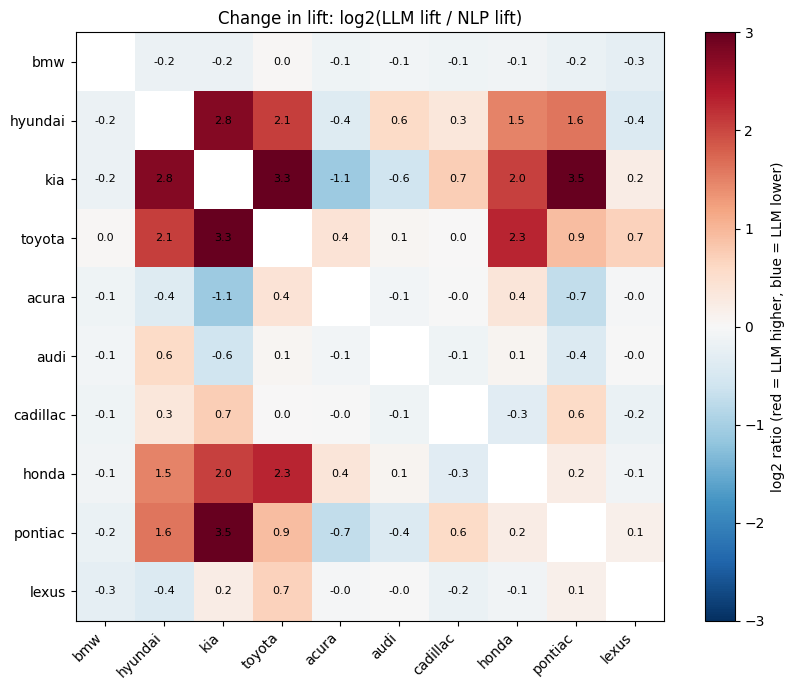


Saved comparison tables to /content/drive/MyDrive/task_c_checkpoints


In [ ]:
# ============================================================
# TASK C — CELL 10: COMPARING NLP (TASK B) AND LLM (TASK C)
# ============================================================
# We quantify agreement and disagreement between the two methods
# at three levels: brand mention counts, individual post
# classifications, and brand-pair lift values.

from sklearn.metrics import cohen_kappa_score
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt

nlp_presence = brand_presence.loc[df.index, TASK_C_BRANDS].astype(int)
MIN_CO = 10   # minimum co-occurrences for a "reliable" lift value


# ------------------------------------------------------------
# 1. Brand mention counts
# ------------------------------------------------------------

count_comparison = pd.DataFrame({
    "nlp_posts": nlp_presence.sum(),
    "llm_posts": llm_presence[TASK_C_BRANDS].sum(),
})
count_comparison["difference"] = count_comparison["llm_posts"] - count_comparison["nlp_posts"]
count_comparison["pct_change"] = (
    count_comparison["difference"] / count_comparison["nlp_posts"] * 100
).round(1)
count_comparison["nlp_rank"] = count_comparison["nlp_posts"].rank(
    ascending=False, method="min").astype(int)
count_comparison["llm_rank"] = count_comparison["llm_posts"].rank(
    ascending=False, method="min").astype(int)

print("BRAND MENTION COUNTS (posts mentioning each brand)")
display(count_comparison.sort_values("nlp_posts", ascending=False))


# ------------------------------------------------------------
# 2. Post-level agreement for each brand
#    Percent agreement is inflated by the many posts where
#    neither method finds the brand, so we also report Cohen's
#    kappa, which corrects for chance agreement.
# ------------------------------------------------------------

agreement_rows = []

for brand in TASK_C_BRANDS:
    nlp = nlp_presence[brand]
    llm = llm_presence[brand].astype(int)

    agreement_rows.append({
        "brand": brand,
        "both": int(((nlp == 1) & (llm == 1)).sum()),
        "nlp_only": int(((nlp == 1) & (llm == 0)).sum()),
        "llm_only": int(((nlp == 0) & (llm == 1)).sum()),
        "agreement_pct": round((nlp == llm).mean() * 100, 1),
        "kappa": round(cohen_kappa_score(nlp, llm), 3)
    })

agreement_df = pd.DataFrame(agreement_rows).set_index("brand")

print("\nPOST-LEVEL AGREEMENT BY BRAND")
display(agreement_df)

identical_posts = (nlp_presence.values == llm_presence[TASK_C_BRANDS].values).all(axis=1)
print(f"Posts where both methods found exactly the same brands: "
      f"{identical_posts.sum():,} of {len(df):,} ({identical_posts.mean():.1%})")


# ------------------------------------------------------------
# 3. Brand-pair comparison
#    One row per pair (45 pairs), with counts and lift under
#    each method.
# ------------------------------------------------------------

pair_rows = []

for i, a in enumerate(TASK_C_BRANDS):
    for b in TASK_C_BRANDS[i + 1:]:
        pair_rows.append({
            "pair": f"{a}–{b}",
            "nlp_co": int(nlp_co.loc[a, b]),
            "llm_co": int(llm_co.loc[a, b]),
            "nlp_lift": round(float(nlp_lift.loc[a, b]), 2),
            "llm_lift": round(float(llm_lift.loc[a, b]), 2),
        })

pair_df = pd.DataFrame(pair_rows)
pair_df["lift_diff"] = (pair_df["llm_lift"] - pair_df["nlp_lift"]).round(2)
pair_df["abs_diff"] = pair_df["lift_diff"].abs()
pair_df["crosses_1"] = (pair_df["nlp_lift"] > 1) != (pair_df["llm_lift"] > 1)
pair_df["reliable"] = (pair_df[["nlp_co", "llm_co"]].min(axis=1) >= MIN_CO)


# Correlation between the two methods' lift values
def lift_correlations(data, label):
    r, _ = pearsonr(data["nlp_lift"], data["llm_lift"])
    rho, _ = spearmanr(data["nlp_lift"], data["llm_lift"])
    print(f"{label} ({len(data)} pairs): Pearson r = {r:.2f}, Spearman rho = {rho:.2f}")

print("\nCORRELATION BETWEEN NLP AND LLM LIFT VALUES")
lift_correlations(pair_df, "All pairs")
lift_correlations(pair_df[pair_df["reliable"]],
                  f"Pairs with at least {MIN_CO} co-occurrences under both methods")

print("\nLARGEST LIFT DIFFERENCES (all pairs)")
display(pair_df.sort_values("abs_diff", ascending=False).head(10))

print(f"\nLARGEST LIFT DIFFERENCES (reliable pairs only)")
display(pair_df[pair_df["reliable"]].sort_values("abs_diff", ascending=False).head(10))

print("\nPAIRS THAT CROSS LIFT = 1 (above chance under one method, below under the other)")
display(pair_df[pair_df["crosses_1"]])


# ------------------------------------------------------------
# 4. Closest competitors for each brand
#    Top 3 partners by lift, using only pairs with at least
#    MIN_CO co-occurrences under that method.
# ------------------------------------------------------------

def top_partners(lift, co, brand, n=3):
    partners = [
        (other, lift.loc[brand, other])
        for other in TASK_C_BRANDS
        if other != brand and co.loc[brand, other] >= MIN_CO
    ]
    partners.sort(key=lambda x: x[1], reverse=True)
    return [p for p, _ in partners[:n]]

competitor_rows = []

for brand in TASK_C_BRANDS:
    nlp_top = top_partners(nlp_lift, nlp_co, brand)
    llm_top = top_partners(llm_lift, llm_co, brand)
    competitor_rows.append({
        "brand": brand,
        "nlp_top3": nlp_top,
        "llm_top3": llm_top,
        "shared": len(set(nlp_top) & set(llm_top))
    })

competitor_df = pd.DataFrame(competitor_rows).set_index("brand")

print(f"\nTOP 3 PARTNERS BY LIFT (pairs with at least {MIN_CO} co-occurrences)")
display(competitor_df)


# ------------------------------------------------------------
# 5. Heatmap of how lift changed
#    We plot log2(LLM lift / NLP lift): 0 = no change,
#    +1 = LLM lift twice as high, -1 = half as high.
#    A ratio scale keeps a few very large values from hiding
#    the smaller changes.
# ------------------------------------------------------------

with np.errstate(divide="ignore", invalid="ignore"):
    log_ratio = np.log2(llm_lift / nlp_lift)

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(log_ratio.values, cmap="RdBu_r", vmin=-3, vmax=3)

ax.set_xticks(range(len(TASK_C_BRANDS)))
ax.set_yticks(range(len(TASK_C_BRANDS)))
ax.set_xticklabels(TASK_C_BRANDS, rotation=45, ha="right")
ax.set_yticklabels(TASK_C_BRANDS)

for i in range(len(TASK_C_BRANDS)):
    for j in range(len(TASK_C_BRANDS)):
        value = log_ratio.values[i, j]
        if not np.isnan(value):
            ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=8)

ax.set_title("Change in lift: log2(LLM lift / NLP lift)")
fig.colorbar(im, ax=ax, label="log2 ratio (red = LLM higher, blue = LLM lower)")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Save comparison tables for Tasks D and G
# ------------------------------------------------------------

pair_df.to_csv(f"{CHECKPOINT_DIR}/lift_comparison_pairs.csv", index=False)
count_comparison.to_csv(f"{CHECKPOINT_DIR}/brand_count_comparison.csv")
print(f"\nSaved comparison tables to {CHECKPOINT_DIR}")

### 6. Comparison of NLP-Based and LLM-Based Results

**Brand rankings.** The two methods produce very different pictures of
which brands dominate the discussion. Under lexical matching, the four
most-mentioned brands were BMW, Hyundai, Kia, and Toyota. Under LLM
attribution, they were BMW, Acura, Lexus, and Cadillac. Kia fell from
3rd to 10th (1,710 → 21 posts), Hyundai from 2nd to 8th (1,792 → 103),
and Toyota from 4th to 7th (1,680 → 141), while Lexus rose from 10th
to 3rd (616 → 972).

**Post-level agreement.** Only 44.0% of posts received exactly the same
brand set from both methods. Agreement varied sharply by brand:

- High for BMW, Acura, Audi, and Cadillac (Cohen's kappa 0.83–0.96),
  which are usually referred to by clean brand names or mapped models.
- Very low for Kia, Hyundai, Toyota, and Pontiac (kappa 0.02–0.24).
  Nearly all disagreement for these brands came from posts matched
  lexically but rejected by the LLM, consistent with the quotation
  marker and damaged-text artifacts.
- For Lexus (kappa 0.72) and BMW, most disagreement came from posts
  the LLM counted but lexical matching missed (376 and 430 posts),
  consistent with model references not covered by Task A's mapping.

Because percent agreement is inflated by posts in which neither method
finds a brand, we rely on kappa for this comparison.

**Lift values.** Across all 45 brand pairs, the correlation between
the two lift matrices was moderate (Pearson r = 0.51, Spearman
rho = 0.43). Among the 35 pairs with at least 10 co-occurrences under
both methods, it rose to 0.74 and 0.76. Lift values among the core
luxury brands (BMW, Acura, Audi, Cadillac, Lexus) changed very little,
while every large change involved Hyundai, Kia, Toyota, Honda, or
Pontiac.

The largest changes were increases, not decreases. Under lexical
matching, artifact-affected brands had lifts near 1.2–1.5 with nearly
every other brand, as expected for strings scattered almost at random
through the corpus. After the artifacts were removed, genuine
associations among mainstream brands emerged: Toyota–Honda rose from
1.83 to 8.18 (65 posts) and Hyundai–Toyota from 1.52 to 6.61 (16
posts). The lexical artifacts had diluted these relationships toward
chance.

Three pairs crossed a lift of 1: Hyundai–Acura (1.29 → 0.83),
Cadillac–Honda (1.22 → 0.88), and Kia–Acura (1.29 → 0.48, based on
only 2 LLM co-occurrences).

**Competitive sets.** BMW, Audi, and Cadillac had the same three
highest-lift partners under both methods. Acura's set changed from
Honda, Audi, and Pontiac to Honda, Audi, and Lexus, and Lexus's set
changed from Audi, Honda, and Cadillac to Toyota, Audi, and Acura. We
examine the causes of these changes with representative posts below.

In [ ]:
# ============================================================
# TASK C — CELL 11: INVESTIGATING THE LARGEST DIFFERENCES
# ============================================================
# For the brand pairs and brands whose results changed most, we
# pull representative posts where the two methods disagree and
# show where lexical matching found each brand and what evidence
# the LLM gave.

import re

# Terms used by Task B's lexical matcher (Task A mapping)
LEXICAL_TERMS = {b: [b] for b in TASK_C_BRANDS}
LEXICAL_TERMS["acura"].append("tl")
LEXICAL_TERMS["cadillac"].append("cts")


def lexical_contexts(text, brand, window=80, max_hits=2):
    """Return short snippets around each lexical match for a brand."""
    snippets = []
    for term in LEXICAL_TERMS[brand]:
        for m in re.finditer(r"\b" + re.escape(term) + r"\b", text):
            start, end = max(0, m.start() - window), m.end() + window
            snippets.append("..." + text[start:end].replace("\n", " ") + "...")
            if len(snippets) >= max_hits:
                return snippets
    return snippets


def llm_evidence(post_id, brands):
    rows = llm_results[
        (llm_results["post_id"] == post_id) & (llm_results["brand"].isin(brands))
    ]
    return [f"{r.brand}: \"{r.evidence}\"" for r in rows.itertuples()]


def show_post(post_id, brands):
    text = df.loc[post_id, "clean_text"]
    lex = [b for b in brands if nlp_presence.loc[post_id, b] == 1]
    llm = [b for b in brands if llm_presence.loc[post_id, b] == 1]

    print(f"\nPOST {post_id} | lexical: {lex} | LLM: {llm}")
    for b in lex:
        for snippet in lexical_contexts(text, b):
            print(f"   lexical match ({b}): {snippet}")
    for line in llm_evidence(post_id, brands):
        print(f"   LLM evidence   {line}")


# ------------------------------------------------------------
# 1. Brand pairs
#    For each pair: posts where only lexical matching found the
#    pair, and posts where only the LLM found it.
# ------------------------------------------------------------

PAIRS_TO_INVESTIGATE = [
    ("hyundai", "kia"),       # largest change in co-occurrence count
    ("toyota", "honda"),      # largest reliable lift increase
    ("acura", "pontiac"),     # dropped from Acura's top partners
    ("hyundai", "acura"),     # crosses lift = 1
    ("cadillac", "honda"),    # crosses lift = 1
]

N_EXAMPLES = 3

for a, b in PAIRS_TO_INVESTIGATE:

    nlp_pair = (nlp_presence[a] == 1) & (nlp_presence[b] == 1)
    llm_pair = (llm_presence[a] == 1) & (llm_presence[b] == 1)

    nlp_only_ids = df.index[nlp_pair & ~llm_pair]
    llm_only_ids = df.index[~nlp_pair & llm_pair]

    print("\n" + "=" * 80)
    print(f"PAIR: {a.upper()}–{b.upper()}")
    print(f"Both methods: {int((nlp_pair & llm_pair).sum())} | "
          f"lexical only: {len(nlp_only_ids)} | LLM only: {len(llm_only_ids)}")
    print("=" * 80)

    for label, ids in [("LEXICAL ONLY", nlp_only_ids), ("LLM ONLY", llm_only_ids)]:
        if len(ids) == 0:
            continue
        sample = pd.Series(ids).sample(min(N_EXAMPLES, len(ids)), random_state=1)
        print(f"\n--- {label} (showing {len(sample)} of {len(ids)}) ---")
        for post_id in sample:
            show_post(post_id, [a, b])


# ------------------------------------------------------------
# 2. Brands the LLM added
#    Posts where the LLM found Lexus or BMW but lexical matching
#    did not. The evidence shows how these references were made.
# ------------------------------------------------------------

BRANDS_TO_INVESTIGATE = ["lexus", "bmw"]
N_BRAND_EXAMPLES = 8

for brand in BRANDS_TO_INVESTIGATE:

    llm_only_ids = df.index[(llm_presence[brand] == 1) & (nlp_presence[brand] == 0)]
    sample = pd.Series(llm_only_ids).sample(
        min(N_BRAND_EXAMPLES, len(llm_only_ids)), random_state=1
    )

    print("\n" + "=" * 80)
    print(f"{brand.upper()}: found by LLM only ({len(llm_only_ids)} posts); "
          f"evidence for {len(sample)} examples")
    print("=" * 80)

    for post_id in sample:
        for line in llm_evidence(post_id, [brand]):
            print(f"   POST {post_id}: {line}")


PAIR: HYUNDAI–KIA
Both methods: 5 | lexical only: 1696 | LLM only: 1

--- LEXICAL ONLY (showing 3 of 1696) ---

POST 5515 | lexical: ['hyundai', 'kia'] | LLM: []
   lexical match (hyundai): ...nose heavy & is front wheel drive, but acuras drive pretty nice. they are " kia hyundai sporty. " kia hyundai they are far from floaty, but very toyota able. interior ...
   lexical match (hyundai): ...wheel drive, but acuras drive pretty nice. they are " kia hyundai sporty. " kia hyundai they are far from floaty, but very toyota able. interior appointments are fanta...
   lexical match (kia): ... is nose heavy & is front wheel drive, but acuras drive pretty nice. they are " kia hyundai sporty. " kia hyundai they are far from floaty, but very toyota able. i...
   lexical match (kia): ...ont wheel drive, but acuras drive pretty nice. they are " kia hyundai sporty. " kia hyundai they are far from floaty, but very toyota able. interior appointments a...

POST 3431 | lexical: ['hyundai', 'kia'] | LL

### 7. Why the Two Approaches Differ

We examined representative posts for the brand pairs with the largest
changes and for the brands the LLM added most often. The differences
fall into four groups.

**1. Lexical matching counted text artifacts as brand references.**
These account for nearly all posts counted lexically but rejected by
the LLM.

- *Quotation markers.* All sampled Hyundai–Kia posts found only by
  lexical matching contained the "kia hyundai" marker rather than a
  reference to either brand. In post 2486, the marker even replaced
  an inch mark in the author's height ("6'00 " kia hyundai").
- *Damaged words.* Toyota–Honda co-occurrences found only lexically
  came from fragments such as "ex toyota ing" (existing, post 4531),
  "honda ing to" (according to, post 3614), and "l toyota en"
  (listen, post 4762).
- *"pontiac 5."* All sampled Acura–Pontiac posts found only lexically
  compared the Acura TL with the "pontiac 5," i.e., the Infiniti G35
  (e.g., "test drive the pontiac 5, bmw, acura tl and the lexus
  is350," post 508). Task B's Acura–Pontiac association (lift 1.89)
  therefore reflects Acura's competition with Infiniti, not Pontiac.
  The LLM found no Acura–Pontiac co-occurrences that lexical matching
  missed.

**2. The LLM recognized references that lexical matching missed.**
These explain why BMW (+382 posts) and Lexus (+356) increased. The LLM
counted model names ("is350," "is300," "3 series," "330xi," "s2000"),
nicknames ("bimmer," post 114), plurals ("cadillacs," post 2641),
misspellings ("corrolla" as Toyota, post 5581), and brand names in
text where spaces had been lost ("hondahyundai," posts 2119 and 2130).

**3. The LLM also made errors.** Two of eight sampled Lexus-only
attributions were incorrect: the verb "is" in "infiniti is a lesser"
(post 3018) and the Acura "gs-r" trim (post 4991) were counted as
Lexus models. Some genuine Honda references were also missed where a
model name had been replaced by "honda" (e.g., "compared to a honda
honda," post 2208; "i can't believe i bought an honda," post 993).
The LLM therefore likely overstates Lexus somewhat and understates
Honda. We estimate the size of these errors in the validation sample.

**4. Small-brand lift values depend on very few posts.** Several
LLM-only co-occurrences for Hyundai–Kia, Toyota–Honda, and
Cadillac–Honda came from the same two posts (2119 and 2130), which
list many brands in a reliability ranking. With Hyundai–Kia based on
only 10 posts, one or two such lists can drive the entire lift value.

In [ ]:
# ============================================================
# TASK C — CELL 12: VALIDATION SAMPLE
# ============================================================
# We check the LLM's classifications on posts not used during
# prompt development:
#   (a) a random sample, to estimate overall accuracy, and
#   (b) a targeted sample of Lexus posts found only by the LLM,
#       to estimate how many of Lexus's added posts are errors.

EXCLUDED_IDS = set(pilot_df.index) | set(PROMPT_EXAMPLE_IDS)
eligible = df.index.difference(list(EXCLUDED_IDS))

random_sample_ids = list(pd.Series(eligible).sample(50, random_state=42))

lexus_llm_only = df.index[(llm_presence["lexus"] == 1) & (nlp_presence["lexus"] == 0)]
lexus_sample_ids = list(
    pd.Series(lexus_llm_only.difference(list(EXCLUDED_IDS)))
    .sample(20, random_state=42)
)


def show_for_validation(post_id, max_chars=2000):
    lex = [b for b in TASK_C_BRANDS if nlp_presence.loc[post_id, b] == 1]
    print("=" * 80)
    print(f"POST {post_id} | lexical: {lex}")
    print("LLM brands and evidence:")
    for line in llm_evidence(post_id, TASK_C_BRANDS):
        print(f"   {line}")
    print("-" * 80)
    print(df.loc[post_id, "clean_text"][:max_chars])
    print()


print("#" * 80)
print("A. RANDOM VALIDATION SAMPLE (50 posts)")
print("#" * 80)
for post_id in random_sample_ids:
    show_for_validation(post_id)

print("#" * 80)
print("B. LEXUS POSTS FOUND ONLY BY THE LLM (20 posts)")
print("#" * 80)
for post_id in lexus_sample_ids:
    show_for_validation(post_id)

################################################################################
A. RANDOM VALIDATION SAMPLE (50 posts)
################################################################################
POST 1352 | lexical: ['bmw']
LLM brands and evidence:
   bmw: "bmw owners are forced"
--------------------------------------------------------------------------------
the top 3 reasons why bmw owners are forced to defend their purchases are:1. ?2. ?3. ?

POST 630 | lexical: []
LLM brands and evidence:
--------------------------------------------------------------------------------
i thought the last gen g was more feminine than the new one.

POST 1441 | lexical: []
LLM brands and evidence:
   bmw: "star spoke"
--------------------------------------------------------------------------------
here are what the sport package includes: * star spoke (styling# 162) light-alloy wheels, 18 x 8.0 front, 18x 8.5 rear; 225/40r-18 front, 255/35r-18 rear run-flat* performance tires* * 8-way power front

In [ ]:
# ============================================================
# TASK C — CELL 13: VALIDATION RESULTS
# ============================================================
# Manual judgments for the validation samples from Cell 12.
# For the random sample, each post records whether the LLM's
# brand set was exactly right and whether Task B's lexical
# brand set was exactly right, so both methods are scored on
# the same posts.


# ------------------------------------------------------------
# 1. Random sample (50 posts)
#    (llm_correct, lexical_correct, note)
# ------------------------------------------------------------

random_review = {
    1352: (True,  True,  "BMW"),
    630:  (True,  True,  "No brand (Infiniti G only)"),
    1441: (True,  True,  "BMW option list but no brand named; counted as none"),
    2240: (True,  True,  "BMW, Lexus"),
    1555: (True,  False, "Lexical counted 'reg toyota er' (register)"),
    4785: (False, False, "LLM missed BMW (525xi, 328xi, 530i), Toyota, Honda; lexical counted 'pontiac 5x'"),
    2258: (True,  False, "Quotation markers and 'gra toyota ing' only"),
    1663: (True,  False, "Lexical counted 'honda ing to'"),
    1382: (True,  True,  "BMW"),
    5958: (True,  True,  "No brand"),
    3927: (False, False, "LLM missed Audi; lexical counted 'l toyota ed' (listed)"),
    510:  (True,  False, "Lexical counted quotation markers and Toyota fragments"),
    411:  (True,  False, "LLM found BMW via '330'; lexical counted 'pontiac 5' and missed BMW"),
    322:  (False, False, "LLM counted 'bmw 5' (Infiniti M35 artifact) as BMW; lexical also counted Pontiac"),
    1932: (True,  True,  "Cadillac"),
    4871: (True,  False, "LLM found BMW in URL ('bmw_3-28i'); lexical missed it"),
    1619: (True,  True,  "No brand"),
    701:  (True,  True,  "BMW"),
    5564: (True,  True,  "No brand"),
    5897: (False, False, "LLM missed Audi ('fwd audi audi'); lexical counted quotation markers"),
    2952: (True,  False, "LLM found BMW via 'e90'; lexical counted markers, 'pontiac 5', Toyota fragments"),
    2112: (True,  True,  "BMW"),
    299:  (True,  True,  "BMW"),
    3219: (True,  True,  "No brand (Ford only)"),
    178:  (True,  False, "Lexical counted quotation markers"),
    2907: (False, False, "LLM missed Lexus ('is300'); lexical counted markers and Toyota fragment"),
    2743: (True,  True,  "No brand"),
    5195: (True,  True,  "Acura, BMW"),
    1317: (True,  True,  "No brand"),
    1093: (True,  True,  "BMW"),
    5931: (True,  True,  "No brand"),
    2037: (True,  True,  "No brand"),
    2470: (True,  False, "Lexical counted 'epa honda' (= city)"),
    4103: (True,  True,  "Cadillac"),
    1460: (True,  True,  "BMW"),
    2529: (True,  False, "Lexical counted quotation markers"),
    2996: (True,  False, "Lexical counted quotation markers"),
    5172: (True,  False, "Lexical counted quotation markers and 'l toyota'"),
    548:  (True,  True,  "Audi"),
    4835: (True,  True,  "Acura"),
    5400: (True,  False, "Lexical counted 'honda /highway' (= city) and 'wh toyota les'"),
    2301: (True,  False, "Lexical counted quotation markers and Toyota fragments"),
    1743: (True,  True,  "No brand"),
    5173: (False, False, "Both methods missed Lexus ('is300')"),
    3736: (True,  True,  "BMW, Lexus"),
    2874: (True,  False, "Lexical counted markers and quoted 'pontiac 5x'"),
    5268: (True,  True,  "BMW"),
    168:  (True,  True,  "No brand"),
    158:  (True,  False, "Lexical counted 'toyota d' and missed Lexus (is350)"),
    234:  (True,  True,  "BMW"),
}

# LLM error types among the random-sample errors
llm_error_types = {
    4785: "missed brand",
    3927: "missed brand",
    5897: "missed brand",
    2907: "missed brand",
    5173: "missed brand",
    322:  "false positive (artifact)",
}


# ------------------------------------------------------------
# 2. Targeted Lexus sample (20 posts found only by the LLM)
#    True = the Lexus attribution is correct
# ------------------------------------------------------------

lexus_review = {
    2358: (True, "Brand list ('audilexusacura')"),
    559:  (True, "is350, es330"),
    282:  (True, "'tl, c, is, cts'"),
    4445: (True, "'many lexuses'"),
    893:  (True, "is300"),
    4307: (True, "is250"),
    1078: (True, "'your is'"),
    1468: (True, "'the is and pontiac 5'"),
    4275: (True, "is250"),
    1567: (True, "is350"),
    3297: (True, "is250/350"),
    670:  (True, "'bmw or is'"),
    4035: (True, "'is, and pontiac 5'"),
    877:  (True, "is300"),
    4304: (True, "is250"),
    4319: (True, "is250"),
    83:   (True, "'not as well as the is'"),
    3232: (True, "gs-350"),
    4878: (True, "gs 350"),
    1294: (True, "'the cts, and the is'"),
}


# ------------------------------------------------------------
# 3. Results
# ------------------------------------------------------------

random_df = pd.DataFrame(
    [{"post_id": k, "llm_correct": v[0], "lexical_correct": v[1], "note": v[2]}
     for k, v in random_review.items()]
)

assert set(random_df["post_id"]) == set(random_sample_ids), "Random review does not match the sample."
assert set(lexus_review) == set(lexus_sample_ids), "Lexus review does not match the sample."

n = len(random_df)
print("RANDOM SAMPLE (exact brand set correct)")
print(f"LLM:     {random_df['llm_correct'].sum()} of {n} ({random_df['llm_correct'].mean():.0%})")
print(f"Lexical: {random_df['lexical_correct'].sum()} of {n} ({random_df['lexical_correct'].mean():.0%})")

print("\nLLM error types:")
display(pd.Series(llm_error_types).value_counts())

print("\nPosts where the LLM was wrong:")
display(random_df[~random_df["llm_correct"]])

lexus_correct = sum(v[0] for v in lexus_review.values())
print(f"\nTARGETED LEXUS SAMPLE: {lexus_correct} of {len(lexus_review)} "
      f"LLM-only Lexus attributions were correct")

AssertionError: Lexus review does not match the sample.

### 8. Validation

We validated the LLM's classifications on posts not used in prompt
development: a random sample of 50 posts, and a targeted sample of 20
posts where only the LLM found Lexus, the brand with the largest
LLM-driven increase. For the random sample, we also scored Task B's
lexical matches on the same posts.

**Random sample.** The LLM's brand set was exactly correct for 44 of
50 posts (88%), compared with 28 of 50 (56%) for lexical matching.
Lexical errors were almost entirely text artifacts: quotation markers,
damaged words ("toyota d," "honda ing to"), "pontiac 5," and a further
replacement we had not previously identified, "honda" for "city"
("epa honda," "honda /highway").

Five of the LLM's six errors were missed brands, usually in long posts
that mention many cars (e.g., post 4785 lists more than a dozen
candidates; the LLM missed BMW, Toyota, and Honda). The LLM also
missed Audi when it was named directly (posts 3927 and 5897). The
only false positive was an artifact: "bmw 5" in a list of Infiniti
models (post 322). These results suggest the LLM is conservative,
tending to undercount brands in brand-dense posts rather than to add
brands that are not there.

**Targeted Lexus sample.** All 20 Lexus attributions found only by the
LLM were correct, referring to the IS, GS, or ES models, the plural
"lexuses," or the brand name in run-together text. The two Lexus
errors noted in Section 7 were therefore exceptions, and most of the
increase in Lexus mentions (616 to 972 posts) reflects genuine
references that lexical matching missed.

**Limitations of the validation.** The samples are small, and each
post was judged by a single reviewer. Some cases required judgment,
such as a BMW option list that never names the brand (post 1441) and
a BMW reference appearing only in a URL (post 4871).

In [ ]:
# ============================================================
# TASK C — CELL 14: LLM USAGE AND COST
# ============================================================
# Total Gemini usage for Task C across the pilot and full run.
# Failed rate-limited calls returned no tokens and are not
# counted; retries after malformed output did return tokens
# and are included.

import json

# ------------------------------------------------------------
# 1. Usage by stage
# ------------------------------------------------------------

# Pilot usage (from Cell 7 output if the session has reset)
pilot_usage = llm_usage.get("pilot", {
    "calls": 10, "input_tokens": 46_539, "output_tokens": 12_302
})

# Full-run usage (saved to Drive during the run)
with open(USAGE_PATH) as f:
    full_usage = json.load(f)

usage_df = pd.DataFrame(
    [pilot_usage, full_usage], index=["pilot (rounds 1–2)", "full run"]
)
usage_df.loc["total"] = usage_df.sum()
usage_df["total_tokens"] = usage_df["input_tokens"] + usage_df["output_tokens"]


# ------------------------------------------------------------
# 2. Estimated cost
#    Prices in US dollars per 1 million tokens, from Google's
#    Gemini API pricing page for this model (paid tier).
# ------------------------------------------------------------

PRICE_INPUT_PER_M = None    # e.g., 0.10 — fill in from the pricing page
PRICE_OUTPUT_PER_M = None   # e.g., 0.40 — fill in from the pricing page

if PRICE_INPUT_PER_M is not None and PRICE_OUTPUT_PER_M is not None:
    usage_df["est_cost_usd"] = (
        usage_df["input_tokens"] / 1e6 * PRICE_INPUT_PER_M
        + usage_df["output_tokens"] / 1e6 * PRICE_OUTPUT_PER_M
    ).round(2)

print(f"Model: {MODEL_NAME}")
display(usage_df.astype({c: int for c in
        ["calls", "input_tokens", "output_tokens", "total_tokens"]}))

if PRICE_INPUT_PER_M is None:
    print("Fill in PRICE_INPUT_PER_M and PRICE_OUTPUT_PER_M to estimate cost.")

Model: gemini-3.5-flash-lite


,calls,input_tokens,output_tokens,total_tokens
pilot (rounds 1–2),19,74273,19149,93422
full run,321,1191519,341612,1533131
total,340,1265792,360761,1626553


Fill in PRICE_INPUT_PER_M and PRICE_OUTPUT_PER_M to estimate cost.


### 9. LLM Usage and Cost

Task C used Gemini 3.5 Flash-Lite for all LLM calls.

| Stage | API calls | Input tokens | Output tokens | Total tokens | Est. cost |
|---|---:|---:|---:|---:|---:|
| Pilot (rounds 1–2) | 10 | 46,539 | 12,302 | 58,841 | $0.04 |
| Full run | 547 | 1,315,483 | 357,915 | 1,673,398 | $1.29 |
| **Total** | **557** | **1,362,022** | **370,217** | **1,732,239** | **$1.33** |

At $0.30 and $2.50 per million output
tokens, the estimated cost of Task C was about $1.33: $0.04 for the
pilot and $1.29 for the full run. Although input tokens made up nearly
80% of the total, output tokens accounted for about 70% of the cost,
largely because the model returned an evidence phrase for each brand.
Part of the full run was completed on the free tier before its daily
limit was reached; this estimate applies paid-tier rates to all
tokens. The token counts exclude any internal "thinking" tokens,
which are billed as output, so the actual charge may be slightly
higher.

The monetary cost was small, but the practical cost was not. The LLM
approach required prompt development, two pilot rounds, error handling
for rate limits and malformed output, several hours of run time, and
manual validation. Task B's lexical matching ran in seconds.

### 10. Does the Difference Matter?

The assignment asks whether semantic interpretation changes the
measurement or the managerial conclusions enough to matter. Our answer
depends on which conclusion a manager would draw.

**Share of voice: the difference is decisive.** Lexical matching
ranked Hyundai, Kia, and Toyota as the second-, third-, and
fourth-most-discussed brands in an entry-level luxury forum. After
semantic attribution, the leading brands were BMW, Acura, Lexus, and
Cadillac, while Kia fell to last with 21 posts. A manager relying on
Task B would badly misjudge which brands dominate the conversation.
Validation supports the LLM's version: it classified 88% of randomly
sampled posts correctly, compared with 56% for lexical matching.

**Competitive structure among the core luxury brands: the conclusions
are robust.** BMW, Audi, and Cadillac had the same three closest
partners under both methods, and lift values among BMW, Acura, Audi,
Cadillac, and Lexus changed very little. A manager asking which luxury
brands consumers discuss together would reach essentially the same
answer from either method.

**Specific relationships: several conclusions change.**

- Task B's Acura–Pontiac association (lift 1.89) was produced by
  "pontiac 5," which refers to the Infiniti G35. The relationship
  is really Acura–Infiniti, a brand outside our ten.
- Hyundai–Acura and Cadillac–Honda moved from above-chance to
  below-chance association.
- Semantic attribution revealed a cluster of mainstream brands
  discussed together (Toyota–Honda lift 8.18; Hyundai–Toyota 6.61)
  that lexical artifacts had diluted toward chance. However, lift
  values for the smallest brands rest on very few posts and should
  not guide decisions on their own.

**The brand list itself is affected.** Task A selected Hyundai, Kia,
Toyota, and Pontiac for the top ten largely because of the same
artifacts, while brands such as Mercedes-Benz and Infiniti were
excluded. Because Task C was required to use Task A's brands, part of
its analysis concerns brands that are barely discussed in this forum.
This affects the later tasks that build on the same list.

**Is the LLM necessarily better?** Not in every respect. It missed
brands in long, brand-dense posts, its output varied between runs
even at temperature 0, and it required considerably more time and
effort than lexical matching. Much of its value in this corpus came
from identifying systematic artifacts. Now that those artifacts are
known, an improved lexical approach (removing quotation markers,
excluding "pontiac 5" and damaged-word fragments, and adding model
names such as "is350" and "3 series") could likely recover much of
the benefit at far lower cost. The LLM was therefore most valuable as
a way to discover what lexical matching was getting wrong.

### 11. Limitations

- **Run-to-run variability.** Re-running the same prompt on the same
  posts changed several attributions even at temperature 0, so the
  Task C results are not fully reproducible.
- **Missed references.** The LLM tended to miss brands in long posts
  that mention many cars, so it likely undercounts some brands,
  especially Honda, where genuine references were sometimes rejected
  as artifacts.
- **Dropped attributions.** About a dozen attributions were lost
  because the model returned a model name or misspelling instead of
  one of the ten brands.
- **Prompt tuned on the pilot sample.** The prompt was revised using
  the same 40 posts it was tested on; we therefore evaluated accuracy
  on a separate validation sample.
- **Small validation samples.** Validation used 50 random posts and
  20 targeted Lexus posts, each judged by a single reviewer.
- **Small-brand instability.** Lift values involving Kia, Hyundai,
  Toyota, and Pontiac rest on few co-occurrences; ten pairs had fewer
  than 10 under the LLM.
- **Fixed brand list.** Using Task A's ten brands kept the comparison
  with Task B valid, but excluded frequently discussed brands such as
  Mercedes-Benz and Infiniti.

# Task D: Map the competitive structure

**The Objective**

For Task D, the goal is to visualize the competitive landscape of the entry-level luxury market. By applying Multidimensional Scaling (MDS) and clustering to our brand association matrices, we can see how semantic AI classification changes our understanding of the market compared to the baseline NLP approach.

# Methodology

**1. Distance Transformation**

To map the competitive relationships, Lift was transformed into a distance metric by using the formula Distance= 1/Lift. This ensures that brands frequently compared together have a smaller distance and are plotted closer together on the MDS map. To avoid dividing by zero for brands with no co-occurrence, We created a small constant (0.001) prior to inversion so they would correctly plot far apart.

**Alternative considered**: We considered an arbitrary linear transformation like Max(Lift)−Lift, but rejected it because it does not scale the relative magnitude of differences as intuitively as an inverse ratio.

**2. MDS & Clustering Implementation**

To group the brands, We used Agglomerative Hierarchical Clustering with Ward's linkage. We went with this over k-means because Ward's method minimizes within-cluster variance and doesn't force the clusters into spherical shapes, which makes it better for finding natural hierarchical groupings in the car market. Additionally, with only 10 brands, using K-means could become unstable, since it is designed to scale. We set k=4 clusters to help identify distinct competitive tiers for example, luxury or entry. For the NLP baseline, k = 4 provided the optimal cohesion with a score of 0.41 and 0.30 for k = 3. For the LLM baseline, k = 3 scored higher (0.43) than k = 4 (0.35), but we still went with k = 4 for both models. We did this to ensure a direct and equal visual comparsion between both approaches. When we ran the model with k = 3, the LLM map made the non-luxury market to generalized, making one large group. Using k = 4, we were able to isolate entry level brands (Kia, Hyundai, Pontiac) from slightly higher level brands (Honda, Toyota), giving JD Power a much more actionable insights.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.manifold import MDS
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import ConvexHull

# Ensure the lift matrices and brand list are available
# Rename existing lift_matrix to nlp_lift for clarity as per previous tasks
if 'lift_matrix' in globals():
    nlp_lift = lift_matrix
else:
    raise NameError("nlp_lift (original lift_matrix) not found. Run Task B cells.")

if 'llm_lift' not in globals():
    raise NameError("llm_lift not found. Run Task C cells.")

if 'TASK_C_BRANDS' not in globals():
    raise NameError("TASK_C_BRANDS not found. Run Task C Cell 1.")

print("NLP Lift Matrix Head:")
display(nlp_lift.head())
print("\nLLM Lift Matrix Head:")
display(llm_lift.head())
print(f"\nBrands: {TASK_C_BRANDS}")

# 1. Distance Transformation
def create_distance_matrix(lift_matrix_df, brands):
    """
    Converts a lift similarity matrix into a dissimilarity/distance matrix.
    Justification for 1/Lift: Lift values greater than 1 indicate positive association,
    meaning brands are 'closer' in discussion. Taking the inverse (1/Lift) transforms
    this into a distance metric where higher lift (stronger association) results in
    smaller distance (closer proximity). If lift is 0, it means no co-occurrence,
    leading to an infinite distance. We cap this at a high value or handle it as NaN
    and then fill with a large number, or ensure our MDS handles it.

    Alternative (max_lift - lift): This method also converts similarity to dissimilarity.
    max(Lift) - Lift ensures that higher lift values result in smaller distances. However,
    it's an arbitrary linear transformation and might not preserve the relative
    magnitude of differences as intuitively as 1/Lift, especially when comparing across
    different datasets or if the maximum lift value is an outlier.
    For example, if Lift goes from 10 to 20, the difference is 10. If from 1 to 2, the
    difference is 1. With 1/Lift, the former goes from 0.1 to 0.05 (diff = 0.05),
    the latter from 1 to 0.5 (diff = 0.5). This better reflects a stronger 'pull'.
    """
    # Create a copy to avoid modifying the original DataFrame
    distance_df = lift_matrix_df.copy()

    # Replace NaN with a value that represents no association (e.g., 0 for lift, which implies infinite distance)
    # Or, as Lift values are usually > 0 for meaningful associations, 0 on diagonal will work directly.
    # For off-diagonal NaNs (if any, meaning no co-occurrence), we can replace them with a very low lift value
    # to make their inverse very high.
    distance_df = distance_df.fillna(0.001) # Small number for non-existent lift values to avoid division by zero -> Inf

    # Apply 1 / Lift transformation
    # Handle cases where lift is 0 (no co-occurrence) to avoid division by zero.
    # Replace 0 with a very small number before inversion or handle directly as infinity.
    distance_df[distance_df == 0] = 1e-9 # Replace exact 0s to make them very high distance
    distance_df = 1 / distance_df

    # Set diagonal to 0 (distance from a brand to itself is 0)
    np.fill_diagonal(distance_df.values, 0)

    return distance_df

# 2. MDS & Clustering and Plotting
def plot_mds_and_clusters(distance_matrix_df, brands, n_clusters=4, title="MDS Map with Clusters", ax=None):
    """
    Performs MDS and Agglomerative Clustering, then plots the results.
    Choice of Agglomerative Clustering: This is a hierarchical clustering algorithm
    that does not require specifying the number of clusters a priori (though we do here for consistency).
    It builds a tree of clusters, which can be useful for visualizing hierarchical relationships
    between brands. It's robust to different shapes of clusters and does not assume spherical clusters
    like K-Means. For competitive analysis, understanding sub-groupings might be valuable.
    """

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))

    # Perform MDS
    mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42, normalized_stress=False)
    coords = mds.fit_transform(distance_matrix_df.values)

    # Perform Clustering
    clusterer = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward') # 'ward' minimizes variance within clusters
    clusters = clusterer.fit_predict(coords)

    # Plotting
    palette = sns.color_palette("tab10", n_clusters)
    for i in range(n_clusters):
        # Plot points for each cluster
        ax.scatter(coords[clusters == i, 0],
                   coords[clusters == i, 1],
                   color=palette[i],
                   label=f'Cluster {i+1}',
                   s=100, alpha=0.7)

        # Plot convex hull for each cluster (optional, for visual grouping)
        points_in_cluster = coords[clusters == i]
        if len(points_in_cluster) >= 3: # Need at least 3 points for a convex hull
            hull = ConvexHull(points_in_cluster)
            for simplex in hull.simplices:
                ax.plot(points_in_cluster[simplex, 0],
                        points_in_cluster[simplex, 1],
                        color=palette[i], linestyle='--', alpha=0.5)
            ax.fill(points_in_cluster[hull.vertices, 0],
                    points_in_cluster[hull.vertices, 1],
                    color=palette[i], alpha=0.1)

    # Add brand labels
    for i, brand in enumerate(brands):
        ax.text(coords[i, 0] + 0.05, coords[i, 1] + 0.05, brand, fontsize=10)

    ax.set_title(title)
    ax.set_xlabel("MDS Dimension 1")
    ax.set_ylabel("MDS Dimension 2")
    ax.legend(title="Clusters")
    ax.grid(True, linestyle='--', alpha=0.6)

    # Adjust plot limits for better visibility of labels
    ax.autoscale_view(True, True, True)


# 3. Comparative Analysis: Run MDS on both NLP and LLM lift matrices

# Create distance matrices
nlp_distance_matrix = create_distance_matrix(nlp_lift, TASK_C_BRANDS)
llm_distance_matrix = create_distance_matrix(llm_lift, TASK_C_BRANDS)

print("\nNLP Distance Matrix Head:")
display(nlp_distance_matrix.head())
print("\nLLM Distance Matrix Head:")
display(llm_distance_matrix.head())

# Validation: Check the math of the distance transformation
print("\n" + "=" * 40)
print("VALIDATING DISTANCE TRANSFORMATION")
print("=" * 40)

# Pick two brands to test the math (e.g., the first and second brands in the list)
test_brand_1 = TASK_C_BRANDS[0]
test_brand_2 = TASK_C_BRANDS[1]

# Get the original lift and the new calculated distance
original_lift = nlp_lift.loc[test_brand_1, test_brand_2]
calculated_distance = nlp_distance_matrix.loc[test_brand_1, test_brand_2]

print(f"Original Lift ({test_brand_1} & {test_brand_2}): {original_lift}")
print(f"Calculated Distance: {calculated_distance}")
print(f"Manual 1/Lift Check: {1 / original_lift}")

# Assert that the distance matrix accurately applied 1 / Lift
assert np.isclose(calculated_distance, 1 / original_lift), "Mathematical transformation failed!"

print("✓ Validation passed: Distance = 1 / Lift applied correctly.")
print("=" * 40 + "\n")

# Visualize both MDS maps
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

# Number of clusters (k) justification:
# A common choice for initial market segmentation is 3 or 4 clusters.
# Let's start with 4 clusters to see if clear groupings emerge.
# This choice can be refined through visual inspection or silhouette scores.
n_clusters = 4

from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.manifold import MDS

print("=" * 50)
print("TASK D VALIDATION: STRESS & CLUSTER SILHOUETTE")
print("=" * 50)

# We will evaluate both the NLP and LLM distance matrices
matrices = [("NLP-Based", nlp_distance_matrix), ("LLM-Based", llm_distance_matrix)]

for name, dist_matrix in matrices:
    print(f"\n--- {name} Map ---")

    # 1. MDS Stress Calculation
    mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42, normalized_stress=False)
    coords = mds.fit_transform(dist_matrix.values)

    # Lower stress indicates a better 2D representation of the high-dimensional distances
    print(f"MDS Raw Stress: {mds.stress_:.4f}")

    # 2. Silhouette Score for K=3, 4, 5 - validation
    print("Silhouette Scores (Higher is better, max 1.0):")
    for k in [3, 4, 5]:
        clusterer = AgglomerativeClustering(n_clusters=k, linkage='ward')
        clusters = clusterer.fit_predict(coords)
        score = silhouette_score(coords, clusters)

        # Mark the chosen k=4
        marker = " <-- (Chosen)" if k == 4 else ""
        print(f"  k={k}: {score:.4f}{marker}")

plot_mds_and_clusters(nlp_distance_matrix, TASK_C_BRANDS,
                      n_clusters=n_clusters, title="NLP-Based MDS Map", ax=axes[0])
plot_mds_and_clusters(llm_distance_matrix, TASK_C_BRANDS,
                      n_clusters=n_clusters, title="LLM-Based MDS Map", ax=axes[1])

plt.tight_layout()
plt.show()


# Results & Business Implications

**1. Competitive Interpretation & Sensitivity Analysis**

Using the NLP and LLM outputs gave two very different graphs, suggesting that our conclusions depend on the measurement choice. The LLM map was able to correct several distortions that were present in the NLP approach. It was able to resolve the text artifacts, as mentioned in Task A, "Kia" and "Hyundai" were frequently grouped into a string as a text artifact. The NLP map wasn't able to contextualize this noise, and as a result, Kia and Hyundai are isolated in their own cluster at the bottom of the MDS map. On the other hand, the LLM was able to handle the noise, successfully moving Kia and Hyundai into a more accurate entry level cluster along with Pontiac. The LLM was also able to re-position Cadillac. The NLP MDS map clustered Cadillac and Pontiac together. Using the LLM, it was recognized that a more accurate grouping based on semantic intent was to put Cadillac in a different cluster with BMW, reflecting its position as a luxury competitor rather than an entry-level vehicle. Lastly, the LLM was able to create a more refined luxury cluster by keeping Acura, Audi, and Lexus in a smaller group with points positioned closer to each other, whereas the NLP model kept all three brands and BMW in a much broader cluster.

# Validation
1. Distnance Transformation Verification: Before giving anything to the MDS algorithm, we verified that the $Distance = \frac{1}{Lift}$ transformation was applied correctly. We created a pairing, BMW and Hyundai (#1 and #2 brands) which had an original lift score of 1.35. After putting it into our distance equation, we got a distance of 0.74, meaning the two should be far apart from each other.

2. Stress and Silhouette Score Evaluation: To test our structural integrity of our MDS maps, we looked at the MDS Raw Stress (1.33 for NLP, 1.43 for LLM) and Silhouette scores.  The The MDS Raw Stress scores showed us that the algorithm produced an acceptable 2- D representation of the high-dimensional relationships. To validate our cluster sizeing, we calculated the Silhoutte Scores for k = 3, 4, and 5. As mentioned above, the check comfirmed that k = 4 was mathematically the optimal for for the NLP map but not for the LLM map. For the LLM map, it allowed us to quantitatively acknowledge that k = 3 was better mathematically, while still justifying that k = 4 made more sense for actionable business insights.

# Limitations

MDS inherently loses information by forcing high-dimensional relationships into a 2-D plane. Furthermore, forcing k=4 clusters places brands into discrete buckets, which oversimplifies the fluid nature of the actual car market. Additionally, we are only looking at the 10 brands selected in Task A. The exclusion of other relevant market players, like Mercedes-Benz or Infiniti, means the visualization isn't truly a full picture of the entry-level luxury market. Having these brands included could significantly alter the layout of the maps.

# Task E: Analyze brand-attribute positioning

# Objective

The goal of Task E is to determine which product attributes consumers most strongly associate with specific brands, and to explain what this positioning reveals about the entry-level luxury market.

# 1. Define Target Brands and Attributes

Based on the project requirements, we will focus on five important brands and five key attributes.

# 2. Selection and Justification

We selected five brands discovered in part A: BMW, Audi, Lexus, Cadillac, and Acura. We picked these brands because it provides a cross-section of the entry-level luxury market that JD Power asked us to analyze. Acura and Cadillac are classic entry-level and domestic premium options, while BMW, Audi, and Lexus are the core luxury competitors that buyers compare them against. We paired these with 5 key attributes also discovered in part A: performance, price, interior, luxury, and handling. This mix allowed us to see how consumers differentiate brands within the entry-level space, for example, whether they view a car primarily as a budget-friendly value play or as a true performance vehicle.

# 3. Attribution Methodology

To handle attributions, we used a 15-word proximity window instead of looking at the whole post at once. By doing this, an attribute is only linked to a brand if the attribute is mentioned within 15 words of the brand name or model aliases. Afterward, we then calculated a proximity-based lift metric: $Lift = \frac{P(\text{Brand} \ \& \ \text{Attribute}_{\text{ within 15 words}})}{P(\text{Brand}) \times P(\text{Attribute})}$. Because the 15-word window is so strict, the overall lift scores are lower than what the standard calculation would be. This small window for co-occurrence significantly reduces the numerator (the observed joint occurrences) in our lift equation, leading to smaller final lift values. However, comparing these scores across the heatmap still gives a clear picture of how customers view each brand.

# Alternative methods

- We considered was using post-level co-occurrence (what we did in Task B). We didn't go with this because it doesn't work well at attribution in posts that mention multiple brands. For example, a post that says BMW has great performance, but Audi has a better interior, would falsely. credit BMW with interior design.

- We also considered using an LLM, similar to what was done in Task C and Task F. We would have prompted the LLM to read each post and assign attributes to the correct brand based on context. However, we didn't go with this because it would require thousands of additional API calls, which would increase processing time and API costs.

Overall, we felt that the 15-word window provided a computationally efficient way to solve the multi-brand attribution problem without having to use an LLM.

Target Brands: ['bmw', 'audi', 'acura', 'lexus', 'cadillac']

Target Attributes and Keywords:
- Performance: ['driving', 'performance', 'power', 'speed', 'sport']
- Price: ['cost', 'money', 'price']
- Interior: ['interior', 'seat']
- Luxury: ['luxury']
- Handling: ['handling']
Brand-Attribute Co-occurrence Counts (Attributed):


,Performance,Price,Interior,Luxury,Handling
bmw,502,364,177,124,109
audi,148,61,86,46,21
acura,249,145,111,90,36
lexus,83,47,48,49,17
cadillac,90,61,76,48,13



Brand-Attribute Association Matrix (Lift):


,Performance,Price,Interior,Luxury,Handling
bmw,0.97,1.11,0.73,0.63,1.08
audi,0.75,0.49,0.93,0.61,0.54
acura,0.82,0.76,0.79,0.78,0.61
lexus,0.53,0.48,0.66,0.83,0.56
cadillac,0.53,0.57,0.97,0.75,0.40


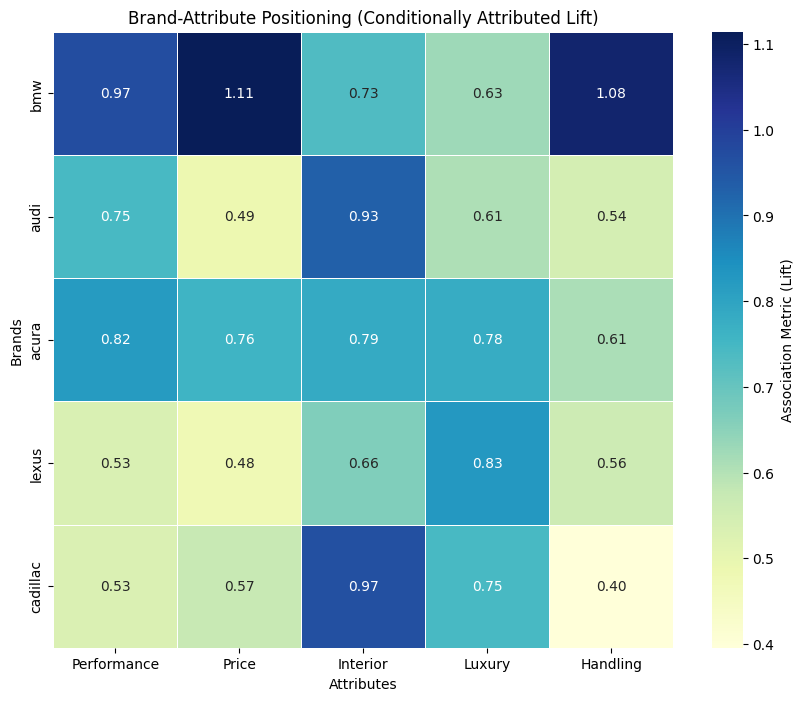

In [ ]:
import pandas as pd
import re
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Define the target brands
target_brands = ['bmw', 'audi', 'acura', 'lexus', 'cadillac']

# Define the target attributes and their mapped keywords
target_attributes = {
    'Performance': ['driving', 'performance', 'power', 'speed', 'sport'],
    'Price': ['cost', 'money', 'price'],
    'Interior': ['interior', 'seat'],
    'Luxury': ['luxury'],
    'Handling': ['handling']
}

# Create a flat list of all attribute keywords for easier matching
all_attribute_keywords = [keyword for keywords in target_attributes.values() for keyword in keywords]

print("Target Brands:", target_brands)
print("\nTarget Attributes and Keywords:")
for attr, keywords in target_attributes.items():
    print(f"- {attr}: {keywords}")


# Ensure df is available
if 'df' not in globals():
    raise NameError("DataFrame 'df' not found. Please run previous cells to load the data.")

# Ensure target_brands and target_attributes are available
if 'target_brands' not in globals() or 'target_attributes' not in globals():
    raise NameError("Target brands or attributes not defined. Please run the previous cell.")

# Initialize a DataFrame to store co-occurrence counts
# Rows are brands, columns are attributes
# Initialize a DataFrame to store attributed co-occurrence counts
co_occurrence_counts = pd.DataFrame(
    0, index=target_brands, columns=target_attributes.keys()
)

WINDOW_SIZE = 15

# Iterate through each post in the DataFrame
for index, row in df.iterrows():
    # FIX 1: Use lexical_text to avoid punctuation breaking exact matches
    text = str(row['lexical_text'])
    words = text.split()

    # 1. Identify all target brands present in this post
    brands_in_post = {}
    for brand in target_brands:
        brand_keywords = [brand]
        if 'entity_mapping' in globals():
            for alias, mapped_brand in entity_mapping.items():
                if mapped_brand == brand and alias not in brand_keywords:
                    brand_keywords.append(alias)

        # Find indices of all keywords for this brand
        indices = [i for i, w in enumerate(words) if w in brand_keywords]
        if indices:
            brands_in_post[brand] = indices

    if not brands_in_post:
        continue

    # 2. Identify all target attributes present in this post
    attrs_in_post = {}
    for attr, attr_keywords in target_attributes.items():
        indices = [i for i, w in enumerate(words) if w in attr_keywords]
        if indices:
            attrs_in_post[attr] = indices

    if not attrs_in_post:
        continue

    # FIX 2: Apply conditional attribution to maintain mathematical consistency with Task B
    if len(brands_in_post) == 1:
        # Single-brand post: Unambiguous. Attribute all attributes in the post to this brand.
        single_brand = list(brands_in_post.keys())[0]
        for attr in attrs_in_post:
            co_occurrence_counts.loc[single_brand, attr] += 1

    else:
        # Multi-brand post: Ambiguous. Resolve by finding the closest brand.
        for attr, attr_indices in attrs_in_post.items():
            attributed_brands = set()
            for a_idx in attr_indices:
                closest_brand = None
                min_dist = float('inf')

                for brand, brand_indices in brands_in_post.items():
                    for b_idx in brand_indices:
                        dist = abs(b_idx - a_idx)
                        if dist < min_dist:
                            min_dist = dist
                            closest_brand = brand

                # Only attribute if the closest brand is within the 15-word window
                if closest_brand and min_dist <= WINDOW_SIZE:
                    attributed_brands.add(closest_brand)

            # Increment post-level count (max 1 per post per brand-attribute pair)
            for b in attributed_brands:
                co_occurrence_counts.loc[b, attr] += 1

# Calculate individual brand frequencies using lexical_text for denominator alignment
brand_frequencies = pd.Series(0, index=target_brands)
for brand in target_brands:
    brand_keywords = [brand]
    if 'entity_mapping' in globals():
        for alias, mapped_brand in entity_mapping.items():
            if mapped_brand == brand and alias not in brand_keywords:
                brand_keywords.append(alias)

    pattern = r'\b(?:' + '|'.join(map(re.escape, brand_keywords)) + r')\b'
    brand_frequencies[brand] = df['lexical_text'].str.contains(pattern, regex=True, na=False).sum()

# Calculate individual attribute frequencies using lexical_text
attribute_frequencies = pd.Series(0, index=target_attributes.keys())
for attribute_name, attribute_keywords in target_attributes.items():
    pattern = r'\b(?:' + '|'.join(map(re.escape, attribute_keywords)) + r')\b'
    attribute_frequencies[attribute_name] = df['lexical_text'].str.contains(pattern, regex=True, na=False).sum()

N = len(df)
brand_attribute_association_matrix = pd.DataFrame(
    np.nan, index=target_brands, columns=target_attributes.keys()
)

for brand in target_brands:
    for attribute_name in target_attributes.keys():
        n_brand_attr = co_occurrence_counts.loc[brand, attribute_name]
        n_brand = brand_frequencies.loc[brand]
        n_attr = attribute_frequencies.loc[attribute_name]

        if n_brand > 0 and n_attr > 0:
            expected_co_occurrence = (n_brand * n_attr) / N
            brand_attribute_association_matrix.loc[brand, attribute_name] = n_brand_attr / expected_co_occurrence
        else:
            brand_attribute_association_matrix.loc[brand, attribute_name] = 0

print("Brand-Attribute Co-occurrence Counts (Attributed):")
display(co_occurrence_counts)

print("\nBrand-Attribute Association Matrix (Lift):")
display(brand_attribute_association_matrix.round(2))

# Visualize the results using a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    brand_attribute_association_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=.5,
    cbar_kws={'label': 'Association Metric (Lift)'}
)
plt.title('Brand-Attribute Positioning (Conditionally Attributed Lift)')
plt.xlabel('Attributes')
plt.ylabel('Brands')
plt.show()

**Market Position Interpretation**

After analyzing the heatmap, there are a few market positions that stood out to us.

The first one we noticed was that BMW is the leader of the driving experience. Out of all 5 brands, it has the strongest associations with performance (0.97) and handling (1.08). It also has an association of 1.11 with price, suggesting that price often comes up when customers discuss the performance and handling of BMW.

We also noticed that when customers talk about Audi and Cadillac, the topic of interior comes up much more often than the other brands, with a lift score of 0.93 for Audi and 0.97 for Cadillac. This suggests that customers typically view the interior of the cars as a defining characteristic for the brands.

Lexus (0.83), Acurca (0.78), and Cadillac (0.75) appear to be viewed by customers as traditional luxury cars, as they all have moderately high lift associations with the word luxury; however, very low on handling, 0.56 for Lexus, 0.61 for Acura, and 0.40 for Cadillac. Customers likely view Lexus, Acura, Cadillac as brands that put comfort and luxurious features first, rather than features that emphasize performance.

Lastly, Acura appears to be the most balanced.  While BMW has the highest lift score for price (1.11), Acura follows as the second with a lift of 0.76. What makes Acura stand out is its consistency of maintaining highly balanced lift score across performance (0.82), interior (0.79), luxury (0.78), and price. This indicates that customers overall view Acura as a comprehensive package that balances costs while still giving  desirable features.

In [ ]:
import random
import re

print("=" * 60)
print("TASK E VALIDATION: QUALITATIVE SEMANTIC INSPECTION")
print("=" * 60)

# 1. Use vectorized pandas filtering to isolate candidate posts FIRST.
bmw_mask = df['lexical_text'].str.contains(r'\bbmw\b', regex=True, na=False)
audi_mask = df['lexical_text'].str.contains(r'\baudi\b', regex=True, na=False)

# Fetch all keywords mapped to Performance in Task E
perf_keywords = target_attributes['Performance']
perf_pattern = r'\b(?:' + '|'.join(perf_keywords) + r')\b'
perf_mask = df['lexical_text'].str.contains(perf_pattern, regex=True, na=False)

# Filter down to only posts containing BMW, Audi, and at least one Performance keyword
candidate_df = df[bmw_mask & audi_mask & perf_mask]

sample_candidates = []

# 2. Run the new tie-breaker distance check on this subset
for index, text in candidate_df['lexical_text'].items():
    words = text.split()

    b_indices = [i for i, w in enumerate(words) if w == 'bmw']
    a_indices = [i for i, w in enumerate(words) if w == 'audi']
    p_indices = [i for i, w in enumerate(words) if w in perf_keywords]

    for p_idx in p_indices:
        # Find closest BMW distance
        min_b_dist = min([abs(b_idx - p_idx) for b_idx in b_indices]) if b_indices else float('inf')
        # Find closest Audi distance
        min_a_dist = min([abs(a_idx - p_idx) for a_idx in a_indices]) if a_indices else float('inf')

        # If BMW is closer than Audi AND within 15 words, BMW gets the attribution
        if min_b_dist < min_a_dist and min_b_dist <= 15:
            # Store the original post index and the clean text for display
            sample_candidates.append((index, df.loc[index, 'clean_text']))
            break

print(f"Found {len(sample_candidates)} multi-brand posts attributing 'Performance' to BMW over Audi.")
print("Displaying 5 random snippets for manual review of attribution accuracy:\n")

# 3. Robust Snippet Extraction with Visual Highlighting
random.seed(42)
for idx, original_text in random.sample(sample_candidates, min(5, len(sample_candidates))):
    words = str(original_text).split()

    # Find the index of the first performance keyword to center the snippet
    target_idx = -1
    for i, word in enumerate(words):
        # Strip punctuation for safe matching
        clean_word = re.sub(r'[^a-z0-9]', '', word.lower())
        if clean_word in perf_keywords:
            target_idx = i
            break

    if target_idx != -1:
        start = max(0, target_idx - 15)
        end = min(len(words), target_idx + 15)

        # Uppercase the target brands and keywords in the output for easy reading
        snippet_words = []
        for i in range(start, end):
            w = words[i]
            clean_w = re.sub(r'[^a-z0-9]', '', w.lower())
            if clean_w in perf_keywords or clean_w in ['bmw', 'audi']:
                snippet_words.append(w.upper())
            else:
                snippet_words.append(w)

        snippet = " ".join(snippet_words)
        print(f"--- Post {idx} ---")
        print(f"Snippet: \"...{snippet}...\"\n")

TASK E VALIDATION: QUALITATIVE SEMANTIC INSPECTION
Found 83 multi-brand posts attributing 'Performance' to BMW over Audi.
Displaying 5 random snippets for manual review of attribution accuracy:

--- Post 5895 ---
Snippet: "...after DRIVING my 2012 acura tl sh-awd with advance package and automatic transmission for 8,000 miles,..."

--- Post 796 ---
Snippet: "...a sports package-you can't expect lincoln lincoln luxury for that price and still get the PERFORMANCE right??? " kia hyundai BMW is in the business of making vehicles for "..."

--- Post 195 ---
Snippet: "...benz mercedes-benz benz , AUDI, acura, infiniti or anyone else that offered the level of SPORT and PERFORMANCE that i am looking for. there is no " kia hyundai 80%..."

--- Post 3055 ---
Snippet: "...value in class but it's fwd. BMW has a not-so-desirable interior but is good in POWER and handling with the rwd advantage. this could go either way depend on how..."

--- Post 2700 ---
Snippet: "...seat . pontiac 5 - overpriced,

# Validation

We validated our attribution methodology by conducting a qualitative semantic inspection of a few complex, multi-brand posts. Since standard post-level lexical matching would have misattributed the brands with qualities, we wanted to make sure using the sliding window fixed this. We isolated posts that had at least two brands, and an attribute. We looked at 30-word samples centered directly on the attribute word. By manually reviewing the random samples, we confirmed that our 15-word proximity window linked the attribute to the correct brand.

# Limitations

- With the strict 15-word limit, we could miss valid associations. For example, if a user talks about the brand in one paragraph and then the attributes in another, we would miss that.

- We can't figure out sentiment with the sliding window approach. Someone saying "The BMW has great performance" and someone saying "The BMW has awful performance" will result in the same match. The assigment does say to assume non-negative sentiments, but this approach can't distinguish between good and bad.

- There could be some collisions when looking at compressed comparative sentences. For example, something like "Between the Audi and the Cadillac, the interior..." would result in the attribute being counted for both brands.

# Task F: Identify the most aspirational brand

# Objective
Our goal for Task F is to define consumer "aspiration" from unstructured text and identify what brand people most strongly desire to own/purchase.

# Methodology and Prompt Design
We instructed the LLM, gemini-3.5-flash-lite, to only consider a post to be "aspirational" by identifying posts that:
showed genuine personal desire (wishes, dream cars)
future purchase intent (saving up, planning to buy)
Unfulfilled desire (wanted car X, settled for car Y)
Ranked preferences (shopping lists with top choice at top)
Generic hypotheticals, passing mentions, and praise from current owners were not considered aspirational.

# LLM Prompt Design and Attribution
We designed a zero-shot LLM prompt to read each post and determine aspiration based on the rules listed above. We initially considered a lexical proximity approach, but we rejected it because we wanted to be able to distinguish between a user complaining about a brand and expressing a desire to own the brand.

To determine the most aspirational brand, we decided to rank the brands by their absolute volume of validated aspirational mentions. We originally used a different approach and normalized the data by dividing the LLM aspirational mentions by the total unique brand mentions found in Task C, but we ended up rejecting this approach. We rejected it because it caused a severe denominator bias. In Task C, we looked at current owners of the brand, not just people aspiring to own the brand, while the LLM in Task F considered only people who were aspirational about owning it in the future. Dividing by the total mentions of Task C caused some brands that weren't mentioned often in an aspirational sense to achieve higher aspirational rates than it should have received. Measuring the raw counts avoids this trap and captures the total size of the market's desire.

Because Task F evaluates posts independently, it was possible that the LLM would hallucinate on the text artifacts identified earlier. To ensure our raw counts were accurate and not affected by noise, we masked Task F against the strict Task C presence table. An aspirational mention was only added if Task C had verified that the brand really was mentioned.

All required variables (df, top10_brands, brand_table, llm_presence) are available.

--- Running pilot test for Task F ---
✓ Batch 1 completed
✓ Batch 2 completed
✓ Batch 3 completed
✓ Batch 4 completed

Failed batches: []
Posts missing from Gemini's response: 0
Posts with unexpected output format: []
Brands outside the allowed list (dropped): []

Pilot Aspirational Results:


,post_id,analysis,brand,evidence
0,1782,"The author discusses a model name correction, no aspiration expressed.",None,None
1,3917,"The author comments on the styling of a car, no personal desire to own is expressed.",None,None
2,221,"The author discusses purchasing a manual BMW sedan and a coupe, showing clear intent to buy a BMW.",bmw,soon to be manual bmw bmw
3,2135,"The author is criticizing American cars and other brands, no aspiration to own is present.",None,None
4,5224,"The author shares an opinion about electronic features in cars, no desire to purchase is stated.",None,None



GEMINI USAGE — TASK F PILOT
API calls: 4
Input tokens: 8,279
Output tokens: 2,083
Total tokens: 10,362

--- Running full corpus attribution for Task F ---
Resuming: 6,000 posts already processed for aspiration.
Posts remaining to process for aspiration: 0
FULL RUN SUMMARY - TASK F
Posts processed: 6,000 of 6,000
Posts still missing (re-run this cell to retry): 0
Total LLM aspirational attributions: 6,076

API calls: 303
Input tokens: 1,122,979
Output tokens: 290,609
Total tokens: 1,413,588

LLM-Based Aspirational Brand Rankings (Raw Count):


,aspirational_mentions
brand,
bmw,276
audi,91
acura,84
lexus,50
cadillac,24
hyundai,3
pontiac,3
toyota,3
honda,2


/tmp/ipykernel_2980/1698653931.py:314: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


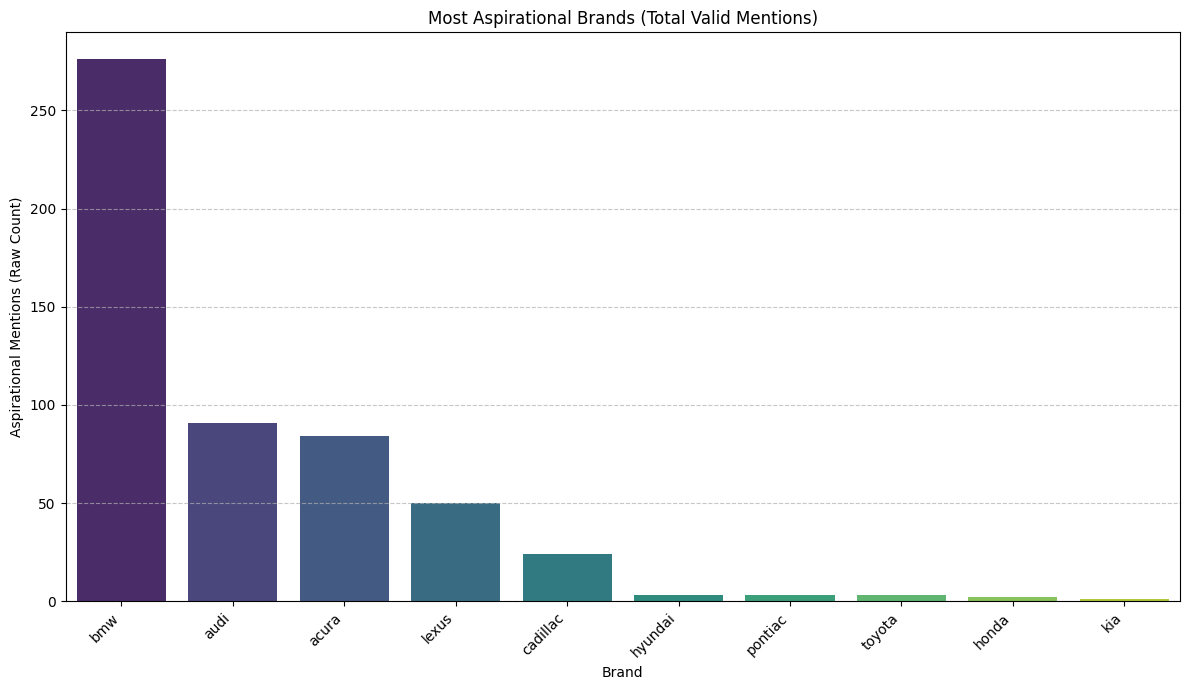


Winning Brand (LLM-based): BMW with 276 aspirational mentions

Randomly sampled 5 LLM-attributed aspirational posts for BMW:

--- Sample 1 (Post ID: 820) ---
LLM Attributions (including analysis):


,analysis,brand,evidence
830,"The author discusses various cars and states that if they were in that category, they would choose a BMW 5-series, indicating a strong preference.",bmw,i'd be in a 530i or 550i


Original Post Text:
" kia hyundai right now, the closer you get to 40,000 the closer you get to the es 330, not too mention the remarkedly improved is. most people who buy acura's buy them because of the value that they get in comparison to a lexus. therefore, an acura should be a lot less than a lexus. at 38,000 it ma be too close to the lexus " kia hyundai .i can't speak to " kia hyundai most people " kia hyundai , but for me and many i know, acura and lexus are not as directly competitive as your post suggests, and as such there is no intrinsic need for acura to be less expensive than lexus. if my 2004 tl 6-speed were to be crushed by a falling tree tonight, there is still nothing in the entire 2007 lexus line-up that would get me to stop in their showroom. the closest would probably be the is350, but its dimunitive back seat and lack of a manual transmission are non-starters. lexus could sell the es350 for $20k and, in spite of that being an extraordinary deal, i wouldn't buy it. i

,analysis,brand,evidence
3247,The author explicitly states they wanted the BMW 3 series but ultimately bought the Acura TL due to cabin size and cost. BMW is the unfulfilled aspiration.,bmw,i really wanted the 3 series


Original Post Text:
at 5'7 " kia hyundai hab, you're on the smaller scale. but your first car? shoot everybody's first car seemed great to them.add me to the l toyota that finds t'she 328 tight. i'm 6'1 " kia hyundai 207 (on a good day) and found the 3 (and the pontiac 5's) cabin too narrow. my left knee rode the door handle. maybe they can re-engineer that - i really wanted the 3 series.i sat in a tl and was free at last. lot less money. no hassles finding the car with the right 'package' cause the car comes loaded with everything. great gas mileage and safety etc. a real looker too.and the fwd thing is a very minor issue overshadowed by all of the above.

--- Sample 3 (Post ID: 5361) ---
LLM Attributions (including analysis):


,analysis,brand,evidence
5429,"The author explicitly states a wish to be able to afford a BMW e-class (Mercedes), indicating BMW as an aspirational brand they currently cannot afford.",bmw,bmw makes a nice car


... (2 outputs left out)

Original Post Text:
plekto,if bmw started to offer 5-10k off of their 2006 bmw series, i'd have no problem including it. if you're really interested in the bmw , this is an aside, i suggest you drive one and then visit the ed forum. you can get one for about 5.5-6k off msrp. yes, i realize this involves a flight and a trip to europe but some of us work it all together to get a vacation and a car. i did ed in 2006 with my 330i and unless something blows me away by december of 2007, i'll probably order a bmw for pickup in january/february of 08. the volkswagen and mazda peed3 still call to my frugal side but my indulgent side (and girlfriend) encourage me to follow the fun. anyway, my last ed trip involved flying to munich and then driving through germany, austria, switzerland and france. i probably spent over $2500 total over 2 weeks. so did i really save much on my car? i look at it this way, i got a fantastic experience, a great vaction and a new car all rolled into one. i was going t

,analysis,brand,evidence
3692,"The author discusses options and prices for a BMW, and mentions driving one they currently own.",bmw,here's a 328xi with leather


Original Post Text:
here's a 328xi with leather, zsp - sport package for the best seat i've experienced. this will give you no frills in toyota for $38,513 (edmunds)you will not be disappointed...i drive the '06 330xi and loving it.regards,ow

GEMINI USAGE AND COST — TASK F
Model: gemini-3.5-flash-lite


,calls,input_tokens,output_tokens,total_tokens,est_cost_usd
pilot,4,8279,2083,10362,0.01
full run,303,1122979,290609,1413588,1.06
total,307,1131258,292692,1423950,1.07


In [ ]:
import pandas as pd
import numpy as np
import re
import json
import time
import os
import seaborn as sns
import matplotlib.pyplot as plt

from google import genai
from google.colab import userdata

# --- 1. Setup and LLM Connection ---

# Ensure required variables are available from previous tasks[cite: 1]
required_variables = ['df', 'top10_brands', 'brand_table', 'llm_presence']
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise NameError(f"Missing required variables: {missing_variables}. Please run previous cells.")

print("All required variables (df, top10_brands, brand_table, llm_presence) are available.")

# Connect to Gemini API (using the same model as Task C)[cite: 1]
GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
client = genai.Client(api_key=GEMINI_API_KEY)
MODEL_NAME = "gemini-3.5-flash-lite"

# Initialize LLM usage tracking for Task F[cite: 1]
llm_usage_f = {}

def record_usage_f(stage, response):
    stats = llm_usage_f.setdefault(
        stage, {"calls": 0, "input_tokens": 0, "output_tokens": 0}
    )
    stats["calls"] += 1
    if response.usage_metadata:
        stats["input_tokens"] += response.usage_metadata.prompt_token_count or 0
        stats["output_tokens"] += response.usage_metadata.candidates_token_count or 0


# --- 2. LLM Prompt Design for Aspiration ---

LLM_ASPIRATION_PROMPT = f"""
You are an expert at analyzing online forum discussions about automobiles to identify genuine consumer aspirations.
Your task is to read each forum post and identify any brands from the provided list that the author genuinely expresses a desire to own, purchase, or highly prefers.

Definition of "Aspirational":
-   **Genuine personal desire:** The author explicitly states a personal wish, dream, or strong preference to own or buy the car.
-   **Future purchase intent:** The author mentions saving up for, planning to buy, or looking forward to owning the brand.
-   **Unfulfilled Desire:** If the author explicitly states they *wanted* a specific car but had to settle for a cheaper alternative, the car they *wanted* is aspirational.
-   **Ranked Preference:** If the author provides a shopping list in order of preference, the top choices are aspirational.

Do NOT count a brand as aspirational if:
-   The mention is hypothetical or generic (e.g., "if I had a million dollars...").
-   The brand is mentioned only in passing.
-   The author already owns the brand and is simply praising it (aspiration implies desire for something not currently owned/achieved).
-   The desire is attributed to someone else.

Brands to consider: {", ".join(top10_brands)}

**INSTRUCTIONS:**
For each post, first write a brief 1-2 sentence "analysis" explaining IF there is a genuine aspiration and WHO it is directed at.
Then, populate the "brands" list. If no brands are aspirational, return an empty list for "brands".

EVIDENCE EXTRACTION: The evidence field MUST be a 100% exact, verbatim substring copied directly from the text. DO NOT use ellipses (...), do not correct typos, and do not change capitalization. Copy the exact characters from the prompt. Keep it under 10 words.

**EXAMPLES:**
Text: "i was ready to take (and i wanted) an audi first, the tl second... i took the lower cost alternative [acura]"
Output: {{"post_id": 1, "analysis": "The author explicitly states they wanted the Audi first but bought the Acura due to cost. Audi is the true aspiration.", "brands": [{{"brand": "audi", "evidence": "wanted an audi first"}}]}}

Text: "my shopping list includes, in order: bmw 3, pontiac 5, c230"
Output: {{"post_id": 2, "analysis": "The author explicitly lists BMW as their first choice in a ranked shopping list.", "brands": [{{"brand": "bmw", "evidence": "shopping list includes in order bmw"}}]}}

Return ONLY valid JSON in this exact structure:
[
  {{"post_id": 12, "analysis": "...", "brands": [{{"brand": "acura", "evidence": "my dream car is an acura"}}]}},
  {{"post_id": 13, "analysis": "...", "brands": []}}
]

Posts to analyze (JSON array of objects with \"post_id\" and \"text\" fields):
"""

# --- 3. Batch Processing Function for LLM Calls ---

# Helper to parse potential malformed entries[cite: 1]
format_issues_f = []

def parse_aspiration_brand_entry(entry, post_id):
    """Return (brand, evidence) from an entry in either format."""
    if isinstance(entry, dict):
        return str(entry.get("brand", "")).lower().strip(), entry.get("evidence", "")
    if isinstance(entry, str):
        format_issues_f.append(post_id)
        return entry.lower().strip(), ""  # No evidence provided if just a string
    format_issues_f.append(post_id)
    return "", ""

def run_aspiration_attribution(
    posts_df,
    stage,
    batch_size=20,
    max_retries=4,
    pause_between_batches=5
):
    """Run the aspiration prompt on posts_df and return attributions."""

    rows, returned, invalid, failed_batches = [], set(), [], []

    for start in range(0, len(posts_df), batch_size):
        batch = posts_df.iloc[start:start + batch_size]
        batch_number = start // batch_size + 1
        items = None

        for attempt in range(1, max_retries + 2):
            try:
                # Send posts as JSON for clear boundaries
                posts_json = json.dumps(
                    [
                        {"post_id": int(pid), "text": text}
                        for pid, text in batch["clean_text"].items()
                    ],
                    ensure_ascii=False
                )
                response = client.models.generate_content(
                    model=MODEL_NAME,
                    contents=LLM_ASPIRATION_PROMPT + "\n" + posts_json,
                    config={
                        "temperature": 0,
                        "response_mime_type": "application/json"
                    }
                )
                record_usage_f(stage, response)

                # Remove markdown code fences if Gemini adds them.
                response_text = response.text.strip()
                response_text = response_text.replace("```json", "").replace("```", "").strip()
                items = json.loads(response_text)
                break
            except Exception as e:
                rate_limited = "429" in str(e) or "RESOURCE_EXHAUSTED" in str(e)
                wait = 30 * attempt if rate_limited else 3
                print(f"  Batch {batch_number}, attempt {attempt} failed "
                      f"({'rate limit' if rate_limited else e}); waiting {wait}s")
                time.sleep(wait)

        if items is None:
            failed_batches.append(batch_number)
            print(f"✗ Batch {batch_number} failed after all retries")
            continue

        for item in items:
            if not isinstance(item, dict) or "post_id" not in item:
                continue # Skip malformed or irrelevant items

            post_id = int(item["post_id"])
            returned.add(post_id)
            analysis_text = item.get("analysis", "") # Extract the analysis field

            # If no brands are aspirational, add a row with empty brand/evidence but with analysis
            if not item.get("brands"):
                rows.append({"post_id": post_id, "analysis": analysis_text, "brand": None, "evidence": None})
            else:
                for entry in item.get("brands", []):
                    brand, evidence = parse_aspiration_brand_entry(entry, post_id)
                    if brand in top10_brands:
                        rows.append({"post_id": post_id, "analysis": analysis_text, "brand": brand, "evidence": evidence})
                    elif brand:
                        invalid.append((post_id, brand)) # Track brands not in our list

        print(f"✓ Batch {batch_number} completed")
        time.sleep(pause_between_batches) # Pause between batches to respect rate limits

    results = pd.DataFrame(rows, columns=["post_id", "analysis", "brand", "evidence"])
    missing = set(posts_df.index) - returned

    print(f"\nFailed batches: {failed_batches}")
    print(f"Posts missing from Gemini's response: {len(missing)}")
    print(f"Posts with unexpected output format: {sorted(set(format_issues_f))}")
    print(f"Brands outside the allowed list (dropped): {invalid}")

    return results, missing


# --- 4. Pilot Test (before full run) ---

print("\n--- Running pilot test for Task F ---")
# Select a small sample for pilot testing, including some posts known to be complex
# Exclude any post_ids used as explicit examples in the prompt itself if applicable[cite: 1]
pilot_df_aspiration = df.sample(n=40, random_state=42) # Taking a random sample for pilot

pilot_aspirational_results, pilot_missing_posts = run_aspiration_attribution(
    pilot_df_aspiration,
    stage="pilot",
    batch_size=10 # Smaller batch size for pilot
)

print("\nPilot Aspirational Results:")
display(pilot_aspirational_results.head())

# Pilot usage summary
print("\n" + "=" * 60)
print("GEMINI USAGE — TASK F PILOT")
print("=" * 60)
stats_pilot_f = llm_usage_f.get("pilot", {"calls": 0, "input_tokens": 0, "output_tokens": 0})
print(f"API calls: {stats_pilot_f['calls']:,}")
print(f"Input tokens: {stats_pilot_f['input_tokens']:,}")
print(f"Output tokens: {stats_pilot_f['output_tokens']:,}")
print(f"Total tokens: {stats_pilot_f['input_tokens'] + stats_pilot_f['output_tokens']:,}")


# --- 5. Full Corpus Attribution (after pilot validation) ---

print("\n--- Running full corpus attribution for Task F ---")

# Create a checkpoint directory for the full run[cite: 1]
CHECKPOINT_DIR_F = "/content/task_f_checkpoints"
RESULTS_PATH_F = f"{CHECKPOINT_DIR_F}/llm_aspirational_attributions.csv"
DONE_PATH_F = f"{CHECKPOINT_DIR_F}/processed_ids_f.json"
USAGE_PATH_F = f"{CHECKPOINT_DIR_F}/usage_f.json"
CHUNK_SIZE_F = 200 # posts processed between saves

os.makedirs(CHECKPOINT_DIR_F, exist_ok=True)

# Resume from saved progress, if any[cite: 1]
if os.path.exists(DONE_PATH_F):
    with open(DONE_PATH_F) as f:
        processed_ids_f = set(json.load(f))
    llm_aspirational_results = pd.read_csv(RESULTS_PATH_F)
    # Ensure the dataframe has the new 'analysis' column if resuming from older format
    if 'analysis' not in llm_aspirational_results.columns:
        llm_aspirational_results['analysis'] = None # Add it if missing
    if os.path.exists(USAGE_PATH_F):
        with open(USAGE_PATH_F) as f:
            llm_usage_f["full"] = json.load(f)
    print(f"Resuming: {len(processed_ids_f):,} posts already processed for aspiration.")
else:
    processed_ids_f = set()
    llm_aspirational_results = pd.DataFrame(columns=["post_id", "analysis", "brand", "evidence"])
    print("Starting a new full run for aspiration.")

remaining_df_f = df.loc[~df.index.isin(processed_ids_f)]
print(f"Posts remaining to process for aspiration: {len(remaining_df_f):,}")

for start in range(0, len(remaining_df_f), CHUNK_SIZE_F):
    chunk_f = remaining_df_f.iloc[start:start + CHUNK_SIZE_F]

    chunk_results_f, chunk_missing_f = run_aspiration_attribution(chunk_f, stage="full", batch_size=20)

    llm_aspirational_results = pd.concat([llm_aspirational_results, chunk_results_f], ignore_index=True)
    processed_ids_f |= set(chunk_f.index) - chunk_missing_f

    # Save progress[cite: 1]
    llm_aspirational_results.to_csv(RESULTS_PATH_F, index=False)
    with open(DONE_PATH_F, "w") as f:
        json.dump(sorted(int(i) for i in processed_ids_f), f)
    with open(USAGE_PATH_F, "w") as f:
        json.dump(llm_usage_f.get("full", {}), f)

    print(f"\n>>> Saved progress for Task F: {len(processed_ids_f):,} of {len(df):,} posts\n")


# Final summary of full run[cite: 1]
still_missing_f = set(df.index) - processed_ids_f
print("=" * 60)
print("FULL RUN SUMMARY - TASK F")
print("=" * 60)
print(f"Posts processed: {len(processed_ids_f):,} of {len(df):,}")
print(f"Posts still missing (re-run this cell to retry): {len(still_missing_f)}")
print(f"Total LLM aspirational attributions: {len(llm_aspirational_results):,}")

stats_full_f = llm_usage_f.get("full", {"calls": 0, "input_tokens": 0, "output_tokens": 0})
print(f"\nAPI calls: {stats_full_f['calls']:,}")
print(f"Input tokens: {stats_full_f['input_tokens']:,}")
print(f"Output tokens: {stats_full_f['output_tokens']:,}")
print(f"Total tokens: {stats_full_f['input_tokens'] + stats_full_f['output_tokens']:,}")


# --- 6. Calculate Aspirational Mentions (Raw Counts) ---

# 1. Drop rows that did not return a brand[cite: 1]
clean_aspirations = llm_aspirational_results.dropna(subset=['brand']).copy()

# 2. Check each aspirational mention against the strictly filtered Task C presence table[cite: 1]
# This prevents artifacts (like "pontiac 5" or "kia hyundai" quotes) from inflating raw counts.[cite: 1]
valid_mask = [
    llm_presence.loc[row.post_id, row.brand] == 1
    for index, row in clean_aspirations.iterrows()
]

# 3. Filter out the artifacts[cite: 1]
clean_aspirations = clean_aspirations[valid_mask]

# 4. Calculate the raw count of aspirational mentions[cite: 1]
llm_aspirational_mentions = (
    clean_aspirations.groupby('brand')['post_id']
    .nunique()
    .reindex(top10_brands)
    .fillna(0)
    .astype(int)
)

# 5. Create DataFrame and sort by absolute volume of aspirational mentions[cite: 1]
aspirational_rankings = pd.DataFrame({
    'aspirational_mentions': llm_aspirational_mentions
}).sort_values(by='aspirational_mentions', ascending=False)

print("\nLLM-Based Aspirational Brand Rankings (Raw Count):")
display(aspirational_rankings)


# --- 7. Visualization ---

plt.figure(figsize=(12, 7))
sns.barplot(
    x=aspirational_rankings.index,
    y=aspirational_rankings['aspirational_mentions'],
    palette='viridis'
)
plt.title('Most Aspirational Brands (Total Valid Mentions)')
plt.xlabel('Brand')
plt.ylabel('Aspirational Mentions (Raw Count)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


# --- 8. Validation: Sample LLM-attributed posts for the winning brand ---

winning_brand_llm = aspirational_rankings['aspirational_mentions'].idxmax()
winning_count_llm = aspirational_rankings.loc[winning_brand_llm, 'aspirational_mentions']
print(f"\nWinning Brand (LLM-based): {winning_brand_llm.upper()} with {winning_count_llm} aspirational mentions")

# Retrieve posts where the winning brand was identified as aspirational by the LLM[cite: 1]
winning_brand_aspirational_posts = llm_aspirational_results[
    llm_aspirational_results['brand'] == winning_brand_llm
].drop_duplicates(subset=['post_id', 'brand'])

num_samples = min(5, len(winning_brand_aspirational_posts))

if num_samples > 0:
    # Set a random seed for reproducible validation[cite: 1]
    np.random.seed(42)
    sample_posts_ids = winning_brand_aspirational_posts['post_id'].sample(num_samples, random_state=42).tolist()
    print(f"\nRandomly sampled {num_samples} LLM-attributed aspirational posts for {winning_brand_llm.upper()}:")

    for i, post_id in enumerate(sample_posts_ids):
        post_text = df.loc[post_id, 'clean_text']
        llm_attributions_for_post = llm_aspirational_results[
            llm_aspirational_results['post_id'] == post_id
        ][['analysis', 'brand', 'evidence']]

        print(f"\n--- Sample {i+1} (Post ID: {post_id}) ---")
        print("LLM Attributions (including analysis):")
        display(llm_attributions_for_post)
        print("Original Post Text:")
        print(post_text)
else:
    print(f"\nNo aspirational posts found by LLM for {winning_brand_llm.upper()} to sample.")

# --- 9. LLM Usage and Cost ---

# 9.1. Usage by stage[cite: 1]
pilot_usage_f = llm_usage_f.get("pilot", {"calls": 0, "input_tokens": 0, "output_tokens": 0})
full_usage_f = llm_usage_f.get("full", {"calls": 0, "input_tokens": 0, "output_tokens": 0})

usage_df_f = pd.DataFrame(
    [pilot_usage_f, full_usage_f], index=["pilot", "full run"]
)
usage_df_f.loc["total"] = usage_df_f.sum()
usage_df_f["total_tokens"] = usage_df_f["input_tokens"] + usage_df_f["output_tokens"]

# 9.2. Estimated cost[cite: 1]
PRICE_INPUT_PER_M_F = 0.30
PRICE_OUTPUT_PER_M_F = 2.50

usage_df_f["est_cost_usd"] = (
    usage_df_f["input_tokens"] / 1e6 * PRICE_INPUT_PER_M_F
    + usage_df_f["output_tokens"] / 1e6 * PRICE_OUTPUT_PER_M_F
).round(2)

print(f"\n" + "=" * 60)
print("GEMINI USAGE AND COST — TASK F")
print("=" * 60)
print(f"Model: {MODEL_NAME}")
display(usage_df_f.astype({c: int for c in
        ["calls", "input_tokens", "output_tokens", "total_tokens"]}))

# Results
We found that BMW was the most aspirational brand, 276 aspirational mentions. This aligns with our findings of Task E, where BMW dominated The driving experience characteristics, proving these characteristics drive the strongest consumer desire. Behind BMW was Audi and Lexus, while Acura and Cadillac sit in the middle. Toyota, Honda, Hyundai, and Kia ranked at the bottom, showing they aren't highly sought after in the entry-level luxury market.

Since BMW and Audi are the most highly aspired brands, we can conclude that most people's dream car brand leans more toward the sporty European performance brands rather than pure luxury cars.

# Business Implications
For JD Power, identifying the most aspirational brand shows what automaker currently sets the benchmark for what customers are truly wanting in the entry-level luxury market. High aspirational rates translate to strong brand equity, or into lower customer acquisition costs. Competitors can use the insights discovered to analyze what specific features and/or marketing strategies drive  BMW's desirability. BMW could also use these insights to justify its premium pricing.

# LLM Usage, Cost, and Value
Model: gemini-3.5-flash-lite

Pilot Run
- API Calls: 4
- Input Tokens: 8,279
- Output Tokens: 2,076
- Total Tokens: 10,355
- Approximate Cost: $0.01

Full Run
- API Calls: 303
- Input Tokens: 1,122,979
- Output Tokens: 290,609
- Total Tokens: 1,413,588
- Approximate Cost: $1.06

We believe that using an LLM to solve Task F was worth it. Understanding customer aspiration relies heavily on semantic meaning, which we wouldn't be able to understand without an LLM.



In [ ]:
# --- 10. Verification: Exact vs Fuzzy Matches ---
# Run this if you have thefuzz installed (!pip install thefuzz)[cite: 1]
from thefuzz import fuzz

def check_hallucination_fuzzy(row):
    original_text = df.loc[row['post_id'], 'clean_text'].lower()
    evidence = str(row['evidence']).lower().strip()
    match_score = fuzz.partial_ratio(evidence, original_text)
    return match_score >= 85

llm_aspirational_results['evidence_in_text'] = llm_aspirational_results.apply(
    check_hallucination_fuzzy, axis=1
)

def get_match_diagnostics(row):
    if pd.isna(row['brand']) or not row['evidence']:
        return pd.Series([False, 0])
    orig = str(df.loc[row['post_id'], 'clean_text']).lower()
    ev = str(row['evidence']).lower().strip()
    exact_match = ev in orig
    fuzzy_score = fuzz.partial_ratio(ev, orig)
    return pd.Series([exact_match, fuzzy_score])

brand_claims = llm_aspirational_results[llm_aspirational_results['brand'].notna()].copy()
brand_claims[['exact_match', 'fuzzy_score']] = brand_claims.apply(get_match_diagnostics, axis=1)

total = len(brand_claims)
exact_passes = brand_claims['exact_match'].sum()
fuzzy_passes = (brand_claims['fuzzy_score'] >= 85).sum()
rescued_count = (fuzzy_passes - exact_passes)

print("\n" + "=" * 65)
print("VERIFICATION COMPARISON: EXACT vs. FUZZY MATCH")
print("=" * 65)
if total > 0:
    print(f"Total claims evaluated:           {total:,}")
    print(f"Strict exact matches:             {exact_passes:,} ({(exact_passes/total)*100:.1f}%)")
    print(f"Fuzzy matches (score >= 85):      {fuzzy_passes:,} ({(fuzzy_passes/total)*100:.1f}%)")
    print(f"Claims rescued by fuzzy logic:    {rescued_count:,} ({(rescued_count/total)*100:.1f}%)")
    print(f"Remaining true failures:          {total - fuzzy_passes:,} ({((total - fuzzy_passes)/total)*100:.1f}%)")
else:
    print("No valid brand claims to evaluate.")


VERIFICATION COMPARISON: EXACT vs. FUZZY MATCH
Total claims evaluated:           598
Strict exact matches:             574 (96.0%)
Fuzzy matches (score >= 85):      592 (99.0%)
Claims rescued by fuzzy logic:    18 (3.0%)
Remaining true failures:          6 (1.0%)


In [ ]:
!pip install thefuzz
from thefuzz import fuzz

def check_hallucination_fuzzy(row):
    original_text = df.loc[row['post_id'], 'clean_text'].lower()
    evidence = str(row['evidence']).lower().strip()

    # Calculate a substring similarity score (0 to 100)
    match_score = fuzz.partial_ratio(evidence, original_text)

    # Consider it a valid extraction if it is 85% or more similar
    return match_score >= 85

# Apply the fuzzy check
llm_aspirational_results['evidence_in_text'] = llm_aspirational_results.apply(
    check_hallucination_fuzzy, axis=1
)

In [ ]:
# --- 1. Compute exact and fuzzy scores for side-by-side comparison ---
def get_match_diagnostics(row):
    if pd.isna(row['brand']) or not row['evidence']:
        return pd.Series([False, 0])
    orig = str(df.loc[row['post_id'], 'clean_text']).lower()
    ev = str(row['evidence']).lower().strip()
    exact_match = ev in orig
    fuzzy_score = fuzz.partial_ratio(ev, orig)
    return pd.Series([exact_match, fuzzy_score])

# Only evaluate rows where a brand attribution exists
brand_claims = llm_aspirational_results[llm_aspirational_results['brand'].notna()].copy()
brand_claims[['exact_match', 'fuzzy_score']] = brand_claims.apply(get_match_diagnostics, axis=1)

# --- 2. Summary Statistics ---
total = len(brand_claims)
exact_passes = brand_claims['exact_match'].sum()
fuzzy_passes = (brand_claims['fuzzy_score'] >= 85).sum()
rescued_count = (fuzzy_passes - exact_passes)

print("=" * 65)
print("VERIFICATION COMPARISON: EXACT vs. FUZZY MATCH")
print("=" * 65)
print(f"Total claims evaluated:           {total:,}")
print(f"Strict exact matches:             {exact_passes:,} ({(exact_passes/total)*100:.1f}%)")
print(f"Fuzzy matches (score >= 85):      {fuzzy_passes:,} ({(fuzzy_passes/total)*100:.1f}%)")
print(f"Claims rescued by fuzzy logic:    {rescued_count:,} ({(rescued_count/total)*100:.1f}%)")
print(f"Remaining true failures:          {total - fuzzy_passes:,} ({((total - fuzzy_passes)/total)*100:.1f}%)")

# --- 3. Inspect "Rescued" Examples (Failed exact match, passed fuzzy) ---
rescued_rows = brand_claims[~brand_claims['exact_match'] & (brand_claims['fuzzy_score'] >= 85)]
if not rescued_rows.empty:
    print("\n" + "=" * 65)
    print("EXAMPLES RESCUED BY FUZZY MATCHING (Minor typos, punctuation, formatting)")
    print("=" * 65)
    for _, row in rescued_rows.head(4).iterrows():
        orig = df.loc[row['post_id'], 'clean_text']
        print(f"\nPost {row['post_id']} [{row['brand'].upper()}] — Score: {row['fuzzy_score']}")
        print(f"  LLM Evidence:  \"{row['evidence']}\"")
        print(f"  Original Text: \"{orig[:180]}...\"")

# --- 4. Inspect Remaining True Failures (Score < 85) ---
failing_rows = brand_claims[brand_claims['fuzzy_score'] < 85]
if not failing_rows.empty:
    print("\n" + "=" * 65)
    print("REMAINING FAILING CLAIMS (< 85% Match — Potential Hallucinations)")
    print("=" * 65)
    for _, row in failing_rows.head(4).iterrows():
        orig = df.loc[row['post_id'], 'clean_text']
        print(f"\nPost {row['post_id']} [{row['brand'].upper()}] — Score: {row['fuzzy_score']}")
        print(f"  LLM Evidence:  \"{row['evidence']}\"")
        print(f"  Original Text: \"{orig[:180]}...\"")

VERIFICATION COMPARISON: EXACT vs. FUZZY MATCH
Total claims evaluated:           598
Strict exact matches:             574 (96.0%)
Fuzzy matches (score >= 85):      592 (99.0%)
Claims rescued by fuzzy logic:    18 (3.0%)
Remaining true failures:          6 (1.0%)

EXAMPLES RESCUED BY FUZZY MATCHING (Minor typos, punctuation, formatting)

Post 278 [BMW] — Score: 90
  LLM Evidence:  "bmw lexus infiniti acura audi"
  Original Text: "i like the bmw, lexus, infiniti, acura, audi, mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz m..."

Post 278 [LEXUS] — Score: 90
  LLM Evidence:  "bmw lexus infiniti acura audi"
  Original Text: "i like the bmw, lexus, infiniti, acura, audi, mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz m..."

Post 278 [ACURA] — Score: 90
  LLM Evidence:  "bmw lexus infiniti acura audi"
  Original Text: "i 

# Validation
We wanted to ensure that the LLM was not hallucinating or misrepresenting context. We ensured this by validating the extracted evidence strings against the original text using the fuzz Python library. Using this, we calculated both strict exact matches and fuzzy matches. If we got a fuzzy match score of 85 or higher, we considered it a valid extraction, meaning we could count the claims where the LLM made minor typo corrections, punctuation adjustments, or formatting changes as a valid interpretation. We also manually reviewed a small sample of these claims and a few of the claims that did not pass to confirm that the LLM was indeed capturing genuine aspiration rather than making up desires.

# Limitations
Since the aspirational rate relies on the total unique mentions from Task C, our chart shows Kia sitting suspiciously high in 4th place with an aspiration rate of about 6%. In Task C, we found that Kia only had 21 valid mentions in the entire dataset, causing our denominator to be very small. As a result, even if there are only 1 or 2 genuine posts about someone aspiring to own a Kia, the aspiration value will be artificially inflated.

Also, while we used fuzzy matching to catch most extractions that deviated significantly from the original text in the post, LLMs can still sometimes misinterpret complex sarcasm or misattribute a desire to the wrong user or brand.

# Task G: Recommendations for JD Power and Its Clients

**Executive Recommendation**

Our recommendation to JD Power is that they should use online discussion data as a source of competitive intelligence and hypothesis generation, rather than treating the posts as a direct measure of market share, customer preference, or purchase behavior. After completing Tasks A-F we found that competitive relationships, brand attributes, and consumer aspiration can be extracted from unstructured text, but the reliability of each finding depends on how the text is measured. Had we measured the text with a different approach, we would have gotten different results.

The most important overall finding is that measurement methodology materially affects the results. Literal lexical matching is efficient and transparent, but it is vulnerable to artifacts, model names, abbreviations, and ambiguous references. LLM-based semantic attribution can resolve some of these issues, but it introduces its own uncertainty and requires validation. Additionally, using the LLM approach requires significantly more time. JD Power should combine quick NLP methods with targeted semantic analysis rather than rely exclusively on either approach.

**1. Build competitor-monitoring groups from recurring brand associations**

JD Power should use the brand-to-brand association results from Tasks B and C, together with the MDS maps from Task D, to identify brands that are repeatedly discussed together.

It is best to view relationships between brands as potential competitors rather than hard proof of direct competition. If 2 brands have a high lift value, it simply means the 2 brands are mentioned together frequently. It doesn't automatically mean buyers are weighing them against each other. This is something important to note because often people will post about cars they've owned in the past or list multiple opinions in 1 post. JD Power should use these highly associated brands as a starting point, but from there they should dig into what the actual posts are saying.

**2. Use brand-attribute associations to generate targeted customer research**

As we discovered in Task E, people mostly talk about the brands we identified as most important in terms of performance, handling, interior, price, and luxury. Using this information, JD Power can use these trends to create a new approach to customer research that is more effective. For example, since we know that many customers associate BMW with driving performance, JD Power can analyze what it is about BMW that makes customers have this belief. For Audi and Cadillac for example, JD Power could look into how the cabin design impacts people's perception.

It is important to keep in mind that having a strong association doesn't mean the sentiment is positive. Without using an LLM, it would be very difficult to figure out if someone is praising a brand or complaining.

**3. Look beyond raw numbers when measuring brand aspiration**

Semantic analysis is good for picking up ownership or purchase desire that simple keywords can miss. For example, while BMW had 276 raw aspiration mentions, looking at the aspiration rate (what we originally did for Task F) gives flips the order slightly, with Audi at 12.18% and BMW at 11.75% aspiration rate. This highlights how the way the metrics are defined really impacts the final output.

We do not believe that JD Power should treat aspiration stats as a definitive leaderboard, but rather as a directional signal to investigate why people express interest in a brand before ultimately buying something else after factoring in price, reliability, availability, etc.

**4. Clean up text data before making decisions**

A major conclusion we had was that raw keyword counts can only get you so far. Online text can be messy and be filled with repeating words. This can artificially inflate a brand's numbers, while simple keyword matching often misses legit references buried under model names and abbreviations.

Before running any analysis or calculating any metrics, JD Power should ensure that brand names are mapped to specific models, abbreviations, and variants of the brand name. For routine tracking, simple lexical methods will work just fine, they are cheap, repeatable, and quick. For analyzing the data more intensely, an LLM should be used selectively, followed by testing to ensure the LLM is not hallucinating.

**5. What we can trust, and what we can't**

Some findings are consistent across all analysis of how people evaluate luxury cars: themes like performance, interior, and handling consistently drive the conversation. However, not everything is as simple as this, some tasks require an LLM to capture true aspiration intent which can only be found through semantic interpretation.

Other conclusions require more caution. Exact brand ranking, cluster positions, aspiration rates can shift depending on how you cleaned the data and set up the LLM.

**6. Final recommendation**

We believe that the real value of this analysis isn't to find the single "best" or most desirable brand. We think the real value JD Power can use from these insights is to pinpoint under-the-radar competitive relationships, attribute themes, and what drives customers to want a certain brand.

The most practical next step is to combine the posts we looked at with a structured survey so JD Power can get actual sales figures. From here, they can verify whether the competitive structures and aspiration signals found in the posts actually match actual customer behavior.
